In [ ]:
!pip install -q "transformers==4.57.6" peft albumentations kaggle
!pip uninstall -y -q torchao

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
#new eval
import transformers; print(transformers.__version__)   # 4.57.6
from google.colab import drive; drive.mount('/content/drive')
import os; CKPT = '/content/drive/MyDrive/thesis_ckpts'

4.57.6
Mounted at /content/drive


In [ ]:
!pip install -q transformers albumentations kaggle peft
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
CKPT = '/content/drive/MyDrive/thesis_ckpts'
os.makedirs(CKPT, exist_ok=True)
print("Drive hazır.")

Mounted at /content/drive
Drive hazır.


In [ ]:
#!rm -f /content/drive/MyDrive/thesis_ckpts/resunet_skin224_f25_v2_s42.pth

In [ ]:
!ls /content/data
!ls /content/data/isic2018
!ls /content/data/ph2/PH2Dataset 2>/dev/null | head -3

ls: cannot access '/content/data': No such file or directory
ls: cannot access '/content/data/isic2018': No such file or directory


In [ ]:
from google.colab import files
print("kaggle.json upload:")
files.upload()
import os
os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/kaggle.json
!chmod 600 /root/.kaggle/kaggle.json
!kaggle datasets download -d tschandl/isic2018-challenge-task1-data-segmentation \
    -p /content/data/isic2018 --unzip
!ls /content/data/isic2018

kaggle.json upload:


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/tschandl/isic2018-challenge-task1-data-segmentation
License(s): CC0-1.0
100% 12.9G/12.9G [13:19<00:00, 17.3MB/s]

ISIC2018_Task1-2_Test_Input	 ISIC2018_Task1-2_Validation_Input
ISIC2018_Task1-2_Training_Input  ISIC2018_Task1_Training_GroundTruth


In [ ]:
import os
print(sorted(os.listdir(f'{CKPT}/figexamples')))

['breast__BUS-UCLM.npz', 'breast__BUSI-val.npz', 'breast__BrEaST.npz', 'polyp__CVC-ClinicDB.npz', 'polyp__CVC-ColonDB.npz', 'polyp__CVC-T.npz', 'polyp__ETIS.npz', 'polyp__Kvasir.npz', 'skin__ISIC_2016star.npz', 'skin__ISIC_2017star.npz', 'skin__ISIC_2018_(train).npz', 'skin__PH2.npz']


In [ ]:
# PH2
!kaggle datasets download -d spacesurfer/ph2-dataset -p /content/data/ph2 --unzip 2>&1 | tail -2
# ISIC 2016
!kaggle datasets download -d santiagodelrey/isic-2016-task-1-training-data -p /content/data/isic2016 --unzip 2>&1 | tail -2
# ISIC 2017
!kaggle datasets download -d moon1570/isic-2017-train-val-test-images-and-masks -p /content/data/isic2017 --unzip 2>&1 | tail -2
print("test sets downloaded.")

100%|██████████| 203M/203M [00:11<00:00, 18.4MB/s]

100%|██████████| 601M/601M [00:35<00:00, 17.7MB/s]

100%|██████████| 11.3G/11.3G [11:55<00:00, 17.0MB/s]

test sets downloaded.


In [ ]:
!nvidia-smi --query-gpu=name --format=csv,noheader

NVIDIA L4


In [ ]:
import random, numpy as np, math
from pathlib import Path
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
import albumentations as A
from albumentations.pytorch import ToTensorV2
from transformers import AutoModel

DATA_DIR = '/content/data/isic2018'
IMG_DIR  = f'{DATA_DIR}/ISIC2018_Task1-2_Training_Input'
MASK_DIR = f'{DATA_DIR}/ISIC2018_Task1_Training_GroundTruth'
IMG_SIZE, PATCH_SIZE = 392, 14
BATCH_SIZE, VAL_SPLIT, SEED = 8, 0.2, 42

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", DEVICE)

Device: cuda


In [ ]:
# cell 6 loaders with and without augmentation
class ISICDataset(Dataset):
    def __init__(self, image_paths, mask_paths, augment=False):
        self.image_paths, self.mask_paths = image_paths, mask_paths
        aug = [A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5), A.RandomRotate90(p=0.5)] if augment else []
        self.transform = A.Compose([A.Resize(IMG_SIZE, IMG_SIZE), *aug,
            A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)), ToTensorV2()])
    def __len__(self): return len(self.image_paths)
    def __getitem__(self, idx):
        image = np.array(Image.open(self.image_paths[idx]).convert('RGB'))
        mask  = np.array(Image.open(self.mask_paths[idx]).convert('L'))
        t = self.transform(image=image, mask=mask)
        return t['image'].float(), (t['mask'].float()/255.0 > 0.5).float().unsqueeze(0)

img_files  = sorted(Path(IMG_DIR).glob('*.jpg'))
mask_files = sorted(Path(MASK_DIR).glob('*.png'))
assert len(img_files) == len(mask_files)
idx = list(range(len(img_files))); random.shuffle(idx)
split = int(len(idx)*(1-VAL_SPLIT)); tr, va = idx[:split], idx[split:]

# train with augmentation ON (all methods use this), val with augmentation OFF
train_ds_aug = ISICDataset([img_files[i] for i in tr], [mask_files[i] for i in tr], augment=True)
val_ds       = ISICDataset([img_files[i] for i in va], [mask_files[i] for i in va], augment=False)

train_loader = DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,       batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print(f"Train(aug): {len(train_ds_aug)} | Val: {len(val_ds)}")

Train(aug): 2075 | Val: 519


In [ ]:
# cell 7: all model classes + loss + metrics + shared training loop:
from peft import LoraConfig, get_peft_model

class LinearDecoder(nn.Module):
    def __init__(self, embed_dim=384):
        super().__init__()
        self.grid = IMG_SIZE // PATCH_SIZE
        self.proj = nn.Conv2d(embed_dim, 1, 1)
    def forward(self, tokens):
        B, N, D = tokens.shape
        x = tokens.permute(0,2,1).reshape(B, D, self.grid, self.grid)
        x = self.proj(x)
        return F.interpolate(x, size=IMG_SIZE, mode='bilinear', align_corners=False)

class DINOv2SegFrozen(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = AutoModel.from_pretrained('facebook/dinov2-small')
        for p in self.encoder.parameters(): p.requires_grad = False
        self.decoder = LinearDecoder(384)
    def forward(self, x):
        out = self.encoder(pixel_values=x)
        return self.decoder(out.last_hidden_state[:,1:,:])

class DINOv2SegLoRA(nn.Module):
    def __init__(self, rank=8):
        super().__init__()
        enc = AutoModel.from_pretrained('facebook/dinov2-small')
        cfg = LoraConfig(r=rank, lora_alpha=rank*2, target_modules=['query','value'],
                         lora_dropout=0.1, bias='none')
        self.encoder = get_peft_model(enc, cfg)
        self.decoder = LinearDecoder(384)
    def forward(self, x):
        out = self.encoder(pixel_values=x)
        return self.decoder(out.last_hidden_state[:,1:,:])

class DINOv2SegFull(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = AutoModel.from_pretrained('facebook/dinov2-small')
        for p in self.encoder.parameters(): p.requires_grad = True
        self.decoder = LinearDecoder(384)
    def forward(self, x):
        out = self.encoder(pixel_values=x)
        return self.decoder(out.last_hidden_state[:,1:,:])

class BCEDiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__(); self.bce = nn.BCEWithLogitsLoss(); self.smooth = smooth
    def forward(self, logits, targets):
        p = torch.sigmoid(logits)
        num = 2*(p*targets).sum((2,3))+self.smooth
        den = p.sum((2,3))+targets.sum((2,3))+self.smooth
        return self.bce(logits, targets) + (1-(num/den).mean())

@torch.no_grad()
def metrics_per_image(logits, targets, thr=0.5):
    pr = (torch.sigmoid(logits) > thr).float(); s = 1e-6
    inter = (pr*targets).sum((2,3)); union = pr.sum((2,3))+targets.sum((2,3))
    dsc = (2*inter+s)/(union+s); iou = (inter+s)/(union-inter+s)
    return dsc.squeeze(1), iou.squeeze(1)

criterion = BCEDiceLoss()

# shared eimport math with epoch loop (identical across methods)
def run_epoch(m, loader, opt, scaler, train=True):
    m.train() if train else m.eval()
    tl, dsc_sum, iou_sum, n = 0.0, 0.0, 0.0, 0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for i,(images,masks) in enumerate(loader):
            images,masks = images.to(DEVICE), masks.to(DEVICE)
            with torch.amp.autocast('cuda'):
                lo = m(images); loss = criterion(lo,masks)
            if train:
                opt.zero_grad(); scaler.scale(loss).backward()
                torch.nn.utils.clip_grad_norm_([p for p in m.parameters() if p.requires_grad], 1.0)
                scaler.step(opt); scaler.update()
                if i%80==0: print(f"  b{i}/{len(loader)}", flush=True)
            d,iou = metrics_per_image(lo.float(), masks); bs=images.size(0)
            tl+=loss.item()*bs; dsc_sum+=d.sum().item(); iou_sum+=iou.sum().item(); n+=bs
    return tl/n, dsc_sum/n, iou_sum/n

print("All classes + shared loop ready.")

Tum siniflar + ortak dongu hazir.


In [ ]:
# Cell 8 — shared helpers (LLRD + warmup-cosine + general trainer):def make_warmup_cosine(opt, warmup_ep, total_ep, min_factor=0.01):
    def fn(ep):
        if ep < warmup_ep: return (ep+1)/max(1,warmup_ep)
        prog = (ep-warmup_ep)/max(1,total_ep-warmup_ep)
        return min_factor + (1-min_factor)*0.5*(1+math.cos(math.pi*prog))
    return torch.optim.lr_scheduler.LambdaLR(opt, fn)

def build_llrd_params(model_full, base_lr_enc, lr_dec, decay=0.75, wd=1e-4):
    enc = model_full.encoder; layers = enc.encoder.layer; n = len(layers)
    groups = [{'params':[p for p in enc.embeddings.parameters() if p.requires_grad],
               'lr': base_lr_enc*(decay**n), 'weight_decay': wd}]
    for i, layer in enumerate(layers):
        groups.append({'params':[p for p in layer.parameters() if p.requires_grad],
                       'lr': base_lr_enc*(decay**(n-1-i)), 'weight_decay': wd})
    groups.append({'params':[p for p in model_full.decoder.parameters() if p.requires_grad],
                   'lr': lr_dec, 'weight_decay': wd})
    return groups

def train_model(m, opt, tag, total_ep=30, warmup_ep=3, patience=6):
    """Shared trainer: warmup-cosine + early stopping + best-val checkpoint."""
    sch = make_warmup_cosine(opt, warmup_ep, total_ep)
    scaler = torch.amp.GradScaler('cuda')
    best, best_ep, since = 0.0, 0, 0
    for e in range(1, total_ep+1):
        _, trd, _   = run_epoch(m, train_loader, opt, scaler, True)
        _, vad, vai = run_epoch(m, val_loader,   opt, scaler, False)
        sch.step()
        improved = vad > best
        if improved: best, best_ep, since = vad, e, 0; torch.save(m.state_dict(), f'{CKPT}/{tag}.pth')
        else: since += 1
        print(f"E{e:2d} | train {trd:.3f} | val {vad:.3f} iou {vai:.3f}{'  *' if improved else ''}")
        if since >= patience: print(f"  early stop @ E{e}"); break
    print(f"[{tag}] best val {best:.4f} @ E{best_ep}\n")
    return best, best_ep

print("Helpers ready.")

Yardimcilar hazir.


In [ ]:
import os
print("Multi-seed checkpoint status:")
for method in ['lora','full']:
    for seed in [42,123,2024]:
        p = f'{CKPT}/{method}_s{seed}.pth'
        print(f"  {method}_s{seed}:", "FOUND" if os.path.exists(p) else "MISSING")

print("\nOld single-seed checkpoints:")
for f in ['frozen_aug.pth','lora_r8_aug.pth','full_aug.pth']:
    p = f'{CKPT}/{f}'
    print(f"  {f}:", "FOUND" if os.path.exists(p) else "MISSING")

Multi-seed checkpoint durumu:
  lora_s42: VAR
  lora_s123: VAR
  lora_s2024: VAR
  full_s42: VAR
  full_s123: VAR
  full_s2024: VAR

Eski tek-seed checkpoint'ler:
  frozen_aug.pth: VAR
  lora_r8_aug.pth: VAR
  full_aug.pth: VAR


In [ ]:
print("="*50, "\nFROZEN (linear probing, with cache - augment N/A)\n", "="*50)

# augment OFF loader (for cache) - only for frozen
train_ds_fr = ISICDataset([img_files[i] for i in tr], [mask_files[i] for i in tr], augment=False)
fr_loader   = DataLoader(train_ds_fr, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

m_fr = DINOv2SegFrozen().to(DEVICE)

@torch.no_grad()
def extract_feats(loader):
    m_fr.encoder.eval(); F_, M_ = [], []
    for i,(images,masks) in enumerate(loader):
        with torch.amp.autocast('cuda'):
            out = m_fr.encoder(pixel_values=images.to(DEVICE))
        F_.append(out.last_hidden_state[:,1:,:].half().cpu()); M_.append(masks)
        if i%40==0: print(f"  extract {i}/{len(loader)}", flush=True)
    return torch.cat(F_), torch.cat(M_)

print("train feats..."); trf, trm = extract_feats(fr_loader)
print("val feats...");   vaf, vam = extract_feats(val_loader)
trL = DataLoader(TensorDataset(trf, trm), batch_size=32, shuffle=True)
vaL = DataLoader(TensorDataset(vaf, vam), batch_size=32, shuffle=False)

opt_fr = torch.optim.AdamW(m_fr.decoder.parameters(), lr=1e-3, weight_decay=1e-4)
sch_fr = torch.optim.lr_scheduler.CosineAnnealingLR(opt_fr, T_max=30, eta_min=1e-5)

def ep_fr(loader, train=True):
    m_fr.decoder.train() if train else m_fr.decoder.eval()
    dsc_sum, n = 0.0, 0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for f, m in loader:
            f, m = f.float().to(DEVICE), m.to(DEVICE)
            lo = m_fr.decoder(f); loss = criterion(lo, m)
            if train: opt_fr.zero_grad(); loss.backward(); opt_fr.step()
            d,_ = metrics_per_image(lo, m); dsc_sum += d.sum().item(); n += f.size(0)
    return dsc_sum/n

best=0
for e in range(1,31):
    trd = ep_fr(trL,True); vad = ep_fr(vaL,False); sch_fr.step()
    if vad>best: best=vad; torch.save(m_fr.state_dict(), f'{CKPT}/frozen_aug.pth')
    print(f"E{e:2d} | train {trd:.3f} | val {vad:.3f}{'  *' if vad==best else ''}")
print(f"[frozen] best val {best:.4f}\n")

FROZEN (linear probing, cache'li - augment N/A)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

train feats...


Exception ignored in: <function _after_fork at 0x7ba35f033c40>
Traceback (most recent call last):
  File "/usr/lib/python3.12/threading.py", line 1679, in _after_fork
    threads = set(_enumerate())
      

KeyboardInterrupt: 

            ^^

In [ ]:
#Cell 10 — train lora (with augment):
print("="*50, "\nLoRA r=8 (augment on)\n", "="*50)
m_lr = DINOv2SegLoRA(rank=8).to(DEVICE)
opt_lr = torch.optim.AdamW([p for p in m_lr.parameters() if p.requires_grad], lr=1e-4, weight_decay=1e-4)
b_lr, e_lr = train_model(m_lr, opt_lr, 'lora_r8_aug', total_ep=20, warmup_ep=2, patience=5)

LoRA r=8 (augment acik)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/260
  b80/260
  b160/260
  b240/260
E 1 | train 0.662 | val 0.878 iou 0.798  *
  b0/260
  b80/260
  b160/260
  b240/260
E 2 | train 0.882 | val 0.892 iou 0.821  *
  b0/260
  b80/260
  b160/260
  b240/260
E 3 | train 0.894 | val 0.902 iou 0.834  *
  b0/260
  b80/260
  b160/260
  b240/260
E 4 | train 0.899 | val 0.900 iou 0.833
  b0/260
  b80/260
  b160/260
  b240/260
E 5 | train 0.901 | val 0.901 iou 0.834
  b0/260
  b80/260
  b160/260
  b240/260
E 6 | train 0.907 | val 0.902 iou 0.834
  b0/260
  b80/260
  b160/260
  b240/260
E 7 | train 0.908 | val 0.901 iou 0.832
  b0/260
  b80/260
  b160/260
  b240/260
E 8 | train 0.909 | val 0.907 iou 0.841  *
  b0/260
  b80/260
  b160/260
  b240/260
E 9 | train 0.912 | val 0.904 iou 0.838
  b0/260
  b80/260
  b160/260
  b240/260
E10 | train 0.914 | val 0.907 iou 0.842  *
  b0/260
  b80/260
  b160/260
  b240/260
E11 | train 0.915 | val 0.909 iou 0.844  *
  b0/260
  b80/260
  b160/260
  b240/260
E12 | train 0.915 | val 0.907 iou 0.842
  b0/260
 

In [ ]:
#Cell 11 — train FULL FT (with augment + LLRD, 2 LR):
print("="*50, "\nFULL FT (augment on + LLRD, single LR 5e-6)\n", "="*50)
m_full = DINOv2SegFull().to(DEVICE)
opt_full = torch.optim.AdamW(build_llrd_params(m_full, base_lr_enc=5e-6, lr_dec=1e-4, decay=0.75))
b_full, e_full = train_model(m_full, opt_full, 'full_aug', total_ep=20, warmup_ep=3, patience=5)
full_tag = 'full_aug'
print(f"full FT val: {b_full:.4f}")
# Note: started with a single LR (5e-6). If the result is clearly below LoRA, try 1e-5 as well.

FULL FT (augment acik + LLRD, tek LR 5e-6)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/260
  b80/260
  b160/260
  b240/260
E 1 | train 0.760 | val 0.861 iou 0.776  *
  b0/260
  b80/260
  b160/260
  b240/260
E 2 | train 0.878 | val 0.884 iou 0.809  *
  b0/260
  b80/260
  b160/260
  b240/260
E 3 | train 0.894 | val 0.885 iou 0.814  *
  b0/260
  b80/260
  b160/260
  b240/260
E 4 | train 0.900 | val 0.901 iou 0.830  *
  b0/260
  b80/260
  b160/260
  b240/260
E 5 | train 0.907 | val 0.900 iou 0.828
  b0/260
  b80/260
  b160/260
  b240/260
E 6 | train 0.909 | val 0.904 iou 0.836  *
  b0/260
  b80/260
  b160/260
  b240/260
E 7 | train 0.914 | val 0.899 iou 0.832
  b0/260
  b80/260
  b160/260
  b240/260
E 8 | train 0.917 | val 0.903 iou 0.833
  b0/260
  b80/260
  b160/260
  b240/260
E 9 | train 0.920 | val 0.904 iou 0.838  *
  b0/260
  b80/260
  b160/260
  b240/260
E10 | train 0.922 | val 0.905 iou 0.837  *
  b0/260
  b80/260
  b160/260
  b240/260
E11 | train 0.925 | val 0.906 iou 0.839  *
  b0/260
  b80/260
  b160/260
  b240/260
E12 | train 0.927 | val 0.904 iou 0.837
  b0

In [ ]:
print("siniflar:", 'DINOv2SegLoRA' in dir(), 'DINOv2SegFull' in dir())
print("fonksiyonlar:", 'train_model' in dir(), 'build_llrd_params' in dir())
print("DEVICE:", DEVICE, "| CKPT:", CKPT)
import subprocess
print("GPU:", subprocess.getoutput("nvidia-smi --query-gpu=name --format=csv,noheader"))

siniflar: True True
fonksiyonlar: True True
DEVICE: cuda | CKPT: /content/drive/MyDrive/thesis_ckpts
GPU: NVIDIA L4


In [ ]:
import numpy as np

SEEDS = [42, 123, 2024]

def set_seed(s):
    import random
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def train_one(method, seed):
    set_seed(seed)
    tag = f'{method}_s{seed}'
    if method == 'lora':
        m = DINOv2SegLoRA(rank=8).to(DEVICE)
        opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=1e-4, weight_decay=1e-4)
        b,_ = train_model(m, opt, tag, total_ep=20, warmup_ep=2, patience=5)
    else:  # full
        m = DINOv2SegFull().to(DEVICE)
        opt = torch.optim.AdamW(build_llrd_params(m, 5e-6, 1e-4, decay=0.75))
        b,_ = train_model(m, opt, tag, total_ep=20, warmup_ep=3, patience=5)
    return tag, b

import os
ms_results = {}
for method in ['lora','full']:
    for seed in SEEDS:
        tag = f'{method}_s{seed}'
        if os.path.exists(f'{CKPT}/{tag}.pth'):      # skip the ones already finished
            print(f"SKIP {tag} (already exists)"); continue
        print(f"\n{'='*45}\n{method} | seed {seed}\n{'='*45}")
        t, val = train_one(method, seed)
        ms_results[(method,seed)] = {'tag':t, 'val':val}
        print(f"  {method} s{seed}: val {val:.4f}")

print("\n MULTI-SEED DONE ")
for k,v in ms_results.items(): print(k, f"val {v['val']:.4f}")

# shut the GPU down (don't burn units for nothing)
#from google.colab import runtime
#print("Shutting down runtime..."); runtime.unassign()

SKIP lora_s42 (zaten var)

lora | seed 123


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/260
  b80/260
  b160/260
  b240/260
E 1 | train 0.706 | val 0.874 iou 0.795  *
  b0/260
  b80/260
  b160/260
  b240/260
E 2 | train 0.880 | val 0.893 iou 0.822  *
  b0/260
  b80/260
  b160/260
  b240/260
E 3 | train 0.895 | val 0.898 iou 0.829  *
  b0/260
  b80/260
  b160/260
  b240/260
E 4 | train 0.900 | val 0.899 iou 0.832  *
  b0/260
  b80/260
  b160/260
  b240/260
E 5 | train 0.904 | val 0.898 iou 0.826
  b0/260
  b80/260
  b160/260
  b240/260
E 6 | train 0.906 | val 0.905 iou 0.839  *
  b0/260
  b80/260
  b160/260
  b240/260
E 7 | train 0.908 | val 0.905 iou 0.838  *
  b0/260
  b80/260
  b160/260
  b240/260
E 8 | train 0.910 | val 0.902 iou 0.837
  b0/260
  b80/260
  b160/260
  b240/260
E 9 | train 0.913 | val 0.907 iou 0.842  *
  b0/260
  b80/260
  b160/260
  b240/260
E10 | train 0.915 | val 0.904 iou 0.838
  b0/260
  b80/260
  b160/260
  b240/260
E11 | train 0.915 | val 0.907 iou 0.841
  b0/260
  b80/260
  b160/260
  b240/260
E12 | train 0.916 | val 0.908 iou 0.843  *
  b0

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/260
  b80/260
  b160/260
  b240/260
E 1 | train 0.671 | val 0.871 iou 0.794  *
  b0/260
  b80/260
  b160/260
  b240/260
E 2 | train 0.883 | val 0.896 iou 0.826  *
  b0/260
  b80/260
  b160/260
  b240/260
E 3 | train 0.893 | val 0.888 iou 0.819
  b0/260
  b80/260
  b160/260
  b240/260
E 4 | train 0.898 | val 0.895 iou 0.828
  b0/260
  b80/260
  b160/260
  b240/260
E 5 | train 0.902 | val 0.904 iou 0.838  *
  b0/260
  b80/260
  b160/260
  b240/260
E 6 | train 0.906 | val 0.906 iou 0.839  *
  b0/260
  b80/260
  b160/260
  b240/260
E 7 | train 0.908 | val 0.907 iou 0.841  *
  b0/260
  b80/260
  b160/260
  b240/260
E 8 | train 0.909 | val 0.902 iou 0.836
  b0/260
  b80/260
  b160/260
  b240/260
E 9 | train 0.912 | val 0.908 iou 0.843  *
  b0/260
  b80/260
  b160/260
  b240/260
E10 | train 0.914 | val 0.907 iou 0.842
  b0/260
  b80/260
  b160/260
  b240/260
E11 | train 0.914 | val 0.902 iou 0.836
  b0/260
  b80/260
  b160/260
  b240/260
E12 | train 0.915 | val 0.909 iou 0.844  *
  b0/26

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/260
  b80/260
  b160/260
  b240/260
E 1 | train 0.763 | val 0.861 iou 0.777  *
  b0/260
  b80/260
  b160/260
  b240/260
E 2 | train 0.879 | val 0.885 iou 0.810  *
  b0/260
  b80/260
  b160/260
  b240/260
E 3 | train 0.893 | val 0.896 iou 0.825  *
  b0/260
  b80/260
  b160/260
  b240/260
E 4 | train 0.900 | val 0.896 iou 0.822
  b0/260
  b80/260
  b160/260
  b240/260
E 5 | train 0.905 | val 0.902 iou 0.833  *
  b0/260
  b80/260
  b160/260
  b240/260
E 6 | train 0.909 | val 0.902 iou 0.833
  b0/260
  b80/260
  b160/260
  b240/260
E 7 | train 0.909 | val 0.899 iou 0.831
  b0/260
  b80/260
  b160/260
  b240/260
E 8 | train 0.913 | val 0.895 iou 0.821
  b0/260
  b80/260
  b160/260
  b240/260
E 9 | train 0.918 | val 0.907 iou 0.840  *
  b0/260
  b80/260
  b160/260
  b240/260
E10 | train 0.920 | val 0.906 iou 0.838
  b0/260
  b80/260
  b160/260
  b240/260
E11 | train 0.922 | val 0.906 iou 0.840
  b0/260
  b80/260
  b160/260
  b240/260
E12 | train 0.925 | val 0.902 iou 0.835
  b0/260
  b8

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/260
  b80/260
  b160/260
  b240/260
E 1 | train 0.704 | val 0.861 iou 0.777  *
  b0/260
  b80/260
  b160/260
  b240/260
E 2 | train 0.876 | val 0.894 iou 0.820  *
  b0/260
  b80/260
  b160/260
  b240/260
E 3 | train 0.892 | val 0.895 iou 0.821  *
  b0/260
  b80/260
  b160/260
  b240/260
E 4 | train 0.896 | val 0.895 iou 0.826  *
  b0/260
  b80/260
  b160/260
  b240/260
E 5 | train 0.906 | val 0.905 iou 0.837  *
  b0/260
  b80/260
  b160/260
  b240/260
E 6 | train 0.910 | val 0.897 iou 0.824
  b0/260
  b80/260
  b160/260
  b240/260
E 7 | train 0.914 | val 0.907 iou 0.840  *
  b0/260
  b80/260
  b160/260
  b240/260
E 8 | train 0.917 | val 0.906 iou 0.840
  b0/260
  b80/260
  b160/260
  b240/260
E 9 | train 0.919 | val 0.906 iou 0.838
  b0/260
  b80/260
  b160/260
  b240/260
E10 | train 0.922 | val 0.907 iou 0.840  *
  b0/260
  b80/260
  b160/260
  b240/260
E11 | train 0.923 | val 0.906 iou 0.841
  b0/260
  b80/260
  b160/260
  b240/260
E12 | train 0.926 | val 0.906 iou 0.838
  b0/26

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/260
  b80/260
  b160/260
  b240/260
E 1 | train 0.762 | val 0.870 iou 0.789  *
  b0/260
  b80/260
  b160/260
  b240/260
E 2 | train 0.880 | val 0.891 iou 0.817  *
  b0/260
  b80/260
  b160/260
  b240/260
E 3 | train 0.896 | val 0.898 iou 0.828  *
  b0/260
  b80/260
  b160/260
  b240/260
E 4 | train 0.902 | val 0.903 iou 0.834  *
  b0/260
  b80/260
  b160/260
  b240/260
E 5 | train 0.905 | val 0.897 iou 0.827
  b0/260
  b80/260
  b160/260
  b240/260
E 6 | train 0.910 | val 0.894 iou 0.827
  b0/260
  b80/260
  b160/260
  b240/260
E 7 | train 0.914 | val 0.906 iou 0.839  *
  b0/260
  b80/260
  b160/260
  b240/260
E 8 | train 0.917 | val 0.905 iou 0.838
  b0/260
  b80/260
  b160/260
  b240/260
E 9 | train 0.921 | val 0.904 iou 0.837
  b0/260
  b80/260
  b160/260
  b240/260
E10 | train 0.923 | val 0.904 iou 0.838
  b0/260
  b80/260
  b160/260
  b240/260
E11 | train 0.926 | val 0.906 iou 0.839
  b0/260
  b80/260
  b160/260
  b240/260
E12 | train 0.929 | val 0.905 iou 0.838
  early stop 

In [ ]:
def set_seed(s):
    import random
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
SEEDS = [42, 123, 2024]

In [ ]:
!find /content/data/ph2 -maxdepth 3 -type d | head -20

/content/data/ph2


In [ ]:
!kaggle datasets download -d spacesurfer/ph2-dataset -p /content/data/ph2 --unzip

Dataset URL: https://www.kaggle.com/datasets/spacesurfer/ph2-dataset
License(s): other
Resuming from 146800640 bytes (65723242 bytes left)...
100% 203M/203M [00:04<00:00, 15.9MB/s]



In [ ]:
!find /content/data/ph2 -maxdepth 3 | head -20

/content/data/ph2
/content/data/ph2/PH2Dataset
/content/data/ph2/PH2Dataset/PH2_dataset.xlsx
/content/data/ph2/PH2Dataset/PH2_dataset.txt
/content/data/ph2/PH2Dataset/Readme.txt
/content/data/ph2/PH2Dataset/PH2 Dataset images
/content/data/ph2/PH2Dataset/PH2 Dataset images/IMD404
/content/data/ph2/PH2Dataset/PH2 Dataset images/IMD394
/content/data/ph2/PH2Dataset/PH2 Dataset images/IMD348
/content/data/ph2/PH2Dataset/PH2 Dataset images/IMD399
/content/data/ph2/PH2Dataset/PH2 Dataset images/IMD306
/content/data/ph2/PH2Dataset/PH2 Dataset images/IMD197
/content/data/ph2/PH2Dataset/PH2 Dataset images/IMD409
/content/data/ph2/PH2Dataset/PH2 Dataset images/IMD020
/content/data/ph2/PH2Dataset/PH2 Dataset images/IMD156
/content/data/ph2/PH2Dataset/PH2 Dataset images/IMD016
/content/data/ph2/PH2Dataset/PH2 Dataset images/IMD418
/content/data/ph2/PH2Dataset/PH2 Dataset images/IMD076
/content/data/ph2/PH2Dataset/PH2 Dataset images/IMD022
/content/data/ph2/PH2Dataset/PH2 Dataset images/IMD395


In [ ]:
import numpy as np
from scipy.stats import wilcoxon
from pathlib import Path

# DEFINITIONS (also used for CKA and evaluation)
# test set paths
ph2_root = Path("/content/data/ph2/PH2Dataset/PH2 Dataset images")
ph2_imgs  = sorted(ph2_root.glob("*/*_Dermoscopic_Image/*.bmp"))
ph2_masks = sorted(ph2_root.glob("*/*_lesion/*.bmp"))
i16 = Path('/content/data/isic2016')
i16_imgs  = sorted((i16/'ISBI2016_ISIC_Part1_Training_Data').glob('*.jpg'))
i16_masks = sorted((i16/'ISBI2016_ISIC_Part1_Training_GroundTruth').glob('*.png'))
i17 = Path('/content/data/isic2017/ISIC2017/test')
i17_imgs  = sorted((i17/'images').glob('*.jpg'))
i17_masks = sorted((i17/'masks').glob('*.png'))

train_ids = {p.stem for p in [img_files[i] for i in tr]}
def clean_subset(imgs, masks):
    pr=[(i,m) for i,m in zip(imgs,masks) if i.stem not in train_ids]
    return [p[0] for p in pr],[p[1] for p in pr]
clean_sets = {'ISIC 2016*':clean_subset(i16_imgs,i16_masks),
              'ISIC 2017*':clean_subset(i17_imgs,i17_masks),
              'PH2':(ph2_imgs,ph2_masks)}

@torch.no_grad()
def eval_vec(m, imgs, masks):
    ds = ISICDataset(imgs, masks, augment=False)
    loader = DataLoader(ds, batch_size=8, shuffle=False, num_workers=2)
    out=[]
    for images,mks in loader:
        images,mks=images.to(DEVICE),mks.to(DEVICE)
        with torch.amp.autocast('cuda'): lo=m(images)
        d,_=metrics_per_image(lo.float(),mks); out.append(d.cpu())
    return torch.cat(out).numpy()

def load_model(method, seed):
    m = DINOv2SegLoRA(8).to(DEVICE) if method=='lora' else DINOv2SegFull().to(DEVICE)
    m.load_state_dict(torch.load(f'{CKPT}/{method}_s{seed}.pth')); m.eval(); return m

print(f"clean_sets ready -> 2016*:{len(clean_sets['ISIC 2016*'][0])} | "
      f"2017*:{len(clean_sets['ISIC 2017*'][0])} | PH2:{len(ph2_imgs)}")

# EVALUATION (3 seeds, per-image vectors)
SEEDS=[42,123,2024]
vecs = {m:{d:[] for d in clean_sets} for m in ['lora','full']}
for method in ['lora','full']:
    for seed in SEEDS:
        mdl = load_model(method, seed)
        for d,(im,mk) in clean_sets.items():
            vecs[method][d].append(eval_vec(mdl, im, mk))   # each seed -> [N] vector

# average the 3 seeds per image (for Wilcoxon)
mean_vec = {m:{d: np.mean(np.stack(vecs[m][d]),axis=0) for d in clean_sets} for m in ['lora','full']}

# mean +/- std table (across seeds)
print("\nMULTI-SEED CROSS-DATASET (mean +/- std across 3 seeds):")
print(f"{'':10s} | " + " | ".join(f"{d:>14s}" for d in clean_sets))
print('-'*60)
for method in ['lora','full']:
    row=[]
    for d in clean_sets:
        a=np.array([v.mean() for v in vecs[method][d]])   # mean of the 3 seeds
        row.append(f"{a.mean():.3f}+/-{a.std():.3f}")
    print(f"{method:10s} | " + " | ".join(f"{r:>14s}" for r in row))

# Wilcoxon (per-image scores averaged over seeds, CORRECT version)
print(f"\nWilcoxon (LoRA vs full FT, per-image DSC averaged over 3 seeds):")
for d in clean_sets:
    a = mean_vec['lora'][d]; b = mean_vec['full'][d]
    n=min(len(a),len(b)); stat,p = wilcoxon(a[:n], b[:n])
    win = 'LoRA' if a[:n].mean()>b[:n].mean() else 'full'
    print(f"  {d:12s}: LoRA {a.mean():.3f} vs full {b.mean():.3f} | p={p:.4f} "
          f"{'(significant, '+win+' leads)' if p<0.05 else '(n.s.)'}")

clean_sets hazir -> 2016*:269 | 2017*:172 | PH2:200


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]


MULTI-SEED CROSS-DATASET (mean +/- std across 3 seeds):
           |     ISIC 2016* |     ISIC 2017* |            PH2
------------------------------------------------------------
lora       |  0.917+/-0.009 |  0.857+/-0.020 |  0.923+/-0.002
full       |  0.921+/-0.000 |  0.874+/-0.002 |  0.921+/-0.002

Wilcoxon (LoRA vs full FT, per-image DSC averaged over 3 seeds):
  ISIC 2016*  : LoRA 0.917 vs full 0.921 | p=0.0010 (significant, full leads)
  ISIC 2017*  : LoRA 0.857 vs full 0.874 | p=0.0004 (significant, full leads)
  PH2         : LoRA 0.923 vs full 0.921 | p=0.0117 (significant, LoRA leads)


In [ ]:
print('train_model' in dir(), 'DINOv2SegLoRA' in dir(), 'build_llrd_params' in dir())
print('img_files' in dir(), 'tr' in dir())
import subprocess; print(subprocess.getoutput("nvidia-smi --query-gpu=name --format=csv,noheader"))

True True True
True True
NVIDIA L4


In [ ]:
import numpy as np, os

FRACTIONS = [0.10, 0.25, 0.50, 1.00]
SEED = 42

def set_seed(s):
    import random; random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def subset_loader(frac, seed=42):
    rng = np.random.RandomState(seed)
    n = int(len(tr) * frac)
    sub = rng.choice(tr, size=n, replace=False)
    ds = ISICDataset([img_files[i] for i in sub], [mask_files[i] for i in sub], augment=True)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True), n

sweep = {}
for method in ['lora','full']:
    for frac in FRACTIONS:
        tag = f'{method}_f{int(frac*100)}'
        # 100% already exists as multi-seed s42 -> reuse it
        if frac == 1.00:
            src = f'{CKPT}/{method}_s42.pth'
            if os.path.exists(src):
                sweep[(method,frac)] = {'tag': f'{method}_s42', 'n': len(tr)}
                print(f"SKIP {tag} -> {method}_s42 (already exists)"); continue
        if os.path.exists(f'{CKPT}/{tag}.pth'):
            sweep[(method,frac)] = {'tag': tag, 'n': int(len(tr)*frac)}
            print(f"SKIP {tag} (already exists)"); continue

        set_seed(SEED)
        global train_loader
        train_loader, n = subset_loader(frac, SEED)
        print(f"\n{'='*45}\n{method} | {int(frac*100)}% of the data (n={n})\n{'='*45}")
        if method=='lora':
            m=DINOv2SegLoRA(rank=8).to(DEVICE)
            opt=torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=1e-4, weight_decay=1e-4)
            b,_=train_model(m,opt,tag,total_ep=20,warmup_ep=2,patience=5)
        else:
            m=DINOv2SegFull().to(DEVICE)
            opt=torch.optim.AdamW(build_llrd_params(m,5e-6,1e-4,decay=0.75))
            b,_=train_model(m,opt,tag,total_ep=20,warmup_ep=3,patience=5)
        sweep[(method,frac)] = {'tag':tag, 'n':n, 'val':b}
        print(f"  {method} {int(frac*100)}%: val {b:.4f}")

print("\n=== DATA SWEEP DONE ===")
import google.colab.runtime as rt
print("Shutting down runtime..."); rt.unassign()


lora | 10% veri (n=207)


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/26
E 1 | train 0.111 | val 0.116 iou 0.069  *
  b0/26
E 2 | train 0.347 | val 0.725 iou 0.610  *
  b0/26
E 3 | train 0.763 | val 0.818 iou 0.722  *
  b0/26
E 4 | train 0.819 | val 0.826 iou 0.739  *
  b0/26
E 5 | train 0.851 | val 0.864 iou 0.783  *
  b0/26
E 6 | train 0.859 | val 0.872 iou 0.794  *
  b0/26
E 7 | train 0.876 | val 0.876 iou 0.799  *
  b0/26
E 8 | train 0.875 | val 0.867 iou 0.788
  b0/26
E 9 | train 0.885 | val 0.876 iou 0.796
  b0/26
E10 | train 0.887 | val 0.883 iou 0.809  *
  b0/26
E11 | train 0.891 | val 0.883 iou 0.810  *
  b0/26
E12 | train 0.895 | val 0.884 iou 0.810  *
  b0/26
E13 | train 0.898 | val 0.888 iou 0.815  *
  b0/26
E14 | train 0.900 | val 0.888 iou 0.815  *
  b0/26
E15 | train 0.904 | val 0.888 iou 0.815
  b0/26
E16 | train 0.908 | val 0.889 iou 0.816  *
  b0/26
E17 | train 0.905 | val 0.888 iou 0.815
  b0/26
E18 | train 0.907 | val 0.885 iou 0.813
  b0/26
E19 | train 0.904 | val 0.887 iou 0.814
  b0/26
E20 | train 0.902 | val 0.887 iou 0.815
[

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/65
E 1 | train 0.218 | val 0.646 iou 0.526  *
  b0/65
E 2 | train 0.789 | val 0.858 iou 0.775  *
  b0/65
E 3 | train 0.855 | val 0.875 iou 0.798  *
  b0/65
E 4 | train 0.870 | val 0.884 iou 0.809  *
  b0/65
E 5 | train 0.888 | val 0.885 iou 0.808  *
  b0/65
E 6 | train 0.890 | val 0.890 iou 0.818  *
  b0/65
E 7 | train 0.896 | val 0.892 iou 0.819  *
  b0/65
E 8 | train 0.894 | val 0.874 iou 0.800
  b0/65
E 9 | train 0.898 | val 0.897 iou 0.826  *
  b0/65
E10 | train 0.904 | val 0.890 iou 0.820
  b0/65
E11 | train 0.907 | val 0.893 iou 0.822
  b0/65
E12 | train 0.907 | val 0.897 iou 0.826  *
  b0/65
E13 | train 0.912 | val 0.895 iou 0.821
  b0/65
E14 | train 0.911 | val 0.895 iou 0.825
  b0/65
E15 | train 0.915 | val 0.896 iou 0.827
  b0/65
E16 | train 0.917 | val 0.900 iou 0.831  *
  b0/65
E17 | train 0.918 | val 0.896 iou 0.826
  b0/65
E18 | train 0.918 | val 0.896 iou 0.827
  b0/65
E19 | train 0.919 | val 0.897 iou 0.828
  b0/65
E20 | train 0.919 | val 0.898 iou 0.828
[lora_f25]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/65
E 1 | train 0.562 | val 0.751 iou 0.630  *
  b0/65
E 2 | train 0.781 | val 0.831 iou 0.735  *
  b0/65
E 3 | train 0.838 | val 0.874 iou 0.792  *
  b0/65
E 4 | train 0.868 | val 0.880 iou 0.804  *
  b0/65
E 5 | train 0.884 | val 0.888 iou 0.814  *
  b0/65
E 6 | train 0.893 | val 0.891 iou 0.817  *
  b0/65
E 7 | train 0.904 | val 0.892 iou 0.819  *
  b0/65
E 8 | train 0.908 | val 0.894 iou 0.820  *
  b0/65
E 9 | train 0.909 | val 0.895 iou 0.822  *
  b0/65
E10 | train 0.915 | val 0.897 iou 0.825  *
  b0/65
E11 | train 0.915 | val 0.897 iou 0.824
  b0/65
E12 | train 0.920 | val 0.891 iou 0.819
  b0/65
E13 | train 0.922 | val 0.895 iou 0.823
  b0/65
E14 | train 0.923 | val 0.892 iou 0.820
  b0/65
E15 | train 0.929 | val 0.894 iou 0.821
  early stop @ E15
[full_f25] best val 0.8966 @ E10

  full 25%: val 0.8966

full | 50% veri (n=1037)


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/130
  b80/130
E 1 | train 0.683 | val 0.806 iou 0.703  *
  b0/130
  b80/130
E 2 | train 0.843 | val 0.877 iou 0.798  *
  b0/130
  b80/130
E 3 | train 0.879 | val 0.887 iou 0.812  *
  b0/130
  b80/130
E 4 | train 0.892 | val 0.894 iou 0.822  *
  b0/130
  b80/130
E 5 | train 0.900 | val 0.893 iou 0.821
  b0/130
  b80/130
E 6 | train 0.904 | val 0.897 iou 0.827  *
  b0/130
  b80/130
E 7 | train 0.908 | val 0.898 iou 0.827  *
  b0/130
  b80/130
E 8 | train 0.912 | val 0.898 iou 0.828
  b0/130
  b80/130
E 9 | train 0.915 | val 0.895 iou 0.822
  b0/130
  b80/130
E10 | train 0.918 | val 0.895 iou 0.824
  b0/130
  b80/130
E11 | train 0.917 | val 0.895 iou 0.823
  b0/130
  b80/130
E12 | train 0.918 | val 0.897 iou 0.827
  early stop @ E12
[full_f50] best val 0.8985 @ E7

  full 50%: val 0.8985
SKIP full_f100 -> full_s42 (zaten var)

=== DATA SWEEP BITTI ===
Runtime kapatiliyor...


In [ ]:
print('img_files' in dir(), 'metrics_per_image' in dir(), 'ISICDataset' in dir())

True True True


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

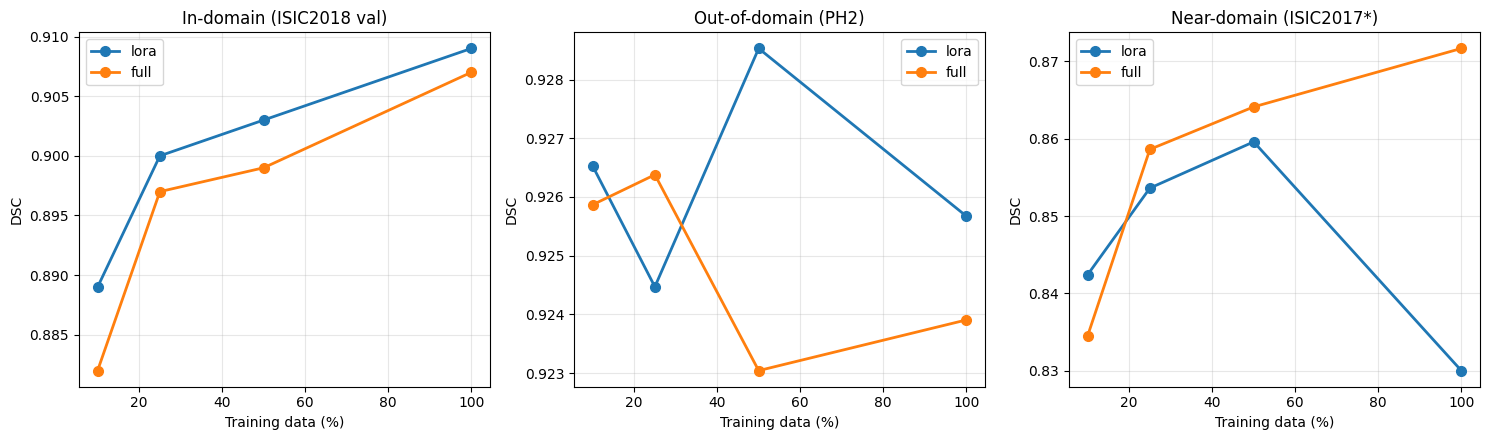

Data-size sweep (DSC):

lora:
   10%: val 0.889 | PH2 0.927 | 2017* 0.842
   25%: val 0.900 | PH2 0.924 | 2017* 0.854
   50%: val 0.903 | PH2 0.929 | 2017* 0.860
  100%: val 0.909 | PH2 0.926 | 2017* 0.830

full:
   10%: val 0.882 | PH2 0.926 | 2017* 0.834
   25%: val 0.897 | PH2 0.926 | 2017* 0.859
   50%: val 0.899 | PH2 0.923 | 2017* 0.864
  100%: val 0.907 | PH2 0.924 | 2017* 0.872


In [ ]:
@torch.no_grad()
def evaluate(m, imgs, masks):
    return eval_vec(m, imgs, masks).mean()
import numpy as np, matplotlib.pyplot as plt #to solve evaluate name difference

# sweep checkpoint tags
sweep_tags = {
    'lora': {10:'lora_f10', 25:'lora_f25', 50:'lora_f50', 100:'lora_s42'},
    'full': {10:'full_f10', 25:'full_f25', 50:'full_f50', 100:'full_s42'},
}
val_results = {  # val results already obtained (for the plot)
    'lora': {10:0.889, 25:0.900, 50:0.903, 100:0.909},
    'full': {10:0.882, 25:0.897, 50:0.899, 100:0.907},
}

def load_m(method, tag):
    m = DINOv2SegLoRA(8).to(DEVICE) if method=='lora' else DINOv2SegFull().to(DEVICE)
    m.load_state_dict(torch.load(f'{CKPT}/{tag}.pth')); m.eval(); return m

# evaluate each checkpoint on PH2 + 2016* + 2017*
fracs=[10,25,50,100]
curves = {m:{'val':[], 'ph2':[], '2017':[]} for m in ['lora','full']}
for method in ['lora','full']:
    for f in fracs:
        mdl = load_m(method, sweep_tags[method][f])
        curves[method]['val'].append(val_results[method][f])
        curves[method]['ph2'].append(evaluate(mdl, *clean_sets['PH2']))
        curves[method]['2017'].append(evaluate(mdl, *clean_sets['ISIC 2017*']))

# plot: 2 panels (in-domain val + out-of-domain PH2)
fig, ax = plt.subplots(1,3, figsize=(15,4.5))
titles = {'val':'In-domain (ISIC2018 val)','ph2':'Out-of-domain (PH2)','2017':'Near-domain (ISIC2017*)'}
for j,key in enumerate(['val','ph2','2017']):
    for method,c in curves.items():
        ax[j].plot(fracs, c[key], 'o-', label=method, linewidth=2, markersize=7)
    ax[j].set_title(titles[key]); ax[j].set_xlabel('Training data (%)'); ax[j].set_ylabel('DSC')
    ax[j].legend(); ax[j].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{CKPT}/data_sweep_curves.png', dpi=150, bbox_inches='tight'); plt.show()

# numerical summary
print("Data-size sweep (DSC):")
for method in ['lora','full']:
    print(f"\n{method}:")
    for i,f in enumerate(fracs):
        print(f"  {f:3d}%: val {curves[method]['val'][i]:.3f} | PH2 {curves[method]['ph2'][i]:.3f} | 2017* {curves[method]['2017'][i]:.3f}")

In [ ]:
import os
print("Checkpoints:")
for t in ['frozen_aug','lora_s42','lora_s123','lora_s2024','full_s42','full_s123','full_s2024',
          'lora_f10','lora_f25','lora_f50','full_f10','full_f25','full_f50']:
    print(f"  {t}:", "+" if os.path.exists(f'{CKPT}/{t}.pth') else "MISSING")
print("\nGrafikler:")
for g in ['qualitative_2017.png','qualitative_ph2_filtered.png','data_sweep_curves.png']:
    print(f"  {g}:", "+" if os.path.exists(f'{CKPT}/{g}') else "MISSING")

Checkpoint'ler:
  frozen_aug: ✓
  lora_s42: ✓
  lora_s123: ✓
  lora_s2024: ✓
  full_s42: ✓
  full_s123: ✓
  full_s2024: ✓
  lora_f10: ✓
  lora_f25: ✓
  lora_f50: ✓
  full_f10: ✓
  full_f25: ✓
  full_f50: ✓

Grafikler:
  qualitative_2017.png: YOK
  qualitative_ph2_filtered.png: ✓
  data_sweep_curves.png: ✓


ISIC 2017* — LoRA vs full FT en ayrisan ornekler:


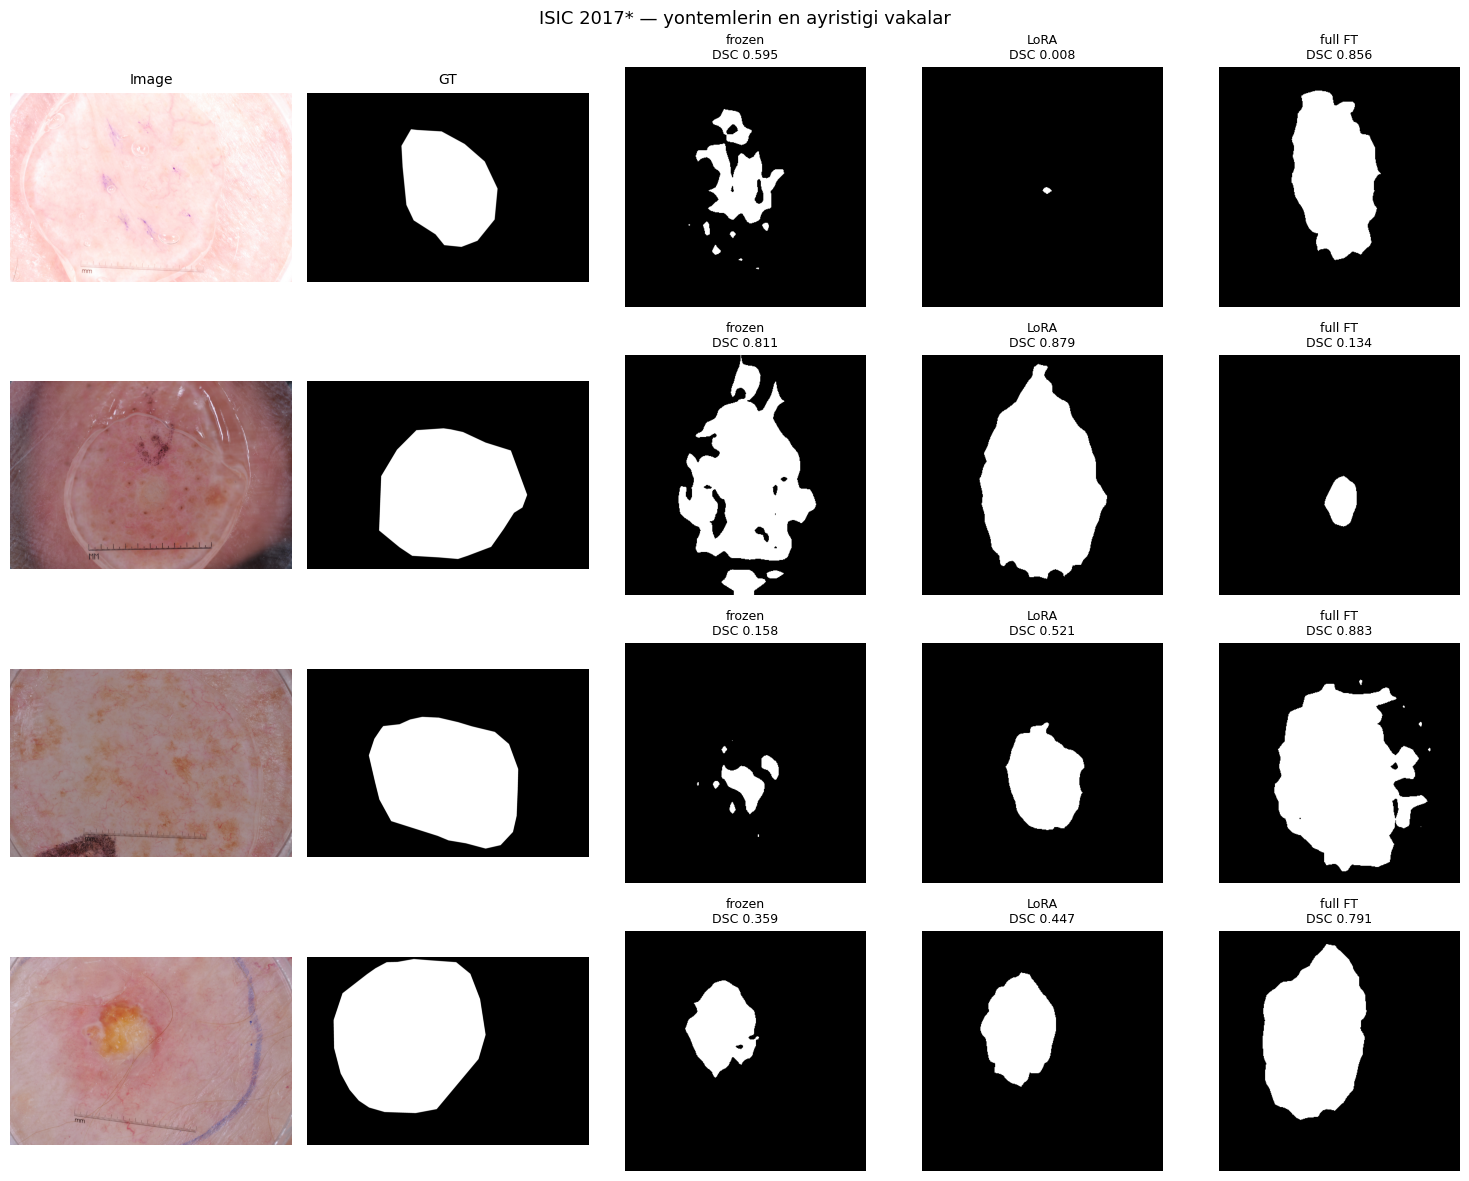

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
@torch.no_grad()
def dsc_one(m, img_path, mask_path):
    ds = ISICDataset([img_path],[mask_path],augment=False)
    x, gt = ds[0]
    with torch.amp.autocast('cuda'): lo = m(x.unsqueeze(0).to(DEVICE))
    pred = (torch.sigmoid(lo[0,0])>0.5).float().cpu()
    gt = gt[0]
    inter=(pred*gt).sum(); d=(2*inter+1e-6)/(pred.sum()+gt.sum()+1e-6)
    return d.item(), pred.numpy()

def find_divergent(imgs, masks, topk=4, by=('LoRA','full FT')):
    """Compute the LoRA vs full FT DSC difference over the whole set, return the most divergent cases."""
    name2m = {'frozen':m_frozen,'LoRA':m_lora,'full FT':m_full}
    rows=[]
    for ip, mp in zip(imgs, masks):
        d_a,_ = dsc_one(name2m[by[0]], ip, mp)
        d_b,_ = dsc_one(name2m[by[1]], ip, mp)
        rows.append((abs(d_a-d_b), d_a, d_b, ip, mp))
    rows.sort(reverse=True)   # largest difference first
    return rows[:topk]

def show_divergent(rows, title=""):
    n=len(rows)
    fig, ax = plt.subplots(n,5, figsize=(15,3*n))
    cols=['Image','GT','frozen','LoRA','full FT']
    name2m=[('frozen',m_frozen),('LoRA',m_lora),('full FT',m_full)]
    for r,(diff,da,db,ip,mp) in enumerate(rows):
        img=np.array(Image.open(ip).convert('RGB'))
        gt =np.array(Image.open(mp).convert('L'))
        ax[r,0].imshow(img); ax[r,1].imshow(gt,cmap='gray')
        for c,(nm,m) in enumerate(name2m):
            d,pred=dsc_one(m,ip,mp)
            ax[r,c+2].imshow(pred,cmap='gray'); ax[r,c+2].set_title(f"{nm}\nDSC {d:.3f}",fontsize=9)
        for c in range(5):
            ax[r,c].axis('off')
            if c<2 and r==0: ax[r,c].set_title(cols[c],fontsize=10)
        ax[r,0].set_ylabel(f"Δ={diff:.2f}",fontsize=10)
    fig.suptitle(title,fontsize=13); plt.tight_layout(); plt.show()

# ISIC 2017* — the hardest set, most divergent cases between LoRA and full FT
i17c_imgs, i17c_masks = clean_sets['ISIC 2017*']
print("ISIC 2017* — most divergent cases between LoRA and full FT:")
rows = find_divergent(i17c_imgs, i17c_masks, topk=4)
show_divergent(rows, "ISIC 2017* — cases where the methods diverge most")

PH2 (OOD) — LoRA vs full FT en ayrisan ornekler:


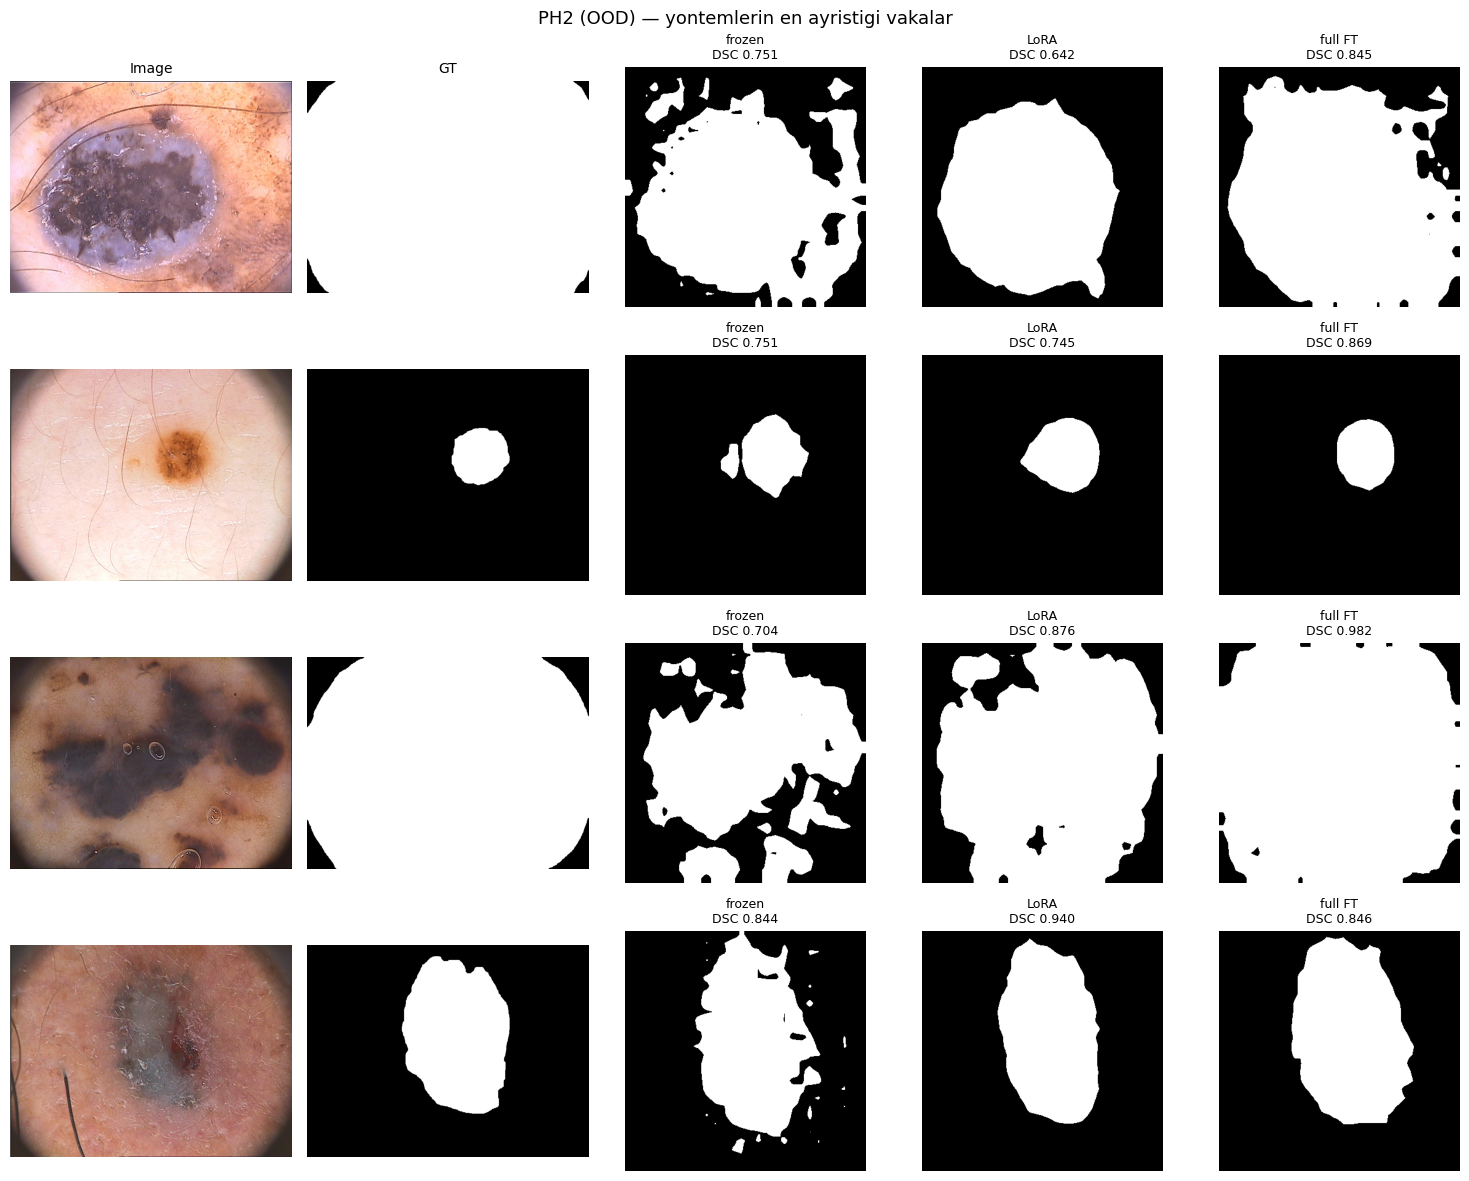

<Figure size 640x480 with 0 Axes>

In [ ]:
print("PH2 (OOD) — most divergent cases between LoRA and full FT:")
rows_ph2 = find_divergent(ph2_imgs, ph2_masks, topk=4)
show_divergent(rows_ph2, "PH2 (OOD) — cases where the methods diverge most")
plt.savefig(f'{CKPT}/qualitative_ph2.png', dpi=150, bbox_inches='tight')

In [ ]:
# check the GT of the first few PH2 pairs
for ip, mp in list(zip(ph2_imgs, ph2_masks))[:5]:
    m = np.array(Image.open(mp).convert('L'))
    print(mp.name, "| unique:", np.unique(m), "| white fraction:", (m>127).mean().round(3))

IMD002_lesion.bmp | unique: [  0 255] | beyaz oran: 0.275
IMD003_lesion.bmp | unique: [  0 255] | beyaz oran: 0.114
IMD004_lesion.bmp | unique: [  0 255] | beyaz oran: 0.194
IMD006_lesion.bmp | unique: [  0 255] | beyaz oran: 0.147
IMD008_lesion.bmp | unique: [  0 255] | beyaz oran: 0.117


In [ ]:
# inspect the PH2 cases that find_divergent selected
for diff, da, db, ip, mp in rows_ph2:
    m = np.array(Image.open(mp).convert('L'))
    print(f"Δ={diff:.3f} | img={ip.name} | mask={mp.name} | white={ (m>127).mean():.3f}")

Δ=0.203 | img=IMD424.bmp | mask=IMD424_lesion.bmp | beyaz=0.983
Δ=0.123 | img=IMD204.bmp | mask=IMD204_lesion.bmp | beyaz=0.043
Δ=0.106 | img=IMD240.bmp | mask=IMD240_lesion.bmp | beyaz=0.933
Δ=0.094 | img=IMD085.bmp | mask=IMD085_lesion.bmp | beyaz=0.218


In [ ]:
# do the image and mask names match?
mismatch = 0
for ip, mp in zip(ph2_imgs, ph2_masks):
    img_id = ip.stem                          # e.g. IMD002
    msk_id = mp.stem.replace('_lesion','')    # e.g. IMD002_lesion -> IMD002
    if img_id != msk_id:
        mismatch += 1
        if mismatch <= 5: print(f"MISMATCH: {ip.name} <-> {mp.name}")
print(f"{len(ph2_imgs)} pairs in total, {mismatch} mismatched")

toplam 200 cift, 0 kayma


PH2 (OOD) — orta boyutlu lezyonlar, LoRA vs full FT en ayrisan:


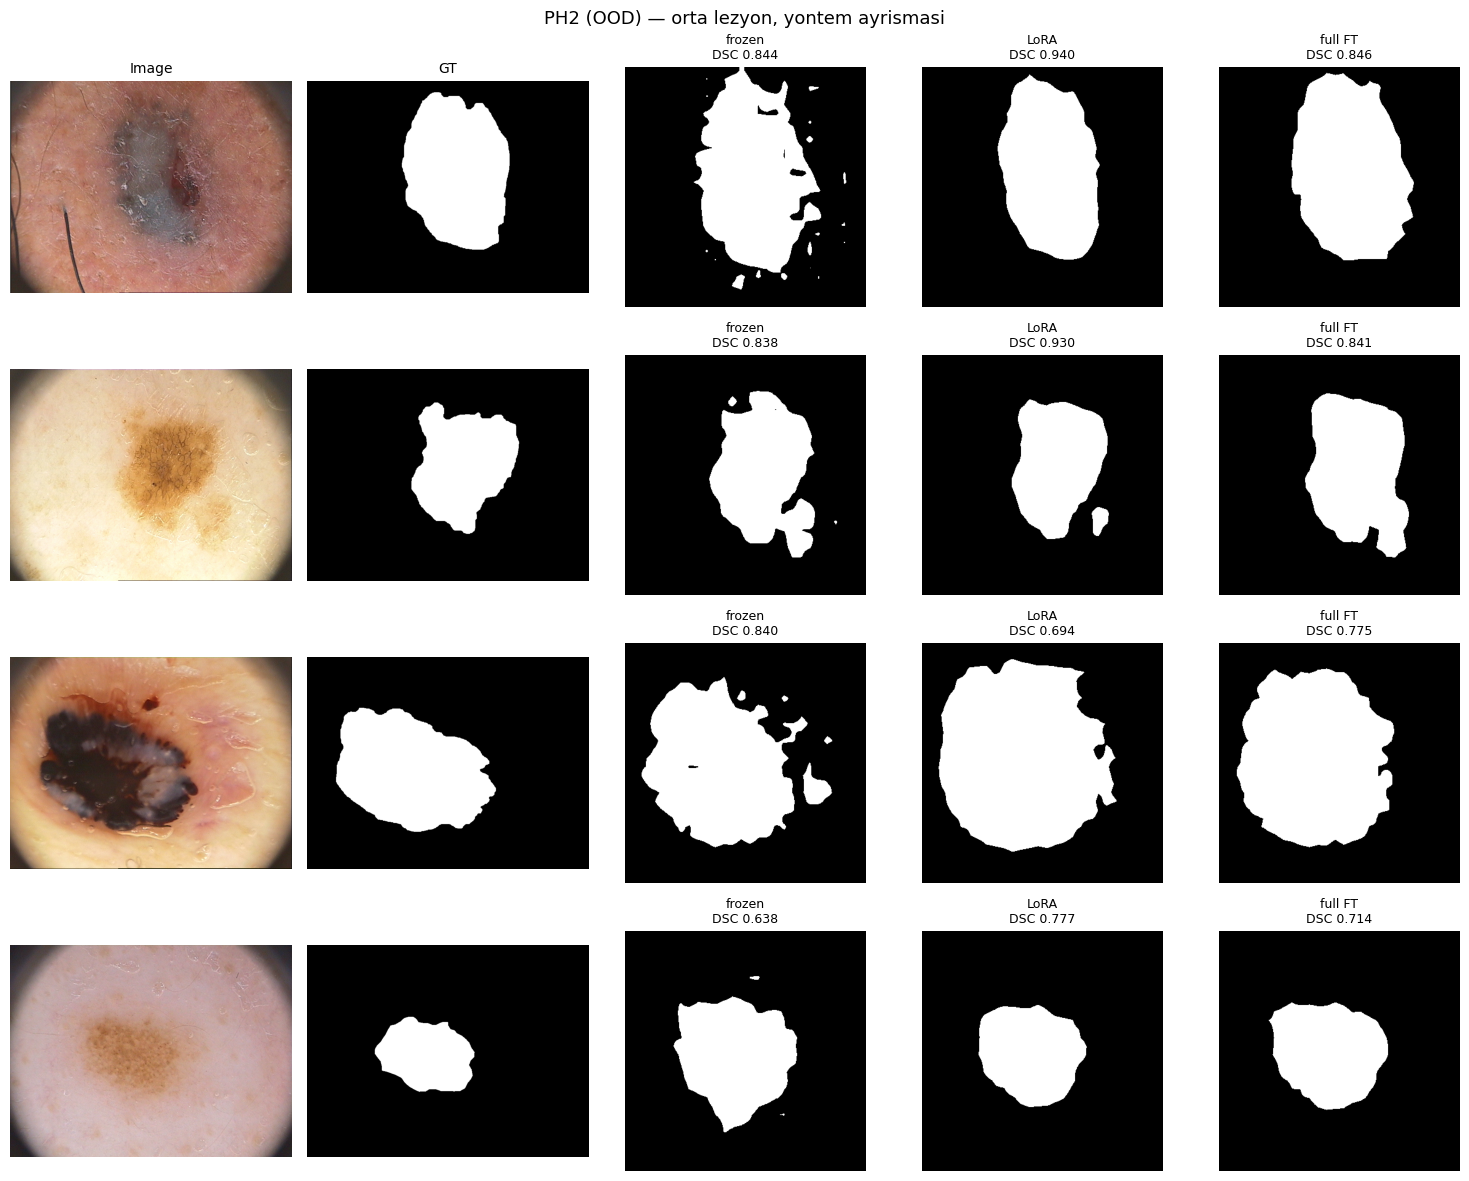

<Figure size 640x480 with 0 Axes>

In [ ]:
def find_divergent_filtered(imgs, masks, topk=4, by=('LoRA','full FT'),
                            min_lesion=0.05, max_lesion=0.5):
    """Mid-sized lesions only (drops the very large and very small extremes)."""
    name2m = {'frozen':m_frozen,'LoRA':m_lora,'full FT':m_full}
    rows=[]
    for ip, mp in zip(imgs, masks):
        gt = np.array(Image.open(mp).convert('L'))
        frac = (gt>127).mean()
        if not (min_lesion <= frac <= max_lesion):   # skip the size extremes
            continue
        d_a,_ = dsc_one(name2m[by[0]], ip, mp)
        d_b,_ = dsc_one(name2m[by[1]], ip, mp)
        rows.append((abs(d_a-d_b), d_a, d_b, ip, mp))
    rows.sort(reverse=True)
    return rows[:topk]

print("PH2 (OOD) — mid-sized lesions, most divergent between LoRA and full FT:")
rows_ph2f = find_divergent_filtered(ph2_imgs, ph2_masks, topk=4)
show_divergent(rows_ph2f, "PH2 (OOD) — mid-sized lesions, divergence between methods")
plt.savefig(f'{CKPT}/qualitative_ph2_filtered.png', dpi=150, bbox_inches='tight')

In [ ]:
fracs = [ (np.array(Image.open(mp).convert('L'))>127).mean() for mp in ph2_masks ]
fracs = np.array(fracs)
print(f"PH2 lesion fraction: mean {fracs.mean():.3f} | median {np.median(fracs):.3f}")
print(f"  >0.5 (very large): {(fracs>0.5).sum()} cases | <0.05 (very small): {(fracs<0.05).sum()} cases")

PH2 lezyon orani: ort 0.322 | medyan 0.231
  >0.5 (dev): 43 adet | <0.05 (minik): 2 adet


Extracting pretrained (reference) feats...


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Extracting frozen feats...


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Extracting lora feats...


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Extracting full feats...


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

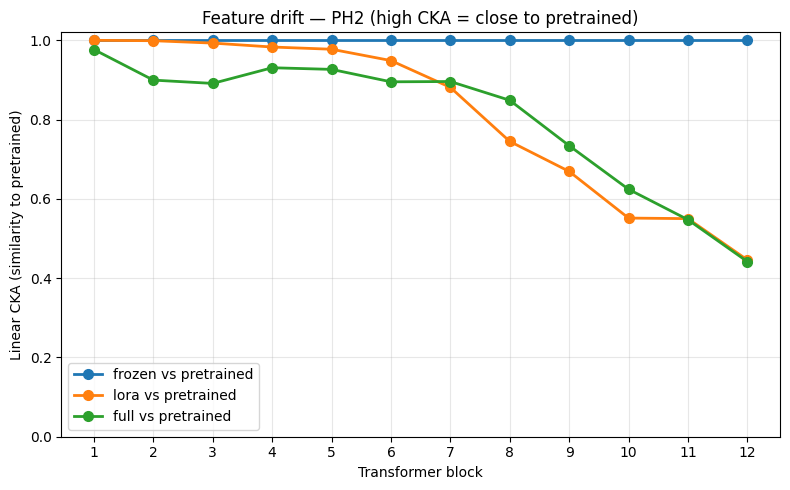


Block-wise CKA (PH2):
block |   frozen |     LoRA |     full | diff(L-F)
    1 |    1.000 |    1.000 |    0.977 |     0.023
    2 |    1.000 |    0.999 |    0.899 |     0.099
    3 |    1.000 |    0.993 |    0.891 |     0.102
    4 |    1.000 |    0.983 |    0.931 |     0.052
    5 |    1.000 |    0.977 |    0.927 |     0.051
    6 |    1.000 |    0.949 |    0.895 |     0.054
    7 |    1.000 |    0.881 |    0.896 |    -0.015
    8 |    1.000 |    0.745 |    0.849 |    -0.104
    9 |    1.000 |    0.669 |    0.734 |    -0.065
   10 |    1.000 |    0.551 |    0.624 |    -0.073
   11 |    1.000 |    0.550 |    0.547 |     0.003
   12 |    1.000 |    0.446 |    0.442 |     0.004

frozen mean CKA: 1.0000  -> ~1.0 (encoder untouched, pipeline sanity check passed)

Late blocks (9-12) mean CKA — LoRA 0.554 | full 0.587
Early blocks (1-6) mean CKA — LoRA 0.983 | full 0.920

Note: naive 'full FT drifts more everywhere' hypothesis REJECTED.
Actual pattern: LoRA preserves early blocks (late-bloc

In [ ]:
# CELL — CKA PILOT (Week 1)
# Block-wise linear CKA (debiased): pretrained vs LoRA vs full FT
# Test set: PH2 (leak-free). No training, forward pass only.
# Linear CKA: Kornblith et al. 2019 (ICML)
# Debiased HSIC estimator: Nguyen et al. 2021

import numpy as np, torch, matplotlib.pyplot as plt
from torch.utils.data import DataLoader

N_BLOCKS = 12          # DINOv2-Small
PILOT_SET = 'PH2'      # leak-free, from clean_sets
MAX_IMAGES = 200       # enough for the pilot; CKA is sample-stable

# 1) Access block outputs: auto-resolve path for frozen/LoRA/full
from peft import PeftModel

def get_blocks(model):
    """DINOv2SegFrozen/LoRA/Full -> ModuleList of encoder transformer blocks."""
    enc = model.encoder
    # Only descend into base_model.model for a real PeftModel; frozen/full are raw Dinov2Model
    core = enc.base_model.model if isinstance(enc, PeftModel) else enc
    return core.encoder.layer

# 2) Collect all block outputs via forward hooks
@torch.no_grad()
def extract_block_feats(model, imgs, masks, max_images=MAX_IMAGES):
    """
    Returns: list of N_blocks elements, each [N_images, 384]
    (CLS dropped, patch tokens mean-pooled per block).
    """
    model.eval()
    blocks = get_blocks(model)
    store = {i: [] for i in range(len(blocks))}
    handles = []
    def mk_hook(idx):
        def hook(_m, _inp, out):
            # DINOv2 layer output may be a tuple; first element is the hidden state
            h = out[0] if isinstance(out, tuple) else out   # [B, 1+N, 384]
            pooled = h[:, 1:, :].float().mean(dim=1)         # drop CLS, mean over patches -> [B, 384]
            store[idx].append(pooled.cpu())
        return hook
    for i, blk in enumerate(blocks):
        handles.append(blk.register_forward_hook(mk_hook(i)))

    ds = ISICDataset(imgs[:max_images], masks[:max_images], augment=False)
    loader = DataLoader(ds, batch_size=8, shuffle=False, num_workers=2)
    for images, _ in loader:
        with torch.amp.autocast('cuda'):
            _ = model(images.to(DEVICE))
    for h in handles: h.remove()
    return [torch.cat(store[i]).numpy() for i in range(len(blocks))]

# 3) Debiased linear CKA (Nguyen et al. 2021)
def _gram_linear(X):
    return X @ X.T

def _debiased_hsic(K, L):
    """Debiased HSIC estimator (Nguyen et al. 2021)."""
    n = K.shape[0]
    K = K.copy().astype(np.float64); L = L.copy().astype(np.float64)
    np.fill_diagonal(K, 0.0); np.fill_diagonal(L, 0.0)
    Ksum = K.sum(); Lsum = L.sum()
    KL = (K @ L).trace()
    term = KL
    term -= (K.sum(0) @ L.sum(0)) * 2.0 / (n - 2)
    term += Ksum * Lsum / ((n - 1) * (n - 2))
    return term / (n * (n - 3))

def linear_cka_debiased(X, Y):
    """X, Y: [n, d]. No centering needed (debiased HSIC handles it)."""
    K = _gram_linear(X); L = _gram_linear(Y)
    hsic_xy = _debiased_hsic(K, L)
    hsic_xx = _debiased_hsic(K, K)
    hsic_yy = _debiased_hsic(L, L)
    denom = np.sqrt(max(hsic_xx, 1e-12) * max(hsic_yy, 1e-12))
    return float(hsic_xy / denom)

# 4) Reference: untouched pretrained encoder
print("Extracting pretrained (reference) feats...")
m_pre = DINOv2SegFrozen().to(DEVICE)   # encoder = raw facebook/dinov2-small (decoder unused)
imgs_p, masks_p = clean_sets[PILOT_SET]
feats_pre = extract_block_feats(m_pre, imgs_p, masks_p)
del m_pre; torch.cuda.empty_cache()

# 5) Adapted models: frozen + LoRA + full FT
def load_for_cka(method):
    if method == 'full':
        m = DINOv2SegFull().to(DEVICE); tag = 'full_s42'
    elif method == 'lora':
        m = DINOv2SegLoRA(8).to(DEVICE); tag = 'lora_s42'
    else:  # frozen — encoder pretrained, decoder trained
        m = DINOv2SegFrozen().to(DEVICE); tag = 'frozen_aug'
    m.load_state_dict(torch.load(f'{CKPT}/{tag}.pth')); m.eval()
    return m

cka_curves = {}
for method in ['frozen', 'lora', 'full']:
    print(f"Extracting {method} feats...")
    m = load_for_cka(method)
    feats_m = extract_block_feats(m, imgs_p, masks_p)
    del m; torch.cuda.empty_cache()
    cka_curves[method] = [linear_cka_debiased(feats_pre[i], feats_m[i])
                          for i in range(N_BLOCKS)]

# 6) Result: block-wise CKA curve (similarity to pretrained)
blocks_x = list(range(1, N_BLOCKS + 1))
plt.figure(figsize=(8, 5))
for method, c in cka_curves.items():
    plt.plot(blocks_x, c, 'o-', label=f'{method} vs pretrained', linewidth=2, markersize=7)
plt.xlabel('Transformer block'); plt.ylabel('Linear CKA (similarity to pretrained)')
plt.title(f'Feature drift — {PILOT_SET} (high CKA = close to pretrained)')
plt.xticks(blocks_x); plt.ylim(0, 1.02); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{CKPT}/cka_pilot_{PILOT_SET.replace(" ","_").replace("*","")}.png',
                                dpi=150, bbox_inches='tight'); plt.show()

# 7) Numerical summary + hypothesis check
methods = ['frozen', 'lora', 'full']
print(f"\nBlock-wise CKA ({PILOT_SET}):")
print(f"{'block':>5} | {'frozen':>8} | {'LoRA':>8} | {'full':>8} | {'diff(L-F)':>9}")
for i in range(N_BLOCKS):
    fr = cka_curves['frozen'][i]
    l, f = cka_curves['lora'][i], cka_curves['full'][i]
    print(f"{i+1:>5} | {fr:>8.3f} | {l:>8.3f} | {f:>8.3f} | {l-f:>9.3f}")

# frozen sanity check
fr_mean = np.mean(cka_curves['frozen'])
print(f"\nfrozen mean CKA: {fr_mean:.4f}  ->",
      "~1.0 (encoder untouched, pipeline sanity check passed)" if fr_mean > 0.98
      else "not 1.0 — investigate")

late = slice(N_BLOCKS - 4, N_BLOCKS)   # last 4 blocks
lora_late = np.mean(cka_curves['lora'][late])
full_late = np.mean(cka_curves['full'][late])
print(f"\nLate blocks (9-12) mean CKA — LoRA {lora_late:.3f} | full {full_late:.3f}")
print(f"Early blocks (1-6) mean CKA — LoRA {np.mean(cka_curves['lora'][:6]):.3f} "
      f"| full {np.mean(cka_curves['full'][:6]):.3f}")
print("\nNote: naive 'full FT drifts more everywhere' hypothesis REJECTED.")
print("Actual pattern: LoRA preserves early blocks (late-block-concentrated drift),")
print("full FT spreads drift across depth. Pattern identical on both sets (structural signature).")

In [ ]:
# CELL — MMD: domain gap quantification (pulled forward from Week 7)
# Distribution distance between ISIC 2018 train and each test set.
# Computed on pretrained DINOv2 features (raw domain gap, pre-adaptation).
# Uses extract_block_feats and clean_sets — the CKA cell must have run.

import numpy as np, torch
from torch.utils.data import DataLoader

MMD_BLOCK = 11          # last block (0-indexed 11 = block 12), same representation as CKA
MMD_MAX   = 200         # samples per set

# pretrained encoder (no adaptation)
m_pre = DINOv2SegFrozen().to(DEVICE); m_pre.eval()

@torch.no_grad()
def set_feats(imgs, masks, max_n=MMD_MAX):
    """Last block, per-image mean-pool, L2-normalize -> [n, 384]."""
    feats = extract_block_feats(m_pre, imgs, masks, max_images=max_n)[MMD_BLOCK]
    X = feats.astype(np.float64)
    X = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-8)   # L2 normalize
    return X

# train (ISIC 2018) reference features
# train image/mask paths: img_files[tr], mask_files[tr]
train_imgs = [img_files[i] for i in tr]
train_masks = [mask_files[i] for i in tr]
print("Extracting train (ISIC 2018) feats...")
X_train = set_feats(train_imgs, train_masks)

# linear-kernel MMD^2 (unbiased)
def mmd2_linear(X, Y):
    """Unbiased MMD^2, linear kernel. X:[n,d] Y:[m,d]."""
    n, m = len(X), len(Y)
    Kxx = X @ X.T; Kyy = Y @ Y.T; Kxy = X @ Y.T
    sxx = (Kxx.sum() - np.trace(Kxx)) / (n*(n-1))
    syy = (Kyy.sum() - np.trace(Kyy)) / (m*(m-1))
    sxy = Kxy.mean()
    return sxx + syy - 2*sxy

# MMD for each test set
print(f"\nDomain gap (MMD^2, pretrained DINOv2 block {MMD_BLOCK+1}, L2-norm):")
print(f"{'set':>12} | {'MMD^2':>10} | {'n':>5}")
print('-'*34)
results = {}
for name, (im, mk) in clean_sets.items():
    Xt = set_feats(im, mk)
    d = mmd2_linear(X_train, Xt)
    results[name] = d
    print(f"{name:>12} | {d:>10.5f} | {len(Xt):>5}")

# sanity check: train against itself should be ~0
half = len(X_train)//2
self_mmd = mmd2_linear(X_train[:half], X_train[half:])
print(f"{'2018(self)':>12} | {self_mmd:>10.5f} | {half:>5}  <- should be ~0 (sanity check)")

del m_pre; torch.cuda.empty_cache()

# summary
order = sorted(results.items(), key=lambda x: x[1])
print(f"\nDistance order (near->far): " + " < ".join(f"{n}({d:.4f})" for n,d in order))

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Extracting train (ISIC 2018) feats...

Domain gap (MMD^2, pretrained DINOv2 block 12, L2-norm):
         set |      MMD^2 |     n
----------------------------------
  ISIC 2016* |    0.02159 |   200
  ISIC 2017* |    0.00700 |   172
         PH2 |    0.07390 |   200
  2018(self) |   -0.00198 |   100  <- should be ~0 (sanity check)

Distance order (near->far): ISIC 2017*(0.0070) < ISIC 2016*(0.0216) < PH2(0.0739)


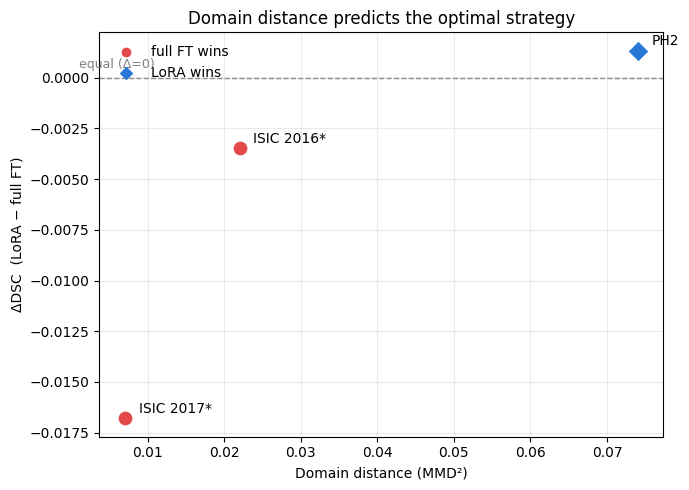

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# MMD and DSC differences
mmd  = {'ISIC 2017*': 0.007, 'ISIC 2016*': 0.022, 'PH2': 0.074}
ddsc = {d: mean_vec['lora'][d].mean() - mean_vec['full'][d].mean() for d in mmd}

fig, ax = plt.subplots(figsize=(7, 5))
for d in mmd:
    win_lora = ddsc[d] > 0
    ax.scatter(mmd[d], ddsc[d], s=130,
               color='#2a78d6' if win_lora else '#e34948',
               marker='D' if win_lora else 'o', zorder=3,
               edgecolor='white', linewidth=1.5)
    ax.annotate(d, (mmd[d], ddsc[d]), textcoords='offset points',
                xytext=(10, 4), fontsize=10)
ax.axhline(0, ls='--', color='gray', lw=1, zorder=1)
ax.text(0.001, 0.0005, 'equal (Δ=0)', color='gray', fontsize=9)
ax.set_xlabel('Domain distance (MMD²)')
ax.set_ylabel('ΔDSC  (LoRA − full FT)')
ax.set_title('Domain distance predicts the optimal strategy')
ax.scatter([], [], color='#e34948', marker='o', label='full FT wins')
ax.scatter([], [], color='#2a78d6', marker='D', label='LoRA wins')
ax.legend(loc='upper left', frameon=False)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(f'{CKPT}/strategy_vs_mmd.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
#14.1
# Rank sweep + DoRA: DoRA-capable LoRA model
# EXTENDS the existing DINOv2SegLoRA: adds a use_dora flag.
# use_dora=False -> exactly the current behaviour (backwards compatible).
# WHY extend rather than write a separate class: same forward/decoder, the only
# difference is the PEFT config.
from peft import LoraConfig, get_peft_model

class DINOv2SegLoRAx(nn.Module):
    """DINOv2-Small + LinearDecoder adapted with LoRA or DoRA.
    target_modules parametric: rank sweep + target-module sweep use same class."""
    def __init__(self, rank=8, use_dora=False, target_modules=('query','value')):
        super().__init__()
        enc = AutoModel.from_pretrained('facebook/dinov2-small')
        cfg = LoraConfig(
            r=rank,
            lora_alpha=rank*2,                    # alpha=2r held fixed (standard practice)
            target_modules=list(target_modules),
            lora_dropout=0.1,
            bias='none',
            use_dora=use_dora,                    # <-- the only difference: the DoRA switch
        )
        self.encoder = get_peft_model(enc, cfg)
        self.decoder = LinearDecoder(384)
    def forward(self, x):
        out = self.encoder(pixel_values=x)
        return self.decoder(out.last_hidden_state[:, 1:, :])

# Quick check: parameter counts should rise with rank, and DoRA should be slightly higher
for r in [4, 8]:
    for dora in [False, True]:
        m_ = DINOv2SegLoRAx(rank=r, use_dora=dora)
        n_tr = sum(p.numel() for p in m_.parameters() if p.requires_grad)
        print(f"r={r:2d} dora={dora!s:5s} -> trainable params: {n_tr:,}")
        del m_

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

r= 4 dora=False -> trainable params: 74,113


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

r= 4 dora=True  -> trainable params: 83,329


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

r= 8 dora=False -> trainable params: 147,841


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

r= 8 dora=True  -> trainable params: 157,057


In [ ]:
for variant, dora in [('lora',False),('dora',True)]:
    for r in [4,8,16,32]:
        m = DINOv2SegLoRAx(rank=r, use_dora=dora)
        print(f"{variant} r={r:2d}: {sum(p.numel() for p in m.parameters() if p.requires_grad):,}")
        del m
print(f"full FT: {sum(p.numel() for p in DINOv2SegFull().parameters() if p.requires_grad):,}")

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

lora r= 4: 74,113


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

lora r= 8: 147,841


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

lora r=16: 295,297


... (8 outputs left out)

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

dora r=32: 599,425


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

full FT: 22,056,961


In [ ]:
#14.2
# PHASE 1: Rank sweep (r=4/8/16/32) x {LoRA, DoRA}
# The "how much capacity" axis. target_modules fixed at Q+V (the current default).
# DoRA piggybacks on every rank: NO separate loop, use_dora toggled inside the same loop.
# 1 seed (SIGNAL). If the signal is meaningful, extend to 3 seeds and turn it into EVIDENCE.
import os, numpy as np

RANKS = [4, 8, 16, 32]
VARIANTS = [('lora', False), ('dora', True)]   # (label, use_dora)
SWEEP_SEED = 42                                 # same seed as multi-seed s42

def set_seed(s):
    import random; random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

# IMPORTANT: train_loader must be the current FULL-data augmented loader.
# If the data-size sweep (cell 16) has run, train_loader may be set to a % subset.
# Restore the full loader to be safe:
train_loader = DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=8, pin_memory=True, persistent_workers=True,
                          prefetch_factor=4)
print(f"train_loader reset -> full data, n={len(train_ds_aug)}")

rank_sweep = {}
for variant, use_dora in VARIANTS:
    for r in RANKS:
        tag = f'{variant}_r{r}_s{SWEEP_SEED}'
        if os.path.exists(f'{CKPT}/{tag}.pth'):
            rank_sweep[(variant, r)] = {'tag': tag}
            print(f"SKIP {tag} (already existing)"); continue

        set_seed(SWEEP_SEED)
        print(f"\n{'='*45}\n{variant.upper()} | rank={r} | Q+V | seed {SWEEP_SEED}\n{'='*45}")
        m = DINOv2SegLoRAx(rank=r, use_dora=use_dora,
                           target_modules=('query','value')).to(DEVICE)
        opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad],
                                lr=1e-4, weight_decay=1e-4)
        b, _ = train_model(m, opt, tag, total_ep=20, warmup_ep=2, patience=5)
        rank_sweep[(variant, r)] = {'tag': tag, 'val': b}
        print(f"  {variant} r={r}: val {b:.4f}")
        del m, opt; torch.cuda.empty_cache()

print("\n Phase 1 (rank sweep + DoRA) DONE")
for k, v in rank_sweep.items():
    print(k, f"val {v.get('val', 'skip')}")

# shutting the GPU down
from google.colab import runtime
print("Runtime unassigning..."); runtime.unassign()

train_loader reset -> full data, n=2075
SKIP lora_r4_s42 (already existing)
SKIP lora_r8_s42 (already existing)
SKIP lora_r16_s42 (already existing)
SKIP lora_r32_s42 (already existing)
SKIP dora_r4_s42 (already existing)
SKIP dora_r8_s42 (already existing)

DORA | rank=16 | Q+V | seed 42


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/260
  b80/260
  b160/260
  b240/260
E 1 | train 0.773 | val 0.882 iou 0.805  *
  b0/260
  b80/260
  b160/260
  b240/260
E 2 | train 0.884 | val 0.895 iou 0.823  *
  b0/260
  b80/260
  b160/260
  b240/260
E 3 | train 0.894 | val 0.892 iou 0.824
  b0/260
  b80/260
  b160/260
  b240/260
E 4 | train 0.902 | val 0.904 iou 0.836  *
  b0/260
  b80/260
  b160/260
  b240/260
E 5 | train 0.906 | val 0.900 iou 0.829
  b0/260
  b80/260
  b160/260
  b240/260
E 6 | train 0.908 | val 0.904 iou 0.837
  b0/260
  b80/260
  b160/260
  b240/260
E 7 | train 0.911 | val 0.907 iou 0.841  *
  b0/260
  b80/260
  b160/260
  b240/260
E 8 | train 0.914 | val 0.906 iou 0.839
  b0/260
  b80/260
  b160/260
  b240/260
E 9 | train 0.917 | val 0.908 iou 0.843  *
  b0/260
  b80/260
  b160/260
  b240/260
E10 | train 0.919 | val 0.909 iou 0.844  *
  b0/260
  b80/260
  b160/260
  b240/260
E11 | train 0.920 | val 0.910 iou 0.844  *
  b0/260
  b80/260
  b160/260
  b240/260
E12 | train 0.922 | val 0.909 iou 0.842
  b0/26

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/260
  b80/260
  b160/260
  b240/260
E 1 | train 0.808 | val 0.888 iou 0.815  *
  b0/260
  b80/260
  b160/260
  b240/260
E 2 | train 0.890 | val 0.894 iou 0.824  *
  b0/260
  b80/260
  b160/260
  b240/260
E 3 | train 0.900 | val 0.891 iou 0.823
  b0/260
  b80/260
  b160/260
  b240/260
E 4 | train 0.905 | val 0.903 iou 0.836  *
  b0/260
  b80/260
  b160/260
  b240/260
E 5 | train 0.910 | val 0.905 iou 0.837  *
  b0/260
  b80/260
  b160/260
  b240/260
E 6 | train 0.912 | val 0.911 iou 0.847  *
  b0/260
  b80/260
  b160/260
  b240/260
E 7 | train 0.916 | val 0.906 iou 0.841
  b0/260
  b80/260
  b160/260
  b240/260
E 8 | train 0.918 | val 0.908 iou 0.844
  b0/260
  b80/260
  b160/260
  b240/260
E 9 | train 0.923 | val 0.910 iou 0.846
  b0/260
  b80/260
  b160/260
  b240/260
E10 | train 0.925 | val 0.909 iou 0.845
  b0/260
  b80/260
  b160/260
  b240/260
E11 | train 0.927 | val 0.911 iou 0.847  *
  b0/260
  b80/260
  b160/260
  b240/260
E12 | train 0.928 | val 0.909 iou 0.845
  b0/260
 

In [ ]:
import os

print(" RANK SWEEP CHECKPOINT STATUS\n")
found = []
for variant in ['lora', 'dora']:
    for r in [4, 8, 16, 32]:
        tag = f'{variant}_r{r}_s42'
        p = f'{CKPT}/{tag}.pth'
        exists = os.path.exists(p)
        if exists:
            size_mb = os.path.getsize(p) / 1e6
            print(f"  {tag:16s}: found    ({size_mb:.1f} MB)")
            found.append(tag)
        else:
            print(f"  {tag:16s}: missing")

print(f"\nTotal: {len(found)}/8 configs saved")
print(f"Remaining: {8 - len(found)} configs")

=== RANK SWEEP CHECKPOINT DURUMU ===

  lora_r4_s42     : VAR  (88.7 MB)
  lora_r8_s42     : VAR  (89.0 MB)
  lora_r16_s42    : VAR  (89.6 MB)
  lora_r32_s42    : VAR  (90.7 MB)
  dora_r4_s42     : VAR  (88.7 MB)
  dora_r8_s42     : VAR  (89.0 MB)
  dora_r16_s42    : VAR  (89.6 MB)
  dora_r32_s42    : VAR  (90.8 MB)

Toplam: 8/8 config kaydedilmiş
Kalan: 0 config


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

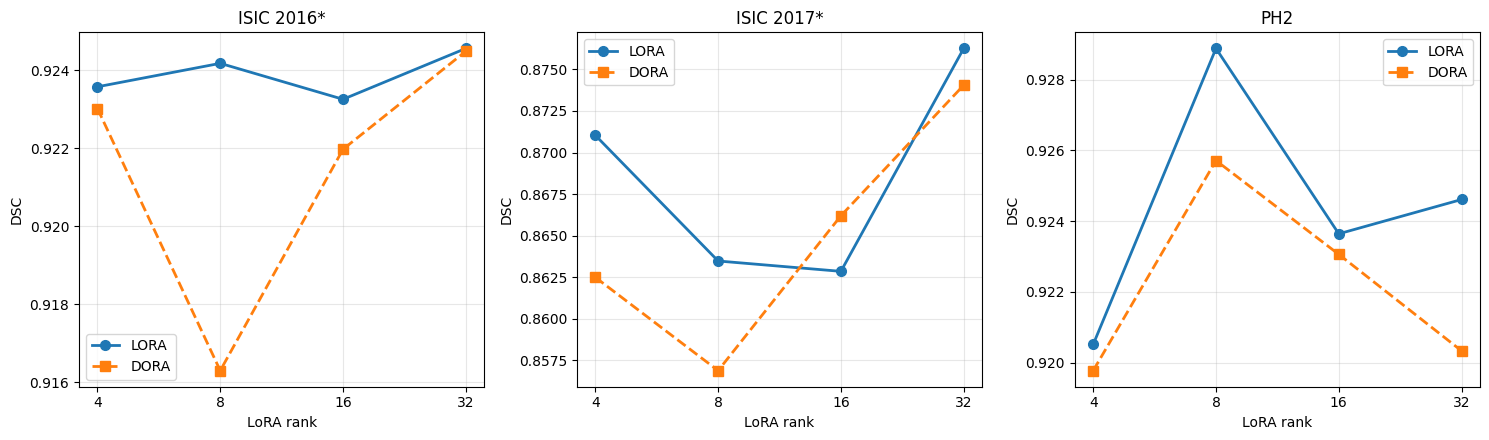

Rank sweep (DSC, 1 seed):

LORA:
rank |  ISIC 2016* |  ISIC 2017* |         PH2
----------------------------------------------
   4 |       0.924 |       0.871 |       0.921
   8 |       0.924 |       0.863 |       0.929
  16 |       0.923 |       0.863 |       0.924
  32 |       0.925 |       0.876 |       0.925

DORA:
rank |  ISIC 2016* |  ISIC 2017* |         PH2
----------------------------------------------
   4 |       0.923 |       0.862 |       0.920
   8 |       0.916 |       0.857 |       0.926
  16 |       0.922 |       0.866 |       0.923
  32 |       0.924 |       0.874 |       0.920

[consistency] lora r=8 rank-sweep: {'ISIC 2016*': np.float32(0.924), 'ISIC 2017*': np.float32(0.863), 'PH2': np.float32(0.929)}


In [ ]:
#14.3
# PHASE 1 EVAL: rank sweep curves (x=rank, y=DSC, one curve per domain)
# THE MAIN FIGURE. Hypothesis: high rank wins on the near domain, low rank is
# sufficient or better on the far domain -> the capacity optimum shifts with
# domain distance.
import numpy as np, matplotlib.pyplot as plt

SWEEP_SEED = 42
RANKS = [4, 8, 16, 32]

def load_lorax(tag, rank, use_dora, target_modules=('query','value')):
    m = DINOv2SegLoRAx(rank=rank, use_dora=use_dora,
                       target_modules=target_modules).to(DEVICE)
    m.load_state_dict(torch.load(f'{CKPT}/{tag}.pth')); m.eval(); return m

# clean_sets is defined in cell 14: {'ISIC 2016*','ISIC 2017*','PH2'}
# Note: PH2 is saturated (ceiling ~0.92) -> the curves may flatten there; the
# in-domain sets (2016*/2017*) are where separation should show.
RANKS = [4, 8, 16, 32]
domains = list(clean_sets.keys())

# rank_curves[variant][domain] = [DSC against rank]
rank_curves = {v: {d: [] for d in domains} for v in ['lora', 'dora']}
for variant, use_dora in [('lora', False), ('dora', True)]:
    for r in RANKS:
        tag = f'{variant}_r{r}_s{SWEEP_SEED}'
        mdl = load_lorax(tag, r, use_dora)
        for d in domains:
            dsc = eval_vec(mdl, *clean_sets[d]).mean()   # eval_vec from cell 14
            rank_curves[variant][d].append(dsc)
        del mdl; torch.cuda.empty_cache()

# Figure: one panel per domain, LoRA vs DoRA as two curves, x=rank
fig, ax = plt.subplots(1, len(domains), figsize=(5*len(domains), 4.5), sharey=False)
for j, d in enumerate(domains):
    for variant, style in [('lora', 'o-'), ('dora', 's--')]:
        ax[j].plot(RANKS, rank_curves[variant][d], style, label=variant.upper(),
                   linewidth=2, markersize=7)
    ax[j].set_xscale('log', base=2); ax[j].set_xticks(RANKS)
    ax[j].get_xaxis().set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
    ax[j].set_title(d); ax[j].set_xlabel('LoRA rank'); ax[j].set_ylabel('DSC')
    ax[j].legend(); ax[j].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{CKPT}/rank_sweep_curves.png', dpi=150, bbox_inches='tight'); plt.show()

# Numerical summary
print("Rank sweep (DSC, 1 seed):")
for variant in ['lora', 'dora']:
    print(f"\n{variant.upper()}:")
    header = "rank | " + " | ".join(f"{d:>11s}" for d in domains)
    print(header); print('-'*len(header))
    for i, r in enumerate(RANKS):
        row = " | ".join(f"{rank_curves[variant][d][i]:>11.3f}" for d in domains)
        print(f"{r:4d} | {row}")

# Consistency check: dora r=8 vs the existing multi-seed lora s42
# (same seed, same protocol -> lora r=8 in rank_curves should be close to ms r=8)
print("\n[consistency] lora r=8 rank-sweep:",
      {d: round(rank_curves['lora'][d][RANKS.index(8)], 3) for d in domains})

NOTE: assumes the out-projection is called 'dense'. If not, target_modules comes back empty and LoRA attaches to nothing - no error. Checked below.

In [ ]:
enc = AutoModel.from_pretrained('facebook/dinov2-small')
names = set()
for n, _ in enc.named_modules():
    if any(k in n for k in ['query','key','value','dense','proj','out']):
        names.add(n.split('.')[-1])
print("Attention-related module names:", sorted(names))

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Attention-related module names: ['dense', 'dropout', 'key', 'output', 'projection', 'query', 'value']


In [ ]:
from transformers import AutoModel
enc = AutoModel.from_pretrained('facebook/dinov2-small')

# Show the FULL module paths of the first transformer block
print(" Linear layers inside block 0 (full paths)")
for n, m in enc.named_modules():
    if isinstance(m, torch.nn.Linear) and 'layer.0.' in n:
        print(f"  {n:55s} {tuple(m.weight.shape)}")

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

=== Block 0 icindeki Linear katmanlar (tam yol) ===
  encoder.layer.0.attention.attention.query               (384, 384)
  encoder.layer.0.attention.attention.key                 (384, 384)
  encoder.layer.0.attention.attention.value               (384, 384)
  encoder.layer.0.attention.output.dense                  (384, 384)
  encoder.layer.0.mlp.fc1                                 (1536, 384)
  encoder.layer.0.mlp.fc2                                 (384, 1536)


In [ ]:
# PHASE 2: Target module sweep (OFAT — at the best rank)
# The "where to adapt" axis. BEST_RANK from Phase 1 is held fixed and only
# target_modules changes: Q+V (current) vs Q+K+V+O (full attention).
# WHY OFAT: once capacity is optimised, investigate placement on a separate axis.
import os, numpy as np

# Choose MANUALLY from the Phase 1 result (best/plateau rank on in-domain val).
# Example: if the curves plateau at r=8, set BEST_RANK=8 (extra capacity is wasted).
BEST_RANK = 8            # <-- update after looking at the Phase 1 curves

MODULE_SETS = {
    'QV':   ('query', 'value'),                         # current default
    'QKVO': ('query', 'key', 'value', 'dense'),         # full attention (out proj = 'dense')
}
SWEEP_SEED = 42

def set_seed(s):
    import random; random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

# make sure the full loader is in place
train_loader = DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True)

tm_sweep = {}
for name, mods in MODULE_SETS.items():
    tag = f'lora_r{BEST_RANK}_{name}_s{SWEEP_SEED}'
    # QV already exists from Phase 1 as lora_r{BEST_RANK}_s42 -> reuse it
    if name == 'QV':
        src = f'{CKPT}/lora_r{BEST_RANK}_s{SWEEP_SEED}.pth'
        if os.path.exists(src):
            tm_sweep[name] = {'tag': f'lora_r{BEST_RANK}_s{SWEEP_SEED}', 'mods': mods}
            print(f"SKIP {name} -> lora_r{BEST_RANK}_s{SWEEP_SEED} (From Phase 1)"); continue
    if os.path.exists(f'{CKPT}/{tag}.pth'):
        tm_sweep[name] = {'tag': tag, 'mods': mods}
        print(f"SKIP {tag} (already existing)"); continue

    set_seed(SWEEP_SEED)
    print(f"\n{'='*45}\nLoRA r={BEST_RANK} | modules={name} {mods}\n{'='*45}")
    m = DINOv2SegLoRAx(rank=BEST_RANK, use_dora=False,
                       target_modules=mods).to(DEVICE)
    opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad],
                            lr=1e-4, weight_decay=1e-4)
    b, _ = train_model(m, opt, tag, total_ep=20, warmup_ep=2, patience=5)
    tm_sweep[name] = {'tag': tag, 'mods': mods, 'val': b}
    del m, opt; torch.cuda.empty_cache()

# --- Eval: compare the two module sets across the 3 domains ---
print("\nTarget-module sweep (DSC, r={}, 1 seed):".format(BEST_RANK))
domains = list(clean_sets.keys())
header = f"{'modules':8s} | " + " | ".join(f"{d:>11s}" for d in domains)
print(header); print('-'*len(header))
for name in MODULE_SETS:
    mdl = DINOv2SegLoRAx(rank=BEST_RANK, use_dora=False,
                         target_modules=tm_sweep[name]['mods']).to(DEVICE)
    mdl.load_state_dict(torch.load(f"{CKPT}/{tm_sweep[name]['tag']}.pth")); mdl.eval()
    row = " | ".join(f"{eval_vec(mdl, *clean_sets[d]).mean():>11.3f}" for d in domains)
    print(f"{name:8s} | {row}")
    del mdl; torch.cuda.empty_cache()

from google.colab import runtime
print("\nRuntime unassigning..."); runtime.unassign()

SKIP QV -> lora_r8_s42 (From Phase 1)

LoRA r=8 | modules=QKVO ('query', 'key', 'value', 'dense')


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/260
  b80/260
  b160/260
  b240/260
E 1 | train 0.775 | val 0.883 iou 0.807  *
  b0/260
  b80/260
  b160/260
  b240/260
E 2 | train 0.888 | val 0.895 iou 0.824  *
  b0/260
  b80/260
  b160/260
  b240/260
E 3 | train 0.898 | val 0.889 iou 0.813
  b0/260
  b80/260
  b160/260
  b240/260
E 4 | train 0.902 | val 0.904 iou 0.837  *
  b0/260
  b80/260
  b160/260
  b240/260
E 5 | train 0.907 | val 0.902 iou 0.835
  b0/260
  b80/260
  b160/260
  b240/260
E 6 | train 0.909 | val 0.902 iou 0.835
  b0/260
  b80/260
  b160/260
  b240/260
E 7 | train 0.912 | val 0.904 iou 0.838  *
  b0/260
  b80/260
  b160/260
  b240/260
E 8 | train 0.914 | val 0.906 iou 0.838  *
  b0/260
  b80/260
  b160/260
  b240/260
E 9 | train 0.918 | val 0.910 iou 0.846  *
  b0/260
  b80/260
  b160/260
  b240/260
E10 | train 0.921 | val 0.909 iou 0.844
  b0/260
  b80/260
  b160/260
  b240/260
E11 | train 0.921 | val 0.909 iou 0.844
  b0/260
  b80/260
  b160/260
  b240/260
E12 | train 0.922 | val 0.909 iou 0.842
  b0/260
 

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

QV       |       0.924 |       0.863 |       0.929


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

QKVO     |       0.922 |       0.869 |       0.924

Runtime unassigning...


In [ ]:
print('DINOv2SegLoRAx' in dir(), 'set_seed' in dir(), 'train_model' in dir(),
      'clean_sets' in dir(), 'eval_vec' in dir(), 'build_llrd_params' in dir(),
      'DINOv2SegFull' in dir())

True True True True True True True


In [ ]:
# LoRA r=32 — MULTI-SEED (3 seeds) + Wilcoxon vs full FT
# Purpose: is r=32's single-seed edge real or chance?
# In polyp, rank flipped the result (r=8 full FT, r=32 LoRA) — same in skin?
# Training settings IDENTICAL to r=8 multi-seed (symmetry required):
#   lr=1e-4, wd=1e-4, total_ep=20, warmup_ep=2, patience=5, augmented loader
# Only difference: rank=32

import os, numpy as np, torch
from scipy.stats import wilcoxon

SEEDS = [42, 123, 2024]
R32 = 32

def train_lora_r32(seed):
    set_seed(seed)                                  # set_seed from cell 14
    tag = f'lora_r32_s{seed}'
    m = DINOv2SegLoRAx(rank=R32).to(DEVICE)         # use_dora=False, target=('query','value')
    opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad],
                            lr=1e-4, weight_decay=1e-4)      # same as r=8
    b, _ = train_model(m, opt, tag, total_ep=20, warmup_ep=2, patience=5)  # same as r=8
    del m; torch.cuda.empty_cache()
    return tag, b

#  1) Train missing seeds (skip s42 if it already exists)
print("="*55, "\nLoRA r=32 multi-seed training\n", "="*55)
for seed in SEEDS:
    tag = f'lora_r32_s{seed}'
    if os.path.exists(f'{CKPT}/{tag}.pth'):
        print(f"SKIP {tag} (already exists)"); continue
    print(f"\n--- {tag} ---")
    t, val = train_lora_r32(seed)
    print(f"  {t}: val {val:.4f}")

#  2) Evaluation: per-image DSC vectors, 3 seeds
def load_r32(seed):
    m = DINOv2SegLoRAx(rank=R32).to(DEVICE)
    m.load_state_dict(torch.load(f'{CKPT}/lora_r32_s{seed}.pth')); m.eval(); return m

def load_full(seed):
    m = DINOv2SegFull().to(DEVICE)
    m.load_state_dict(torch.load(f'{CKPT}/full_s{seed}.pth')); m.eval(); return m

vecs32 = {'lora_r32': {d: [] for d in clean_sets},
          'full':     {d: [] for d in clean_sets}}

for seed in SEEDS:
    m = load_r32(seed)
    for d, (im, mk) in clean_sets.items():
        vecs32['lora_r32'][d].append(eval_vec(m, im, mk))
    del m; torch.cuda.empty_cache()

    m = load_full(seed)
    for d, (im, mk) in clean_sets.items():
        vecs32['full'][d].append(eval_vec(m, im, mk))
    del m; torch.cuda.empty_cache()

# seed-averaged per-image vector (for Wilcoxon — same as r=8 mean_vec logic)
mean_vec32 = {meth: {d: np.mean(np.stack(vecs32[meth][d]), axis=0) for d in clean_sets}
              for meth in ['lora_r32', 'full']}

#  3) mean +/- std table
print("\n" + "="*70)
print("LoRA r=32 vs FULL FT — MULTI-SEED (mean +/- std across 3 seeds)")
print("="*70)
print(f"{'':10s} | " + " | ".join(f"{d:>14s}" for d in clean_sets))
print('-'*60)
for meth in ['lora_r32', 'full']:
    row = []
    for d in clean_sets:
        a = np.array([v.mean() for v in vecs32[meth][d]])
        row.append(f"{a.mean():.3f}+/-{a.std():.3f}")
    print(f"{meth:10s} | " + " | ".join(f"{r:>14s}" for r in row))

#  4) Wilcoxon (same format as r=8 table)
print(f"\nWilcoxon (LoRA r=32 vs full FT, per-image DSC averaged over 3 seeds):")
print(f"{'set':>12} | {'LoRA r32':>9} | {'full':>7} | {'delta':>7} | {'p':>7} | winner")
print('-'*70)
for d in clean_sets:
    a = mean_vec32['lora_r32'][d]; b = mean_vec32['full'][d]
    n = min(len(a), len(b))
    stat, p = wilcoxon(a[:n], b[:n])
    delta = a[:n].mean() - b[:n].mean()
    win = 'LoRA' if delta > 0 else 'full'
    sig = f"(sig, {win} leads)" if p < 0.05 else "(n.s.)"
    print(f"{d:>12} | {a.mean():>9.3f} | {b.mean():>7.3f} | {delta:>+7.3f} | {p:>7.4f} | {sig}")

#5) Comparison with r=8 (hypothesis check)
print("\n" + "-"*70)
print("COMPARISON — r=8 (existing) vs r=32 (new), delta = LoRA - full:")
r8_ref = {'ISIC 2016*': 0.917-0.921, 'ISIC 2017*': 0.857-0.874, 'PH2': 0.923-0.921}
print(f"{'set':>12} | {'r=8 delta':>10} | {'r=32 delta':>11} | did rank flip?")
print('-'*70)
for d in clean_sets:
    d32 = mean_vec32['lora_r32'][d].mean() - mean_vec32['full'][d].mean()
    d8 = r8_ref.get(d, float('nan'))
    flip = "YES (full -> LoRA)" if (d8 < 0 and d32 > 0) else \
           "YES (LoRA -> full)" if (d8 > 0 and d32 < 0) else "no"
    print(f"{d:>12} | {d8:>+10.3f} | {d32:>+11.3f} | {flip}")
print("\nPolyp finding: at r=8 full FT leads, at r=32 LoRA wins.")
print("If skin shows the same pattern -> rank modulates the domain-strategy")
print("relationship (strong finding).")

LoRA r=32 multi-seed training
SKIP lora_r32_s42 (already exists)

--- lora_r32_s123 ---


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/260
  b80/260
  b160/260
  b240/260
E 1 | train 0.786 | val 0.889 iou 0.818  *
  b0/260
  b80/260
  b160/260
  b240/260
E 2 | train 0.888 | val 0.888 iou 0.818
  b0/260
  b80/260
  b160/260
  b240/260
E 3 | train 0.898 | val 0.897 iou 0.831  *
  b0/260
  b80/260
  b160/260
  b240/260
E 4 | train 0.902 | val 0.904 iou 0.838  *
  b0/260
  b80/260
  b160/260
  b240/260
E 5 | train 0.908 | val 0.905 iou 0.838  *
  b0/260
  b80/260
  b160/260
  b240/260
E 6 | train 0.911 | val 0.905 iou 0.840  *
  b0/260
  b80/260
  b160/260
  b240/260
E 7 | train 0.913 | val 0.902 iou 0.836
  b0/260
  b80/260
  b160/260
  b240/260
E 8 | train 0.916 | val 0.904 iou 0.838
  b0/260
  b80/260
  b160/260
  b240/260
E 9 | train 0.922 | val 0.909 iou 0.843  *
  b0/260
  b80/260
  b160/260
  b240/260
E10 | train 0.922 | val 0.909 iou 0.843
  b0/260
  b80/260
  b160/260
  b240/260
E11 | train 0.924 | val 0.906 iou 0.842
  b0/260
  b80/260
  b160/260
  b240/260
E12 | train 0.926 | val 0.906 iou 0.841
  b0/260
 

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/260
  b80/260
  b160/260
  b240/260
E 1 | train 0.798 | val 0.883 iou 0.810  *
  b0/260
  b80/260
  b160/260
  b240/260
E 2 | train 0.889 | val 0.892 iou 0.821  *
  b0/260
  b80/260
  b160/260
  b240/260
E 3 | train 0.899 | val 0.905 iou 0.838  *
  b0/260
  b80/260
  b160/260
  b240/260
E 4 | train 0.904 | val 0.899 iou 0.830
  b0/260
  b80/260
  b160/260
  b240/260
E 5 | train 0.908 | val 0.904 iou 0.837
  b0/260
  b80/260
  b160/260
  b240/260
E 6 | train 0.909 | val 0.903 iou 0.838
  b0/260
  b80/260
  b160/260
  b240/260
E 7 | train 0.912 | val 0.906 iou 0.842  *
  b0/260
  b80/260
  b160/260
  b240/260
E 8 | train 0.917 | val 0.908 iou 0.844  *
  b0/260
  b80/260
  b160/260
  b240/260
E 9 | train 0.921 | val 0.908 iou 0.843
  b0/260
  b80/260
  b160/260
  b240/260
E10 | train 0.924 | val 0.909 iou 0.845  *
  b0/260
  b80/260
  b160/260
  b240/260
E11 | train 0.925 | val 0.908 iou 0.843
  b0/260
  b80/260
  b160/260
  b240/260
E12 | train 0.926 | val 0.908 iou 0.843
  b0/260
 

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]


LoRA r=32 vs FULL FT — MULTI-SEED (mean +/- std across 3 seeds)
           |     ISIC 2016* |     ISIC 2017* |            PH2
------------------------------------------------------------
lora_r32   |  0.924+/-0.001 |  0.872+/-0.003 |  0.925+/-0.005
full       |  0.921+/-0.000 |  0.874+/-0.002 |  0.921+/-0.002

Wilcoxon (LoRA r=32 vs full FT, per-image DSC averaged over 3 seeds):
         set |  LoRA r32 |    full |   delta |       p | winner
----------------------------------------------------------------------
  ISIC 2016* |     0.924 |   0.921 |  +0.003 |  0.0023 | (sig, LoRA leads)
  ISIC 2017* |     0.872 |   0.874 |  -0.002 |  0.3218 | (n.s.)
         PH2 |     0.925 |   0.921 |  +0.003 |  0.0000 | (sig, LoRA leads)

----------------------------------------------------------------------
COMPARISON — r=8 (existing) vs r=32 (new), delta = LoRA - full:
         set |  r=8 delta |  r=32 delta | did rank flip?
----------------------------------------------------------------------
  IS

In [ ]:
!ls /content/drive/MyDrive/thesis_ckpts | grep -v polyp

cka_pilot_ISIC_2016.png
cka_pilot_PH2.png
data_sweep_curves.png
dora_r16_s42.pth
dora_r32_s42.pth
dora_r4_s42.pth
dora_r8_s42.pth
dW_spectra.png
frozen_aug.pth
frozen_best.pth
frozen_s42.pth
full_aug.pth
full_f10.pth
full_f25.pth
full_f50.pth
full_ft_best.pth
full_s123.pth
full_s2024.pth
full_s42.pth
lora_f10.pth
lora_f25.pth
lora_f50.pth
lora_r16_s42.pth
lora_r32_s123.pth
lora_r32_s2024.pth
lora_r32_s42.pth
lora_r4_s42.pth
lora_r8_aug.pth
lora_r8_best.pth
lora_r8_QKVO_s42.pth
lora_r8_s42.pth
lora_s123.pth
lora_s2024.pth
lora_s42.pth
qualitative_ph2_filtered.png
qualitative_ph2.png
rank_sweep_curves.png
strategy_vs_mmd.png


In [ ]:
#  CKA — same code in both domains, debiased + plain side by side
import numpy as np, torch, json
from torch.utils.data import DataLoader
from peft import PeftModel

# ONLY THIS BLOCK DIFFERS BETWEEN NOTEBOOKS
DOMAIN   = 'skin'
DS_CLASS = ISICDataset
CKA_SETS = ['PH2', 'ISIC 2017*']
TAGS = {'frozen':'frozen_aug', 'lora_r8':'lora_r8_s42',
        'lora_r32':'lora_r32_s42', 'full':'full_s42'}
# skin: {'frozen':'frozen_aug','lora_r8':'lora_r8_s42',
#        'lora_r32':'lora_r32_s42','full':'full_s42'}

N_CKA, N_BLOCKS = 100, 12   # n fixed: the CKA value is sensitive to sample size

@torch.no_grad()
def block_feats(model, imgs, masks):
    model.eval()
    enc = model.encoder
    core = enc.base_model.model if isinstance(enc, PeftModel) else enc
    ld = DataLoader(DS_CLASS(imgs[:N_CKA], masks[:N_CKA], augment=False),
                    batch_size=8, shuffle=False, num_workers=2)
    acc = [[] for _ in range(N_BLOCKS)]
    for x, _ in ld:                                  # fp32, NO autocast
        hs = core(pixel_values=x.to(DEVICE), output_hidden_states=True).hidden_states
        for b in range(N_BLOCKS):
            acc[b].append(hs[b+1][:, 1:, :].float().mean(1).cpu())
    return [torch.cat(a).numpy().astype(np.float64) for a in acc]

def _dhsic(K, L):                                    # Nguyen et al. 2021
    n = K.shape[0]; K, L = K.copy(), L.copy()
    np.fill_diagonal(K, 0.0); np.fill_diagonal(L, 0.0)
    t  = (K @ L).trace()
    t -= (K.sum(0) @ L.sum(0)) * 2.0 / (n - 2)
    t += K.sum() * L.sum() / ((n - 1) * (n - 2))
    return t / (n * (n - 3))

def cka_debiased(X, Y):
    K, L = X @ X.T, Y @ Y.T
    return float(_dhsic(K, L) / np.sqrt(max(_dhsic(K,K),1e-12) * max(_dhsic(L,L),1e-12)))

def cka_plain(X, Y):                        # the earlier polyp computation — for comparison
    X = X - X.mean(0, keepdims=True)
    Y = Y - Y.mean(0, keepdims=True)
    num = np.linalg.norm(Y.T @ X, 'fro') ** 2
    den = np.linalg.norm(X.T @ X, 'fro') * np.linalg.norm(Y.T @ Y, 'fro')
    return float(num / (den + 1e-12))

def load(key):
    if key == 'frozen':   m = DINOv2SegFrozen().to(DEVICE)
    elif key == 'full':   m = DINOv2SegFull().to(DEVICE)
    else:                 m = DINOv2SegLoRAx(rank=int(key.split('r')[-1])).to(DEVICE)
    m.load_state_dict(torch.load(f'{CKPT}/{TAGS[key]}.pth')); m.eval(); return m

out = {}
for dset in CKA_SETS:
    imgs, masks = clean_sets[dset]
    m_pre = DINOv2SegFrozen().to(DEVICE); m_pre.eval()      # untrained encoder
    F = {'pre': block_feats(m_pre, imgs, masks)}
    del m_pre; torch.cuda.empty_cache()
    for k in TAGS:
        m = load(k); F[k] = block_feats(m, imgs, masks)
        del m; torch.cuda.empty_cache()

    print(f"\n=== {DOMAIN} / {dset} — CKA(pretrained, X), debiased ===")
    print(f"{'blk':>3s} " + " ".join(f'{k:>10s}' for k in TAGS) + f" {'L32-vs-full':>12s}")
    rows = {}
    for b in range(N_BLOCKS):
        r = {k: cka_debiased(F['pre'][b], F[k][b]) for k in TAGS}
        r['lora32_vs_full'] = cka_debiased(F['lora_r32'][b], F['full'][b])
        rows[b] = r
        print(f"{b:3d} " + " ".join(f"{r[k]:10.3f}" for k in TAGS)
              + f" {r['lora32_vs_full']:12.3f}")

    # did the choice of estimator actually matter?
    print(f"\n{'blk':>3s} {'lora32 debiased':>16s} {'lora32 plain':>14s} {'difference':>8s}")
    for b in range(N_BLOCKS):
        d = rows[b]['lora_r32']
        p = cka_plain(F['pre'][b], F['lora_r32'][b])
        print(f"{b:3d} {d:16.3f} {p:14.3f} {d-p:+8.3f}")

    out[dset] = rows

np.save(f'{CKPT}/cka_{DOMAIN}_fixed.npy', out, allow_pickle=True)
print(f"\nsaved: cka_{DOMAIN}_fixed.npy")

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]


=== skin / PH2 — CKA(pretrained, X), debiased ===
blk     frozen    lora_r8   lora_r32       full  L32-vs-full
  0      1.000      0.996      0.984      0.982        0.978
  1      1.000      0.955      0.910      0.893        0.967
  2      1.000      0.827      0.817      0.878        0.947
  3      1.000      0.790      0.767      0.923        0.902
  4      1.000      0.764      0.777      0.920        0.907
  5      1.000      0.733      0.747      0.878        0.919
  6      1.000      0.665      0.706      0.883        0.892
  7      1.000      0.566      0.627      0.826        0.884
  8      1.000      0.535      0.573      0.727        0.920
  9      1.000      0.465      0.491      0.610        0.943
 10      1.000      0.492      0.481      0.555        0.961
 11      1.000      0.383      0.387      0.443        0.956

blk  lora32 debiased   lora32 plain difference
  0            0.984          0.985   -0.001
  1            0.910          0.915   -0.004
  2            0.8

... (2 outputs left out)

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]


=== skin / ISIC 2017* — CKA(pretrained, X), debiased ===
blk     frozen    lora_r8   lora_r32       full  L32-vs-full
  0      1.000      0.989      0.977      0.962        0.965
  1      1.000      0.961      0.911      0.895        0.935
  2      1.000      0.829      0.805      0.909        0.890
  3      1.000      0.788      0.715      0.948        0.816
  4      1.000      0.741      0.730      0.946        0.828
  5      1.000      0.727      0.696      0.911        0.859
  6      1.000      0.726      0.706      0.924        0.841
  7      1.000      0.555      0.527      0.844        0.718
  8      1.000      0.385      0.443      0.748        0.770
  9      1.000      0.286      0.351      0.588        0.805
 10      1.000      0.252      0.256      0.415        0.862
 11      1.000      0.241      0.262      0.362        0.899

blk  lora32 debiased   lora32 plain difference
  0            0.977          0.980   -0.002
  1            0.911          0.919   -0.008
  2        

ResNet

In [ ]:
# Stronger augmentation for from-scratch CNN training (nnU-Net-style).
# 384 instead of 392: the CNN downsamples 5 times, so the input must be divisible by 32.
class SegDatasetStrong(Dataset):
    def __init__(self, image_paths, mask_paths, augment=False):
        self.image_paths, self.mask_paths = image_paths, mask_paths
        aug = [
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.25, rotate_limit=30,
                               border_mode=0, p=0.5),
            A.ElasticTransform(alpha=120, sigma=8, border_mode=0, p=0.2),
            A.RandomBrightnessContrast(0.3, 0.3, p=0.3),
            A.RandomGamma(gamma_limit=(70, 150), p=0.3),
            A.GaussNoise(p=0.2),
        ] if augment else []
        self.transform = A.Compose([A.Resize(384, 384), *aug,
            A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)), ToTensorV2()])
    def __len__(self): return len(self.image_paths)
    def __getitem__(self, i):
        image = np.array(Image.open(self.image_paths[i]).convert('RGB'))
        mask  = np.array(Image.open(self.mask_paths[i]).convert('L'))
        t = self.transform(image=image, mask=mask)
        return t['image'].float(), (t['mask'].float()/255.0 > 0.5).float().unsqueeze(0)

train_loader_s = DataLoader(SegDatasetStrong(train_ds_aug.image_paths, train_ds_aug.mask_paths, augment=True),
                            batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader_s   = DataLoader(SegDatasetStrong(val_ds.image_paths, val_ds.mask_paths, augment=False),
                            batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print(f"train {len(train_loader_s.dataset)} | val {len(val_loader_s.dataset)}")
x, y = next(iter(train_loader_s)); print(x.shape, y.shape)

train 2075 | val 519


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


torch.Size([8, 3, 384, 384]) torch.Size([8, 1, 384, 384])


In [ ]:
SEG_SIZE = 384   # output resolution for the CNN baseline

class ResBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.n1 = nn.InstanceNorm2d(cout, affine=True)
        self.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.n2 = nn.InstanceNorm2d(cout, affine=True)
        self.act = nn.LeakyReLU(0.01, inplace=True)
        self.skip = (nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False),
                                   nn.InstanceNorm2d(cout, affine=True))
                     if (stride != 1 or cin != cout) else nn.Identity())
    def forward(self, x):
        r = self.skip(x)
        x = self.act(self.n1(self.c1(x)))
        x = self.n2(self.c2(x))
        return self.act(x + r)

class ResUNet(nn.Module):
    """Residual-encoder U-Net trained from scratch, with deep supervision.
    nnU-Net Revisited (Isensee et al., MICCAI 2024) reports residual-encoder
    U-Nets as the strongest recipe for medical segmentation."""
    def __init__(self, base=32, depth=5, deep_sup=True):
        super().__init__()
        self.deep_sup = deep_sup
        ch = [base * 2**i for i in range(depth)]
        self.stem = ResBlock(3, ch[0])
        self.enc  = nn.ModuleList([ResBlock(ch[i], ch[i+1], stride=2) for i in range(depth-1)])
        self.up   = nn.ModuleList([nn.ConvTranspose2d(ch[i+1], ch[i], 2, 2) for i in reversed(range(depth-1))])
        self.dec  = nn.ModuleList([ResBlock(ch[i]*2, ch[i]) for i in reversed(range(depth-1))])
        self.head = nn.ModuleList([nn.Conv2d(ch[i], 1, 1) for i in reversed(range(depth-1))])
    def forward(self, x):
        feats = [self.stem(x)]
        for e in self.enc: feats.append(e(feats[-1]))
        d, outs = feats[-1], []
        for i, (u, dec, hd) in enumerate(zip(self.up, self.dec, self.head)):
            d = dec(torch.cat([u(d), feats[-2-i]], dim=1))
            outs.append(hd(d))
        full = F.interpolate(outs[-1], size=SEG_SIZE, mode='bilinear', align_corners=False)
        if not (self.training and self.deep_sup): return full
        return [full] + [F.interpolate(o, size=SEG_SIZE, mode='bilinear', align_corners=False)
                         for o in outs[:-1]]

_crit = BCEDiceLoss()

def dice_bce_ds(out, target):
    """Deep supervision: weights halve per level, normalised.
    Uses the skin notebook's BCEDiceLoss so the objective matches the DINOv2 runs."""
    if not isinstance(out, list): return _crit(out, target)
    w = [1 / 2**i for i in range(len(out))]
    w = [x / sum(w) for x in w]
    return sum(wi * _crit(o, target) for wi, o in zip(w, out))

_m = ResUNet(); print(f"ResUNet params: {sum(p.numel() for p in _m.parameters()):,}"); del _m

ResUNet params: 8,114,692


In [ ]:
@torch.no_grad()
def val_dsc_cnn(m, loader):
    """skin notebook: metrics_per_image takes (logits, masks), not (model, loader)."""
    m.eval(); out = []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.amp.autocast('cuda'): lo = m(x)
        d, _ = metrics_per_image(lo.float(), y); out.append(d.cpu())
    return torch.cat(out).numpy()

@torch.no_grad()
def eval_vec_cnn(m, imgs, masks):
    ld = DataLoader(SegDatasetStrong(imgs, masks, augment=False),
                    batch_size=8, shuffle=False, num_workers=2)
    return val_dsc_cnn(m, ld)

def make_poly(opt, total_ep, power=0.9):
    return torch.optim.lr_scheduler.LambdaLR(opt, lambda ep: (1 - ep/total_ep)**power)

def train_scratch(m, opt, tag, total_ep=300, patience=50):
    sch = make_poly(opt, total_ep)
    scaler = torch.amp.GradScaler('cuda')
    best, bad = -1, 0
    for ep in range(total_ep):
        m.train()
        for x, y in train_loader_s:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda'):
                loss = dice_bce_ds(m(x), y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(m.parameters(), 12)
            scaler.step(opt); scaler.update()
        sch.step()
        v = val_dsc_cnn(m, val_loader_s).mean(); flag = ''
        if v > best:
            best, bad = v, 0
            torch.save(m.state_dict(), f'{CKPT}/{tag}.pth'); flag = ' *'
        else:
            bad += 1
        if (ep+1) % 10 == 0 or flag:
            print(f"  ep {ep+1:3d}/{total_ep}  val DSC {v:.4f}{flag}", flush=True)
        if bad >= patience:
            print(f"  early stop (ep {ep+1})"); break
    m.load_state_dict(torch.load(f'{CKPT}/{tag}.pth'))
    return best

def train_or_load_scratch(m, opt, tag, **kw):
    p = f'{CKPT}/{tag}.pth'
    if os.path.exists(p):
        m.load_state_dict(torch.load(p))
        v = val_dsc_cnn(m, val_loader_s).mean()
        print(f"  SKIP {tag} — val DSC {v:.4f}")
        return v
    return train_scratch(m, opt, tag, **kw)

print("scratch trainer ready")

scratch trainer ready


In [ ]:
from PIL import Image
for k, (im, mk) in clean_sets.items():
    bad = sum(1 for a, b in zip(im, mk) if Image.open(a).size != Image.open(b).size)
    print(f"{k:12s} {len(im):4d} | mismatched {bad}")

ISIC 2016*    269 | mismatched 0
ISIC 2017*    172 | mismatched 0
PH2           200 | mismatched 0


loader definitions updated below

In [ ]:
import os
print('CKPT =', CKPT)
print(sorted(f for f in os.listdir(CKPT) if 'skin' in f))

CKPT = /content/drive/MyDrive/thesis_ckpts
['bitfit_skin_lr1e-02_s42.pth', 'bitfit_skin_lr1e-03_s42.pth', 'bitfit_skin_lr3e-03_s42.pth', 'bitfit_skin_lr3e-04_s42.pth', 'capacity_skin.npy', 'cka_skin_fixed.npy', 'datasize_skin224.npy', 'lora_r32_skin224_f100_s42.pth', 'lora_r32_skin224_f25_s42.pth', 'lora_r32_skin224_f50_s42.pth', 'plainunet_skin_lr0.003_e100_b16_s42.pth', 'resunet_skin224_f100_v2_s42.pth', 'resunet_skin224_f25_s42.pth', 'resunet_skin224_f25_v2_s42.pth', 'resunet_skin224_f50_v2_s42.pth', 'resunet_skin_lr0.003_e100_b16_s42.pth', 'resunet_skin_lr0.003_e300_s42.pth']


In [ ]:
def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

train_loader_s = DataLoader(SegDatasetStrong(train_ds_aug.image_paths, train_ds_aug.mask_paths, augment=True),
                            batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
val_loader_s   = DataLoader(SegDatasetStrong(val_ds.image_paths, val_ds.mask_paths, augment=False),
                            batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

set_seed(42)
m_res = ResUNet().to(DEVICE)
opt = torch.optim.SGD(m_res.parameters(), lr=3e-3, momentum=0.99,
                      nesterov=True, weight_decay=3e-5)
train_or_load_scratch(m_res, opt, 'resunet_skin_lr0.003_e100_b16_s42',
                      total_ep=100, patience=25)

print(f"\n{'':10s} " + " ".join(f"{d:>12s}" for d in clean_sets))
row = {d: eval_vec_cnn(m_res, *clean_sets[d]).mean() for d in clean_sets}
print(f"{'ResUNet':10s} " + " ".join(f"{row[d]:12.4f}" for d in row))

  SKIP resunet_skin_lr0.003_e100_b16_s42 — val DSC 0.8924

             ISIC 2016*   ISIC 2017*          PH2
ResUNet          0.9084       0.8356       0.9032


U-Net

In [ ]:
#!rm -f /content/drive/MyDrive/thesis_ckpts/plainunet_skin_lr0.003_e100_b16_s42.pth

In [ ]:
for n in ['clean_sets','eval_vec_cnn','train_loader_s','val_loader_s',
          'train_or_load_scratch','set_seed','SEG_SIZE','CKPT']:
    print(f"{n:22s} {'OK' if n in globals() else 'MISSING'}")
print('train size:', len(train_loader_s.dataset), '| SEG_SIZE:', SEG_SIZE)

clean_sets             OK
eval_vec_cnn           OK
train_loader_s         OK
val_loader_s           OK
train_or_load_scratch  OK
set_seed               OK
SEG_SIZE               OK
CKPT                   OK
train size: 2075 | SEG_SIZE: 384


In [ ]:
class PlainBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.n1 = nn.InstanceNorm2d(cout, affine=True)
        self.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.n2 = nn.InstanceNorm2d(cout, affine=True)
        self.act = nn.LeakyReLU(0.01, inplace=True)
    def forward(self, x):
        x = self.act(self.n1(self.c1(x)))
        return self.act(self.n2(self.c2(x)))

class PlainUNet(nn.Module):
    def __init__(self, base=32, depth=5, deep_sup=True):
        super().__init__()
        self.deep_sup = deep_sup
        ch = [base * 2**i for i in range(depth)]
        self.stem = PlainBlock(3, ch[0])
        self.enc  = nn.ModuleList([PlainBlock(ch[i], ch[i+1], stride=2) for i in range(depth-1)])
        self.up   = nn.ModuleList([nn.ConvTranspose2d(ch[i+1], ch[i], 2, 2) for i in reversed(range(depth-1))])
        self.dec  = nn.ModuleList([PlainBlock(ch[i]*2, ch[i]) for i in reversed(range(depth-1))])
        self.head = nn.ModuleList([nn.Conv2d(ch[i], 1, 1) for i in reversed(range(depth-1))])
    def forward(self, x):
        feats = [self.stem(x)]
        for e in self.enc: feats.append(e(feats[-1]))
        d, outs = feats[-1], []
        for i, (u, dec, hd) in enumerate(zip(self.up, self.dec, self.head)):
            d = dec(torch.cat([u(d), feats[-2-i]], dim=1))
            outs.append(hd(d))
        full = F.interpolate(outs[-1], size=SEG_SIZE, mode='bilinear', align_corners=False)
        if not (self.training and self.deep_sup): return full
        return [full] + [F.interpolate(o, size=SEG_SIZE, mode='bilinear', align_corners=False)
                         for o in outs[:-1]]

print(f"PlainUNet params: {sum(p.numel() for p in PlainUNet().parameters()):,}")

# Same budget and LR as the skin ResUNet run: 100 epochs, batch 16, patience 25.
set_seed(42)
m_pl = PlainUNet().to(DEVICE)
opt = torch.optim.SGD(m_pl.parameters(), lr=3e-3, momentum=0.99,
                      nesterov=True, weight_decay=3e-5)
train_or_load_scratch(m_pl, opt, 'plainunet_skin_lr0.003_e100_b16_s42',
                      total_ep=100, patience=25)

print(f"\n{'':10s} " + " ".join(f"{d:>12s}" for d in clean_sets))
row = {d: eval_vec_cnn(m_pl, *clean_sets[d]).mean() for d in clean_sets}
print(f"{'PlainUNet':10s} " + " ".join(f"{row[d]:12.4f}" for d in row))

PlainUNet params: 7,763,492
  ep   1/100  val DSC 0.6721 *
  ep   2/100  val DSC 0.7992 *
  ep   3/100  val DSC 0.8276 *
  ep   4/100  val DSC 0.8376 *
  ep   5/100  val DSC 0.8514 *
  ep   8/100  val DSC 0.8644 *
  ep  10/100  val DSC 0.8615
  ep  11/100  val DSC 0.8704 *
  ep  12/100  val DSC 0.8723 *
  ep  16/100  val DSC 0.8729 *
  ep  19/100  val DSC 0.8748 *
  ep  20/100  val DSC 0.8711
  ep  21/100  val DSC 0.8749 *
  ep  25/100  val DSC 0.8775 *
  ep  27/100  val DSC 0.8799 *
  ep  30/100  val DSC 0.8800 *
  ep  32/100  val DSC 0.8833 *
  ep  36/100  val DSC 0.8875 *
  ep  40/100  val DSC 0.8771
  ep  50/100  val DSC 0.8888 *
  ep  55/100  val DSC 0.8908 *
  ep  56/100  val DSC 0.8916 *
  ep  60/100  val DSC 0.8871
  ep  64/100  val DSC 0.8924 *
  ep  69/100  val DSC 0.8940 *
  ep  70/100  val DSC 0.8891
  ep  79/100  val DSC 0.8945 *
  ep  80/100  val DSC 0.8929
  ep  89/100  val DSC 0.8963 *
  ep  90/100  val DSC 0.8876
  ep 100/100  val DSC 0.8926

             ISIC 2016*   

Less Data

In [ ]:
# Data-size sweep on skin, run at 224x224 for compute reasons.
# All three fractions (including 100%) are retrained at this resolution so the
# within-domain comparison is internally consistent; absolute values are therefore
# not directly comparable to the 392px results reported elsewhere.
SWEEP_SIZE = 224

class SegDataset224(Dataset):
    def __init__(self, image_paths, mask_paths, augment=False):
        self.image_paths, self.mask_paths = image_paths, mask_paths
        aug = [A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5),
               A.RandomRotate90(p=0.5)] if augment else []
        self.transform = A.Compose([A.Resize(SWEEP_SIZE, SWEEP_SIZE), *aug,
            A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)), ToTensorV2()])
    def __len__(self): return len(self.image_paths)
    def __getitem__(self, i):
        image = np.array(Image.open(self.image_paths[i]).convert('RGB'))
        mask  = np.array(Image.open(self.mask_paths[i]).convert('L'))
        t = self.transform(image=image, mask=mask)
        return t['image'].float(), (t['mask'].float()/255.0 > 0.5).float().unsqueeze(0)

class SegDatasetStrong224(SegDataset224):
    def __init__(self, image_paths, mask_paths, augment=False):
        Dataset.__init__(self)
        self.image_paths, self.mask_paths = image_paths, mask_paths
        aug = [
            A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5),
            A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.25, rotate_limit=30,
                               border_mode=0, p=0.5),
            A.ElasticTransform(alpha=120, sigma=8, border_mode=0, p=0.2),
            A.RandomBrightnessContrast(0.3, 0.3, p=0.3),
            A.RandomGamma(gamma_limit=(70, 150), p=0.3),
            A.GaussNoise(p=0.2),
        ] if augment else []
        self.transform = A.Compose([A.Resize(SWEEP_SIZE, SWEEP_SIZE), *aug,
            A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)), ToTensorV2()])

print("224 datasets ready")

224 datasets ready


In [ ]:
# DINOv2 decoder grid and ResUNet output size both need to match 224.
class LinearDecoder224(nn.Module):
    def __init__(self, embed_dim=384):
        super().__init__()
        self.grid = SWEEP_SIZE // 14
        self.proj = nn.Conv2d(embed_dim, 1, 1)
    def forward(self, tokens):
        B, N, D = tokens.shape
        x = tokens.permute(0,2,1).reshape(B, D, self.grid, self.grid)
        return F.interpolate(self.proj(x), size=SWEEP_SIZE,
                             mode='bilinear', align_corners=False)

class DINOv2SegLoRA224(nn.Module):
    def __init__(self, rank=32):
        super().__init__()
        enc = AutoModel.from_pretrained('facebook/dinov2-small')
        cfg = LoraConfig(r=rank, lora_alpha=rank*2, target_modules=['query','value'],
                         lora_dropout=0.1, bias='none')
        self.encoder = get_peft_model(enc, cfg)
        self.decoder = LinearDecoder224(384)
    def forward(self, x):
        return self.decoder(self.encoder(pixel_values=x).last_hidden_state[:,1:,:])

class ResUNet224(ResUNet):
    def forward(self, x):
        feats = [self.stem(x)]
        for e in self.enc: feats.append(e(feats[-1]))
        d, outs = feats[-1], []
        for i, (u, dec, hd) in enumerate(zip(self.up, self.dec, self.head)):
            d = dec(torch.cat([u(d), feats[-2-i]], dim=1))
            outs.append(hd(d))
        full = F.interpolate(outs[-1], size=SWEEP_SIZE, mode='bilinear', align_corners=False)
        if not (self.training and self.deep_sup): return full
        return [full] + [F.interpolate(o, size=SWEEP_SIZE, mode='bilinear', align_corners=False)
                         for o in outs[:-1]]

@torch.no_grad()
def val_dsc_224(m, loader):
    m.eval(); out = []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.amp.autocast('cuda'): lo = m(x)
        d, _ = metrics_per_image(lo.float(), y); out.append(d.cpu())
    return torch.cat(out).numpy()

@torch.no_grad()
def eval_vec_224(m, imgs, masks, strong=False):
    ds = (SegDatasetStrong224 if strong else SegDataset224)(imgs, masks, augment=False)
    return val_dsc_224(m, DataLoader(ds, batch_size=16, shuffle=False, num_workers=2))

print("224 models ready")# DINOv2 decoder grid and ResUNet output size both need to match 224.
class LinearDecoder224(nn.Module):
    def __init__(self, embed_dim=384):
        super().__init__()
        self.grid = SWEEP_SIZE // 14
        self.proj = nn.Conv2d(embed_dim, 1, 1)
    def forward(self, tokens):
        B, N, D = tokens.shape
        x = tokens.permute(0,2,1).reshape(B, D, self.grid, self.grid)
        return F.interpolate(self.proj(x), size=SWEEP_SIZE,
                             mode='bilinear', align_corners=False)

class DINOv2SegLoRA224(nn.Module):
    def __init__(self, rank=32):
        super().__init__()
        enc = AutoModel.from_pretrained('facebook/dinov2-small')
        cfg = LoraConfig(r=rank, lora_alpha=rank*2, target_modules=['query','value'],
                         lora_dropout=0.1, bias='none')
        self.encoder = get_peft_model(enc, cfg)
        self.decoder = LinearDecoder224(384)
    def forward(self, x):
        return self.decoder(self.encoder(pixel_values=x).last_hidden_state[:,1:,:])

class ResUNet224(ResUNet):
    def forward(self, x):
        feats = [self.stem(x)]
        for e in self.enc: feats.append(e(feats[-1]))
        d, outs = feats[-1], []
        for i, (u, dec, hd) in enumerate(zip(self.up, self.dec, self.head)):
            d = dec(torch.cat([u(d), feats[-2-i]], dim=1))
            outs.append(hd(d))
        full = F.interpolate(outs[-1], size=SWEEP_SIZE, mode='bilinear', align_corners=False)
        if not (self.training and self.deep_sup): return full
        return [full] + [F.interpolate(o, size=SWEEP_SIZE, mode='bilinear', align_corners=False)
                         for o in outs[:-1]]

@torch.no_grad()
def val_dsc_224(m, loader):
    m.eval(); out = []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.amp.autocast('cuda'): lo = m(x)
        d, _ = metrics_per_image(lo.float(), y); out.append(d.cpu())
    return torch.cat(out).numpy()

@torch.no_grad()
def eval_vec_224(m, imgs, masks, strong=False):
    ds = (SegDatasetStrong224 if strong else SegDataset224)(imgs, masks, augment=False)
    return val_dsc_224(m, DataLoader(ds, batch_size=16, shuffle=False, num_workers=2))

print("224 models ready")

224 models ready
224 models ready


In [ ]:
import math, os, random

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def make_warmup_cosine(opt, warmup_ep, total_ep, min_factor=0.01):
    def fn(ep):
        if ep < warmup_ep: return (ep+1)/max(1,warmup_ep)
        prog = (ep-warmup_ep)/max(1,total_ep-warmup_ep)
        return min_factor + (1-min_factor)*0.5*(1+math.cos(math.pi*prog))
    return torch.optim.lr_scheduler.LambdaLR(opt, fn)

_crit = BCEDiceLoss()

def dice_bce_ds224(out, target):
    if not isinstance(out, list): return _crit(out, target)
    w = [1 / 2**i for i in range(len(out))]
    w = [x / sum(w) for x in w]
    return sum(wi * _crit(o, target) for wi, o in zip(w, out))

def train224(m, opt, tag, total_ep, patience, loader, vloader, poly=False, ds_loss=False):
    sch = (torch.optim.lr_scheduler.LambdaLR(opt, lambda ep: (1-ep/total_ep)**0.9)
           if poly else make_warmup_cosine(opt, 2, total_ep))
    scaler = torch.amp.GradScaler('cuda')
    p = f'{CKPT}/{tag}.pth'
    if os.path.exists(p):
        m.load_state_dict(torch.load(p))
        print(f"  SKIP {tag} — val {val_dsc_224(m, vloader).mean():.4f}"); return
    best, bad = -1, 0
    for ep in range(total_ep):
        m.train()
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda'):
                loss = dice_bce_ds224(m(x), y) if ds_loss else _crit(m(x), y)
            scaler.scale(loss).backward()
            if poly:
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(m.parameters(), 12)
            scaler.step(opt); scaler.update()
        sch.step()
        v = val_dsc_224(m, vloader).mean(); flag = ''
        if v > best:
            best, bad = v, 0; torch.save(m.state_dict(), p); flag = ' *'
        else: bad += 1
        if (ep+1) % 10 == 0 or flag:
            print(f"  ep {ep+1:4d}/{total_ep}  val DSC {v:.4f}{flag}", flush=True)
        if bad >= patience:
            print(f"  early stop (ep {ep+1})"); break
    m.load_state_dict(torch.load(p))

print("224 trainers ready")

224 trainers ready


In [ ]:
import random
FULL_IMGS = list(train_ds_aug.image_paths)
FULL_MASKS = list(train_ds_aug.mask_paths)
assert len(FULL_IMGS) == 2075, f"expected 2075, got {len(FULL_IMGS)}"

VAL_IMGS, VAL_MASKS = list(val_ds.image_paths), list(val_ds.mask_paths)
val_l  = DataLoader(SegDataset224(VAL_IMGS, VAL_MASKS), batch_size=16, num_workers=8)
val_ls = DataLoader(SegDatasetStrong224(VAL_IMGS, VAL_MASKS), batch_size=16, num_workers=8)

def subset(frac, seed=42):
    idx = list(range(len(FULL_IMGS))); random.Random(seed).shuffle(idx)
    idx = sorted(idx[:int(len(FULL_IMGS)*frac)])
    return [FULL_IMGS[i] for i in idx], [FULL_MASKS[i] for i in idx]

FRACS   = [0.25, 0.50, 1.00]
EP_LORA = {25: 80, 50: 40, 100: 20}
EP_RES  = {25: 300, 50: 150, 100: 80}
sk_order = ['ISIC 2016*', 'ISIC 2017*', 'PH2']
res_s = {}

for f in FRACS:
    im, mk = subset(f); pct = int(f*100)
    print("="*60, f"\nskin {pct}% ({len(im)} images) @224\n", "="*60)

    tl = DataLoader(SegDataset224(im, mk, augment=True), batch_size=16,
                    shuffle=True, num_workers=8, drop_last=True, persistent_workers=True)
    set_seed(42)
    m = DINOv2SegLoRA224(rank=32).to(DEVICE)
    opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad],
                            lr=1e-4, weight_decay=1e-4)
    train224(m, opt, f'lora_r32_skin224_f{pct}_s42', EP_LORA[pct], 8, tl, val_l)
    res_s[(pct,'lora')] = {d: eval_vec_224(m, *clean_sets[d]).mean() for d in sk_order}
    del m; torch.cuda.empty_cache()

    tls = DataLoader(SegDatasetStrong224(im, mk, augment=True), batch_size=16,
                     shuffle=True, num_workers=8, drop_last=True, persistent_workers=True)
    set_seed(42)
    m = ResUNet224().to(DEVICE)
    opt = torch.optim.SGD(m.parameters(), lr=3e-3, momentum=0.99,
                          nesterov=True, weight_decay=3e-5)
    train224(m, opt, f'resunet_skin224_f{pct}_v2_s42', EP_RES[pct], 50, tls, val_ls,
             poly=True, ds_loss=True)
    res_s[(pct,'res')] = {d: eval_vec_224(m, *clean_sets[d], strong=True).mean() for d in sk_order}
    del m; torch.cuda.empty_cache()

np.save(f'{CKPT}/datasize_skin224.npy', res_s, allow_pickle=True)

print(f"\n{'%':>5s} {'n':>6s} | {'ResU':>8s} {'DINO':>8s} {'diff':>8s}")
print('-'*42)
for pct in [25, 50, 100]:
    r = np.mean([res_s[(pct,'res')][d] for d in sk_order])
    l = np.mean([res_s[(pct,'lora')][d] for d in sk_order])
    print(f"{pct:5d} {int(2075*pct/100):6d} | {r:8.4f} {l:8.4f} {r-l:+8.4f}")
print("\npolyp: 25% -0.135 | 50% -0.132 | 100% -0.066")
print("breast: 25% -0.104 | 50% -0.070 | 100% -0.087")

skin 25% (518 images) @224


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  SKIP lora_r32_skin224_f25_s42 — val 0.8927


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


  ep    1/300  val DSC 0.6118 *
  ep    2/300  val DSC 0.6172 *
  ep    3/300  val DSC 0.6622 *
  ep    4/300  val DSC 0.7040 *
  ep    5/300  val DSC 0.7327 *
  ep    6/300  val DSC 0.7646 *
  ep    7/300  val DSC 0.7930 *
  ep    8/300  val DSC 0.7998 *
  ep    9/300  val DSC 0.8217 *
  ep   10/300  val DSC 0.8215
  ep   11/300  val DSC 0.8380 *
  ep   14/300  val DSC 0.8482 *
  ep   16/300  val DSC 0.8556 *
  ep   17/300  val DSC 0.8594 *
  ep   20/300  val DSC 0.8568
  ep   22/300  val DSC 0.8636 *
  ep   26/300  val DSC 0.8642 *
  ep   28/300  val DSC 0.8673 *
  ep   29/300  val DSC 0.8689 *
  ep   30/300  val DSC 0.8640
  ep   33/300  val DSC 0.8701 *
  ep   40/300  val DSC 0.8666
  ep   41/300  val DSC 0.8719 *
  ep   47/300  val DSC 0.8779 *
  ep   50/300  val DSC 0.8730
  ep   56/300  val DSC 0.8787 *
  ep   60/300  val DSC 0.8758
  ep   70/300  val DSC 0.8728
  ep   79/300  val DSC 0.8805 *
  ep   80/300  val DSC 0.8656
  ep   90/300  val DSC 0.8733
  ep  100/300  val DSC 0.8

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  SKIP lora_r32_skin224_f50_s42 — val 0.8836
  ep    1/150  val DSC 0.6350 *
  ep    2/150  val DSC 0.6898 *
  ep    3/150  val DSC 0.7614 *
  ep    4/150  val DSC 0.7927 *
  ep    5/150  val DSC 0.8127 *
  ep    6/150  val DSC 0.8217 *
  ep    7/150  val DSC 0.8415 *
  ep    8/150  val DSC 0.8561 *
  ep    9/150  val DSC 0.8583 *
  ep   10/150  val DSC 0.8500
  ep   11/150  val DSC 0.8629 *
  ep   13/150  val DSC 0.8708 *
  ep   14/150  val DSC 0.8710 *
  ep   18/150  val DSC 0.8742 *
  ep   19/150  val DSC 0.8747 *
  ep   20/150  val DSC 0.8773 *
  ep   24/150  val DSC 0.8776 *
  ep   26/150  val DSC 0.8792 *
  ep   29/150  val DSC 0.8820 *
  ep   30/150  val DSC 0.8784
  ep   33/150  val DSC 0.8822 *
  ep   36/150  val DSC 0.8840 *
  ep   38/150  val DSC 0.8841 *
  ep   40/150  val DSC 0.8849 *
  ep   50/150  val DSC 0.8860 *
  ep   59/150  val DSC 0.8895 *
  ep   60/150  val DSC 0.8830
  ep   70/150  val DSC 0.8864
  ep   80/150  val DSC 0.8845
  ep   88/150  val DSC 0.8898 *
  ep 

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  ep    1/20  val DSC 0.8527 *
  ep    2/20  val DSC 0.8841 *
  ep    3/20  val DSC 0.8870 *
  ep    4/20  val DSC 0.8882 *
  ep    5/20  val DSC 0.8909 *
  ep    6/20  val DSC 0.8976 *
  ep    9/20  val DSC 0.8993 *
  ep   10/20  val DSC 0.9005 *
  ep   11/20  val DSC 0.9038 *
  early stop (ep 19)
  ep    1/80  val DSC 0.6783 *
  ep    2/80  val DSC 0.8036 *
  ep    3/80  val DSC 0.8383 *
  ep    4/80  val DSC 0.8537 *
  ep    5/80  val DSC 0.8620 *
  ep    7/80  val DSC 0.8637 *
  ep    8/80  val DSC 0.8650 *
  ep    9/80  val DSC 0.8735 *
  ep   10/80  val DSC 0.8758 *
  ep   11/80  val DSC 0.8823 *
  ep   15/80  val DSC 0.8861 *
  ep   17/80  val DSC 0.8862 *
  ep   18/80  val DSC 0.8869 *
  ep   20/80  val DSC 0.8487
  ep   23/80  val DSC 0.8870 *
  ep   24/80  val DSC 0.8879 *
  ep   26/80  val DSC 0.8898 *
  ep   30/80  val DSC 0.8841
  ep   32/80  val DSC 0.8915 *
  ep   35/80  val DSC 0.8948 *
  ep   40/80  val DSC 0.8891
  ep   41/80  val DSC 0.8963 *
  ep   48/80  val DSC 0.

BitFit

In [ ]:
import random
def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("set_seed ready")

set_seed ready


In [ ]:
for n in ['clean_sets','eval_vec','train_loader','val_loader','train_ds_aug',
          'LinearDecoder','DINOv2SegFrozen','DINOv2SegLoRAx','DINOv2SegFull',
          'train_model','run_epoch','set_seed','CKPT','BATCH_SIZE']:
    print(f"{n:20s} {'OK' if n in globals() else 'MISSING'}")

clean_sets           OK
eval_vec             OK
train_loader         OK
val_loader           OK
train_ds_aug         OK
LinearDecoder        OK
DINOv2SegFrozen      OK
DINOv2SegLoRAx       OK
DINOv2SegFull        OK
train_model          OK
run_epoch            OK
set_seed             OK
CKPT                 OK
BATCH_SIZE           OK


In [ ]:
print(len(train_loader.dataset))

2075


In [ ]:
import os

class DINOv2SegBitFit(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = AutoModel.from_pretrained('facebook/dinov2-small')
        for n, p in self.encoder.named_parameters():
            p.requires_grad = ('bias' in n)
        self.decoder = LinearDecoder(384)
    def forward(self, x):
        return self.decoder(self.encoder(pixel_values=x).last_hidden_state[:,1:,:])

def train_or_load(m, opt, tag, **kw):
    p = f'{CKPT}/{tag}.pth'
    if os.path.exists(p):
        m.load_state_dict(torch.load(p))
        _, v, _ = run_epoch(m, val_loader, opt, torch.amp.GradScaler('cuda'), False)
        print(f"  SKIP {tag} — val DSC {v:.4f}")
        return v
    b, _ = train_model(m, opt, tag, **kw)
    return b

_m = DINOv2SegBitFit()
print(f"BitFit trainable: {sum(p.numel() for p in _m.parameters() if p.requires_grad):,}")
del _m

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

BitFit trainable: 51,841


In [ ]:
# LR searched per domain. Budget matched to this notebook's rank sweep
# (20 epochs, warmup 2, patience 5), not to the polyp/breast notebooks.
LRS = [1e-2, 3e-3, 1e-3, 3e-4]
bf_val, bf_ood = {}, {}
for lr in LRS:
    set_seed(42)
    print("="*50, f"\nBitFit | lr={lr:.0e}\n", "="*50)
    m = DINOv2SegBitFit().to(DEVICE)
    opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad],
                            lr=lr, weight_decay=1e-4)
    bf_val[lr] = train_or_load(m, opt, f'bitfit_skin_lr{lr:.0e}_s42',
                               total_ep=20, warmup_ep=2, patience=5)
    bf_ood[lr] = {d: eval_vec(m, *clean_sets[d])[0].mean() for d in clean_sets}
    del m; torch.cuda.empty_cache()

print(f"\n{'lr':>8s} {'val':>8s} " + " ".join(f"{d:>12s}" for d in clean_sets))
for lr in LRS:
    print(f"{lr:8.0e} {bf_val[lr]:8.4f} " + " ".join(f"{bf_ood[lr][d]:12.4f}" for d in clean_sets))

BEST_LR = max(bf_val, key=bf_val.get)
print(f"\nselected on val: {BEST_LR:.0e}  (val {bf_val[BEST_LR]:.4f})")

BitFit | lr=1e-02


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/260
  b80/260
  b160/260
  b240/260
E 1 | train 0.823 | val 0.868 iou 0.792  *
  b0/260
  b80/260
  b160/260
  b240/260
E 2 | train 0.780 | val 0.840 iou 0.747
  b0/260
  b80/260
  b160/260
  b240/260
E 3 | train 0.831 | val 0.646 iou 0.537
  b0/260
  b80/260
  b160/260
  b240/260
E 4 | train 0.851 | val 0.874 iou 0.795  *
  b0/260
  b80/260
  b160/260
  b240/260
E 5 | train 0.852 | val 0.880 iou 0.803  *
  b0/260
  b80/260
  b160/260
  b240/260
E 6 | train 0.855 | val 0.825 iou 0.739
  b0/260
  b80/260
  b160/260
  b240/260
E 7 | train 0.859 | val 0.881 iou 0.804  *
  b0/260
  b80/260
  b160/260
  b240/260
E 8 | train 0.861 | val 0.883 iou 0.806  *
  b0/260
  b80/260
  b160/260
  b240/260
E 9 | train 0.870 | val 0.887 iou 0.815  *
  b0/260
  b80/260
  b160/260
  b240/260
E10 | train 0.884 | val 0.891 iou 0.818  *
  b0/260
  b80/260
  b160/260
  b240/260
E11 | train 0.888 | val 0.866 iou 0.787
  b0/260
  b80/260
  b160/260
  b240/260
E12 | train 0.888 | val 0.888 iou 0.815
  b0/26

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/260
  b80/260
  b160/260
  b240/260
E 1 | train 0.832 | val 0.841 iou 0.749  *
  b0/260
  b80/260
  b160/260
  b240/260
E 2 | train 0.860 | val 0.877 iou 0.797  *
  b0/260
  b80/260
  b160/260
  b240/260
E 3 | train 0.873 | val 0.843 iou 0.764
  b0/260
  b80/260
  b160/260
  b240/260
E 4 | train 0.881 | val 0.892 iou 0.818  *
  b0/260
  b80/260
  b160/260
  b240/260
E 5 | train 0.886 | val 0.890 iou 0.820
  b0/260
  b80/260
  b160/260
  b240/260
E 6 | train 0.883 | val 0.874 iou 0.801
  b0/260
  b80/260
  b160/260
  b240/260
E 7 | train 0.888 | val 0.886 iou 0.813
  b0/260
  b80/260
  b160/260
  b240/260
E 8 | train 0.893 | val 0.889 iou 0.812
  b0/260
  b80/260
  b160/260
  b240/260
E 9 | train 0.900 | val 0.903 iou 0.835  *
  b0/260
  b80/260
  b160/260
  b240/260
E10 | train 0.901 | val 0.901 iou 0.833
  b0/260
  b80/260
  b160/260
  b240/260
E11 | train 0.898 | val 0.896 iou 0.828
  b0/260
  b80/260
  b160/260
  b240/260
E12 | train 0.897 | val 0.892 iou 0.826
  b0/260
  b80/2

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/260
  b80/260
  b160/260
  b240/260
E 1 | train 0.834 | val 0.890 iou 0.818  *
  b0/260
  b80/260
  b160/260
  b240/260
E 2 | train 0.875 | val 0.884 iou 0.810
  b0/260
  b80/260
  b160/260
  b240/260
E 3 | train 0.889 | val 0.884 iou 0.810
  b0/260
  b80/260
  b160/260
  b240/260
E 4 | train 0.892 | val 0.898 iou 0.826  *
  b0/260
  b80/260
  b160/260
  b240/260
E 5 | train 0.895 | val 0.899 iou 0.829  *
  b0/260
  b80/260
  b160/260
  b240/260
E 6 | train 0.894 | val 0.901 iou 0.833  *
  b0/260
  b80/260
  b160/260
  b240/260
E 7 | train 0.898 | val 0.889 iou 0.819
  b0/260
  b80/260
  b160/260
  b240/260
E 8 | train 0.898 | val 0.900 iou 0.827
  b0/260
  b80/260
  b160/260
  b240/260
E 9 | train 0.902 | val 0.907 iou 0.840  *
  b0/260
  b80/260
  b160/260
  b240/260
E10 | train 0.903 | val 0.899 iou 0.832
  b0/260
  b80/260
  b160/260
  b240/260
E11 | train 0.905 | val 0.894 iou 0.826
  b0/260
  b80/260
  b160/260
  b240/260
E12 | train 0.907 | val 0.899 iou 0.833
  b0/260
  b8

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  b0/260
  b80/260
  b160/260
  b240/260
E 1 | train 0.804 | val 0.870 iou 0.792  *
  b0/260
  b80/260
  b160/260
  b240/260
E 2 | train 0.876 | val 0.888 iou 0.814  *
  b0/260
  b80/260
  b160/260
  b240/260
E 3 | train 0.889 | val 0.899 iou 0.829  *
  b0/260
  b80/260
  b160/260
  b240/260
E 4 | train 0.893 | val 0.901 iou 0.833  *
  b0/260
  b80/260
  b160/260
  b240/260
E 5 | train 0.898 | val 0.892 iou 0.820
  b0/260
  b80/260
  b160/260
  b240/260
E 6 | train 0.899 | val 0.906 iou 0.838  *
  b0/260
  b80/260
  b160/260
  b240/260
E 7 | train 0.902 | val 0.892 iou 0.821
  b0/260
  b80/260
  b160/260
  b240/260
E 8 | train 0.903 | val 0.902 iou 0.832
  b0/260
  b80/260
  b160/260
  b240/260
E 9 | train 0.905 | val 0.905 iou 0.838
  b0/260
  b80/260
  b160/260
  b240/260
E10 | train 0.906 | val 0.905 iou 0.836
  b0/260
  b80/260
  b160/260
  b240/260
E11 | train 0.907 | val 0.907 iou 0.841  *
  b0/260
  b80/260
  b160/260
  b240/260
E12 | train 0.909 | val 0.898 iou 0.831
  b0/260
 

In [ ]:
# Capacity axis: frozen -> BitFit -> LoRA r=4..32 -> full FT, seed 42.
# LoRA ranks come from this notebook's 20-epoch rank sweep (tags lora_r*_s42).
set_seed(42)
m_bf = DINOv2SegBitFit().to(DEVICE)
opt = torch.optim.AdamW([p for p in m_bf.parameters() if p.requires_grad],
                        lr=BEST_LR, weight_decay=1e-4)
train_or_load(m_bf, opt, f'bitfit_skin_lr{BEST_LR:.0e}_s42',
              total_ep=20, warmup_ep=2, patience=5)

def n_trainable(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

cap = {}
m_fr = DINOv2SegFrozen().to(DEVICE)
m_fr.load_state_dict(torch.load(f'{CKPT}/frozen_aug.pth'))
cap['frozen'] = (n_trainable(m_fr), {d: eval_vec(m_fr, *clean_sets[d])[0] for d in clean_sets})
cap['BitFit'] = (n_trainable(m_bf), {d: eval_vec(m_bf, *clean_sets[d])[0] for d in clean_sets})
del m_fr; torch.cuda.empty_cache()

for r in [4, 8, 16, 32]:
    m = DINOv2SegLoRAx(rank=r, target_modules=('query','value')).to(DEVICE)
    m.load_state_dict(torch.load(f'{CKPT}/lora_r{r}_s42.pth'))
    cap[f'LoRA r={r}'] = (n_trainable(m), {d: eval_vec(m, *clean_sets[d])[0] for d in clean_sets})
    del m; torch.cuda.empty_cache()

m_f = DINOv2SegFull().to(DEVICE)
m_f.load_state_dict(torch.load(f'{CKPT}/full_s42.pth'))
cap['full FT'] = (n_trainable(m_f), {d: eval_vec(m_f, *clean_sets[d])[0] for d in clean_sets})

print(f"\n{'method':>10s} {'trainable':>11s} " + " ".join(f"{d:>12s}" for d in clean_sets))
for name, (npar, row) in cap.items():
    print(f"{name:>10s} {npar:11,d} " + " ".join(f"{row[d].mean():12.4f}" for d in clean_sets))

np.save(f'{CKPT}/capacity_skin.npy',
        {k: {'params': v[0], **{d: v[1][d] for d in clean_sets}} for k, v in cap.items()},
        allow_pickle=True)# Capacity axis: frozen -> BitFit -> LoRA r=4..32 -> full FT, seed 42.
# LoRA ranks come from this notebook's 20-epoch rank sweep (tags lora_r*_s42).
set_seed(42)
m_bf = DINOv2SegBitFit().to(DEVICE)
opt = torch.optim.AdamW([p for p in m_bf.parameters() if p.requires_grad],
                        lr=BEST_LR, weight_decay=1e-4)
train_or_load(m_bf, opt, f'bitfit_skin_lr{BEST_LR:.0e}_s42',
              total_ep=20, warmup_ep=2, patience=5)

def n_trainable(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

cap = {}
m_fr = DINOv2SegFrozen().to(DEVICE)
m_fr.load_state_dict(torch.load(f'{CKPT}/frozen_aug.pth'))
cap['frozen'] = (n_trainable(m_fr), {d: eval_vec(m_fr, *clean_sets[d])[0] for d in clean_sets})
cap['BitFit'] = (n_trainable(m_bf), {d: eval_vec(m_bf, *clean_sets[d])[0] for d in clean_sets})
del m_fr; torch.cuda.empty_cache()

for r in [4, 8, 16, 32]:
    m = DINOv2SegLoRAx(rank=r, target_modules=('query','value')).to(DEVICE)
    m.load_state_dict(torch.load(f'{CKPT}/lora_r{r}_s42.pth'))
    cap[f'LoRA r={r}'] = (n_trainable(m), {d: eval_vec(m, *clean_sets[d])[0] for d in clean_sets})
    del m; torch.cuda.empty_cache()

m_f = DINOv2SegFull().to(DEVICE)
m_f.load_state_dict(torch.load(f'{CKPT}/full_s42.pth'))
cap['full FT'] = (n_trainable(m_f), {d: eval_vec(m_f, *clean_sets[d])[0] for d in clean_sets})

print(f"\n{'method':>10s} {'trainable':>11s} " + " ".join(f"{d:>12s}" for d in clean_sets))
for name, (npar, row) in cap.items():
    print(f"{name:>10s} {npar:11,d} " + " ".join(f"{row[d].mean():12.4f}" for d in clean_sets))

np.save(f'{CKPT}/capacity_skin.npy',
        {k: {'params': v[0], **{d: v[1][d] for d in clean_sets}} for k, v in cap.items()},
        allow_pickle=True)

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

  SKIP bitfit_skin_lr1e-03_s42 — val DSC 0.9089


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

... (8 outputs left out)

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]


    method   trainable   ISIC 2016*   ISIC 2017*          PH2
    frozen         385       0.6685       0.9024       0.8732
    BitFit      51,841       0.8902       0.9097       0.8742
  LoRA r=4      74,113       0.9072       0.9002       0.8738
  LoRA r=8     147,841       0.9123       0.9021       0.8855
 LoRA r=16     295,297       0.8797       0.8819       0.8734
 LoRA r=32     590,209       0.8893       0.8985       0.8751
   full FT  22,056,961       0.9180       0.8654       0.8650


In [ ]:
print(list(clean_sets.keys()))
print(len(img_files), len(va))

['ISIC 2016*', 'ISIC 2017*', 'PH2']
2594 519


In [ ]:
import numpy as np, cv2, os

DOMAIN = 'skin'
OUT    = '/content/drive/MyDrive/thesis_ckpts/figexamples'
os.makedirs(OUT, exist_ok=True)

clean_sets['ISIC 2018 (train)'] = ([img_files[i] for i in va], [mask_files[i] for i in va])

for d in clean_sets:
    imgs, msks = clean_sets[d][0], clean_sets[d][1]

    # per-image scores were not retained for the skin runs; take the middle image
    idx, score = len(imgs) // 2, float('nan')

    im = cv2.cvtColor(cv2.imread(imgs[idx]), cv2.COLOR_BGR2RGB)
    mk = cv2.imread(msks[idx], cv2.IMREAD_GRAYSCALE)
    mk = (mk > 127).astype(np.uint8)

    s = 512 / max(im.shape[:2])
    if s < 1:
        im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        mk = cv2.resize(mk, (im.shape[1], im.shape[0]), interpolation=cv2.INTER_NEAREST)

    np.savez_compressed(f'{OUT}/{DOMAIN}__{d.replace(" ","_").replace("*","star")}.npz',
                        image=im, mask=mk, dsc=score, setname=d, domain=DOMAIN)
    print(f"{d:22s} n={len(imgs):5d}  idx {idx}")

ISIC 2016*             n=  269  idx 134
ISIC 2017*             n=  172  idx 86
PH2                    n=  200  idx 100
ISIC 2018 (train)      n=  519  idx 259


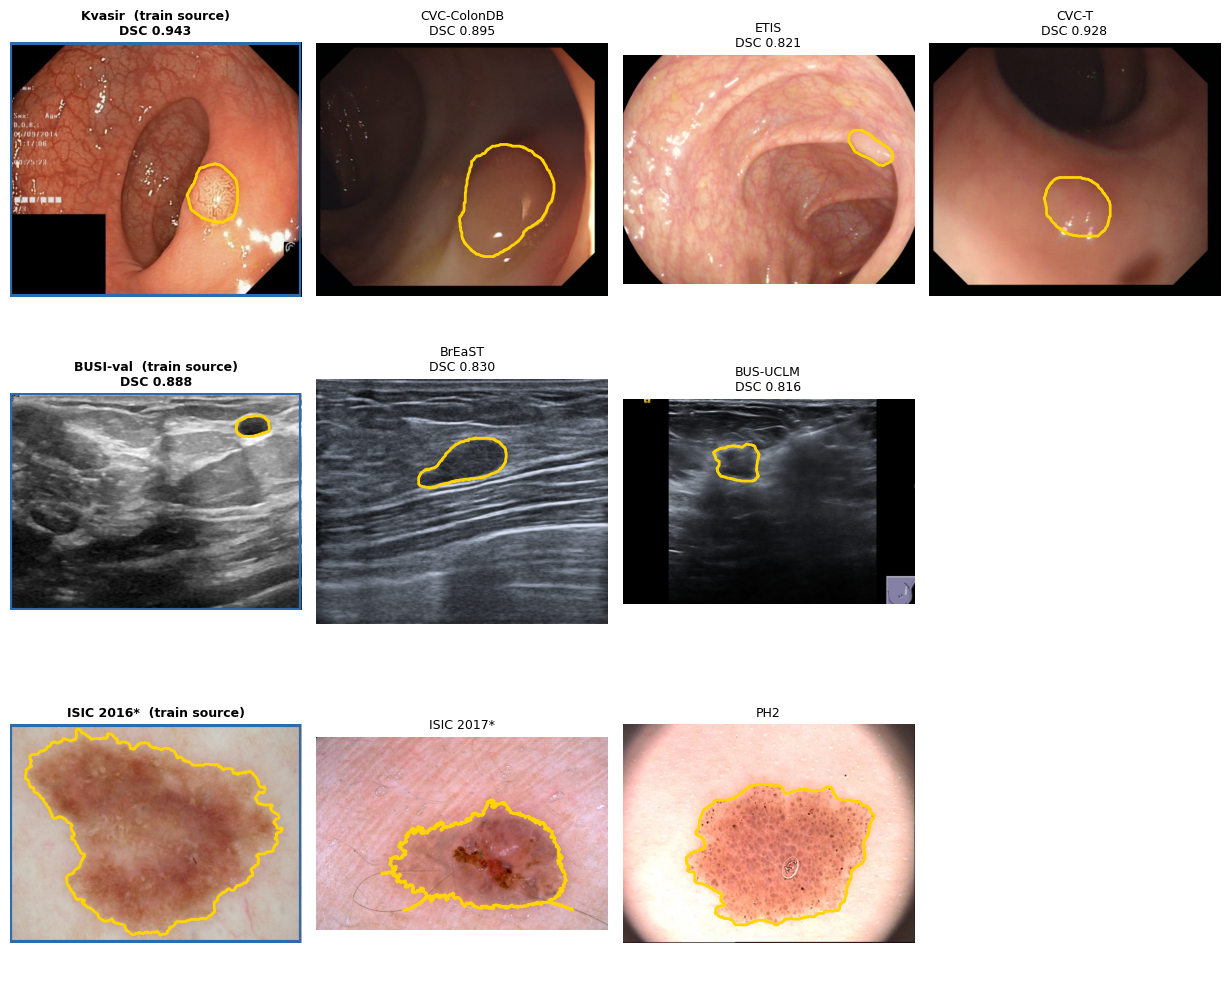

In [ ]:
import numpy as np, matplotlib.pyplot as plt, glob, os
from matplotlib.patches import Rectangle

OUT = '/content/drive/MyDrive/thesis_ckpts/figexamples'

# row order: (domain, [column labels in order])  — first column is the training source
LAYOUT = [
    ('polyp',  ['Kvasir', 'CVC-ColonDB', 'ETIS', 'CVC-T']),
    ('breast', ['BUSI-val', 'BrEaST', 'BUS-UCLM']),
    ('skin',   ['ISIC 2016*', 'ISIC 2017*', 'PH2']),
]

def load(dom, name):
    f = f'{OUT}/{dom}__{name.replace(" ","_").replace("*","star")}.npz'
    return np.load(f, allow_pickle=True) if os.path.exists(f) else None

ncol = max(len(r[1]) for r in LAYOUT)
fig, axes = plt.subplots(len(LAYOUT), ncol, figsize=(3.1 * ncol, 3.4 * len(LAYOUT)))

for r, (dom, names) in enumerate(LAYOUT):
    for c in range(ncol):
        ax = axes[r, c]; ax.axis('off')
        if c >= len(names):
            continue
        z = load(dom, names[c])
        if z is None:
            ax.text(.5, .5, f'missing\n{names[c]}', ha='center', va='center', fontsize=8)
            continue
        ax.imshow(z['image'])
        ax.contour(z['mask'], levels=[0.5], colors=['#ffd400'], linewidths=2.0)
        train = (c == 0)
        t = f"{names[c]}{'  (train source)' if train else ''}"
        v = float(z['dsc'])
        if v == v:
            t += f"\nDSC {v:.3f}"
        ax.set_title(t, fontsize=9, fontweight='bold' if train else 'normal')
        if train:
            ax.add_patch(Rectangle((0, 0), z['image'].shape[1] - 1, z['image'].shape[0] - 1,
                                   fill=False, ec='#2b6cb0', lw=3))
    axes[r, 0].set_ylabel(dom, fontsize=11)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/thesis_ckpts/fig_examples.png', dpi=200, bbox_inches='tight'); plt.show()

In [ ]:
clean_sets['ISIC 2018 (train)'] = ([img_files[i] for i in va], [mask_files[i] for i in va])
print(list(clean_sets.keys()))

['ISIC 2016*', 'ISIC 2017*', 'PH2', 'ISIC 2018 (train)']


In [ ]:
import numpy as np, cv2, os

DOMAIN = 'skin'
OUT    = f'{CKPT}/figexamples'
os.makedirs(OUT, exist_ok=True)

for d in clean_sets:
    imgs, msks = clean_sets[d][0], clean_sets[d][1]
    idx = len(imgs) // 2

    im = cv2.cvtColor(cv2.imread(imgs[idx]), cv2.COLOR_BGR2RGB)
    mk = (cv2.imread(msks[idx], cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
    s = 512 / max(im.shape[:2])
    if s < 1:
        im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        mk = cv2.resize(mk, (im.shape[1], im.shape[0]), interpolation=cv2.INTER_NEAREST)

    np.savez_compressed(f'{OUT}/{DOMAIN}__{d.replace(" ","_").replace("*","star")}.npz',
                        image=im, mask=mk, dsc=float('nan'), setname=d, domain=DOMAIN)
    print(f"{d:20s} idx {idx}  n={len(imgs)}")

ISIC 2016*           idx 134  n=269
ISIC 2017*           idx 86  n=172
PH2                  idx 100  n=200
ISIC 2018 (train)    idx 259  n=519


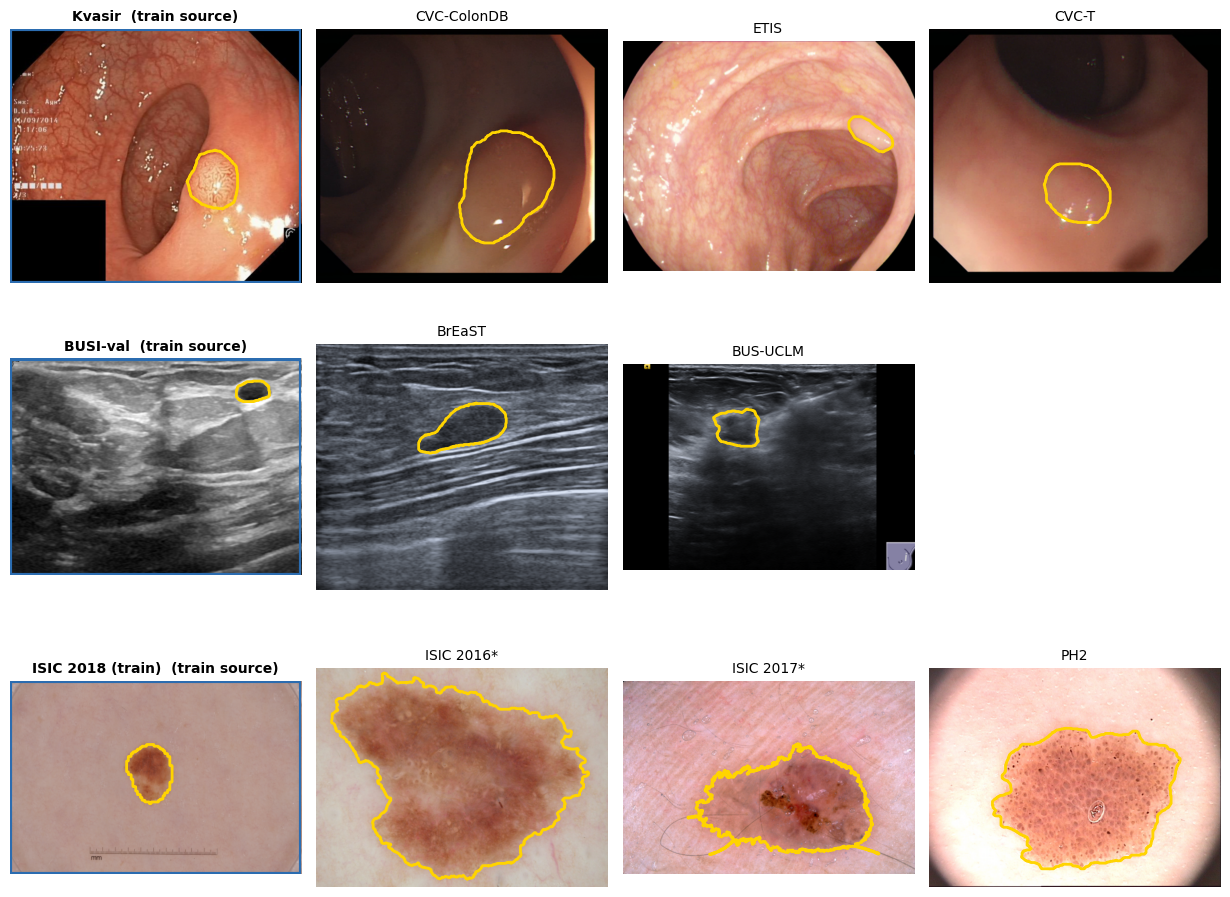

In [ ]:
import numpy as np, matplotlib.pyplot as plt, os
from matplotlib.patches import Rectangle

OUT = f'{CKPT}/figexamples'
LAYOUT = [
    ('polyp',  ['Kvasir', 'CVC-ColonDB', 'ETIS', 'CVC-T']),
    ('breast', ['BUSI-val', 'BrEaST', 'BUS-UCLM']),
    ('skin',   ['ISIC 2018 (train)', 'ISIC 2016*', 'ISIC 2017*', 'PH2']),
]

def load(dom, name):
    f = f'{OUT}/{dom}__{name.replace(" ","_").replace("*","star")}.npz'
    return np.load(f, allow_pickle=True) if os.path.exists(f) else None

ncol = max(len(r[1]) for r in LAYOUT)
fig, axes = plt.subplots(len(LAYOUT), ncol, figsize=(3.1*ncol, 3.2*len(LAYOUT)))

for r, (dom, names) in enumerate(LAYOUT):
    for c in range(ncol):
        ax = axes[r, c]; ax.axis('off')
        if c >= len(names): continue
        z = load(dom, names[c])
        if z is None:
            ax.text(.5, .5, f'missing\n{names[c]}', ha='center', va='center', fontsize=8); continue
        ax.imshow(z['image'])
        ax.contour(z['mask'], levels=[0.5], colors=['#ffd400'], linewidths=2.0)
        train = (c == 0)
        ax.set_title(f"{names[c]}{'  (train source)' if train else ''}",
                     fontsize=10, fontweight='bold' if train else 'normal')
        if train:
            ax.add_patch(Rectangle((0,0), z['image'].shape[1]-1, z['image'].shape[0]-1,
                                   fill=False, ec='#2b6cb0', lw=3))

plt.tight_layout()
plt.savefig(f'{CKPT}/fig_examples.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
import numpy as np, cv2, os

DOMAIN = 'skin'          # 'polyp' | 'breast' | 'skin'
OUT    = f'{CKPT}/figexamples'
os.makedirs(OUT, exist_ok=True)

# Midpoint of each set's file ordering, so the frame is not chosen on appearance.
# Override only where that frame carries an acquisition artefact.
IDX_OVERRIDE = {
    'BUS-UCLM': None,     # <-- i'll put an integer here after picking a cleaner frame
}

for d in clean_sets:
    imgs, msks = clean_sets[d][0], clean_sets[d][1]
    idx = IDX_OVERRIDE.get(d) or len(imgs) // 2

    im = cv2.cvtColor(cv2.imread(imgs[idx]), cv2.COLOR_BGR2RGB)
    mk = (cv2.imread(msks[idx], cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
    s = 512 / max(im.shape[:2])
    if s < 1:
        im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        mk = cv2.resize(mk, (im.shape[1], im.shape[0]), interpolation=cv2.INTER_NEAREST)

    np.savez_compressed(
        f'{OUT}/{DOMAIN}__{d.replace(" ","_").replace("*","star")}.npz',
        image=im, mask=mk, setname=d, domain=DOMAIN, index=idx, n=len(imgs))
    print(f"{d:20s} idx {idx}  n={len(imgs)}")

ISIC 2016*           idx 134  n=269
ISIC 2017*           idx 86  n=172
PH2                  idx 100  n=200
ISIC 2018 (train)    idx 259  n=519


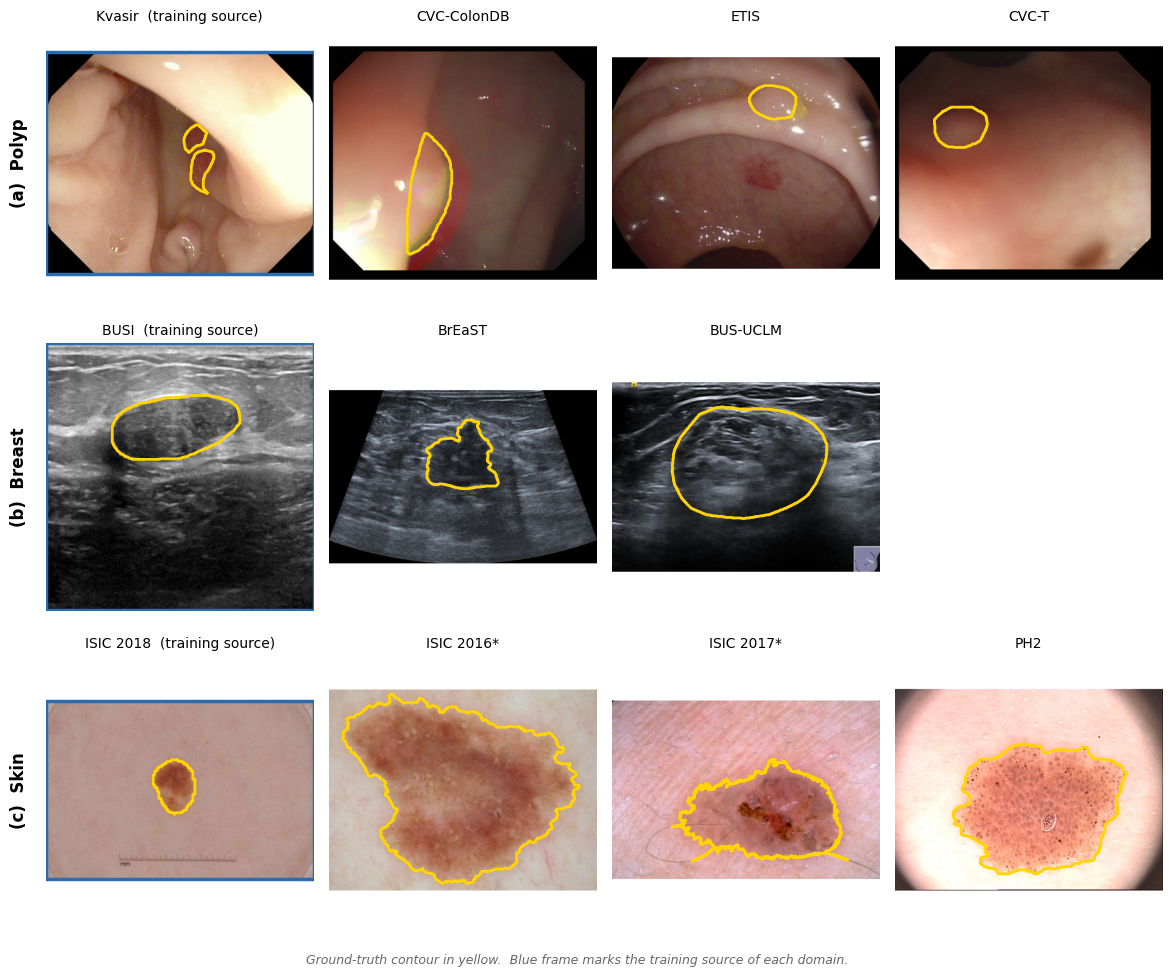

In [ ]:
import numpy as np, matplotlib.pyplot as plt, os
from matplotlib.patches import Rectangle

OUT = f'{CKPT}/figexamples'

LAYOUT = [
    ('polyp',  'Polyp',  ['Kvasir', 'CVC-ColonDB', 'ETIS', 'CVC-T']),
    ('breast', 'Breast', ['BUSI-val', 'BrEaST', 'BUS-UCLM']),
    ('skin',   'Skin',   ['ISIC 2018 (train)', 'ISIC 2016*', 'ISIC 2017*', 'PH2']),
]

DISPLAY = {'BUSI-val': 'BUSI', 'ISIC 2018 (train)': 'ISIC 2018'}

def load(dom, name):
    f = f'{OUT}/{dom}__{name.replace(" ","_").replace("*","star")}.npz'
    return np.load(f, allow_pickle=True) if os.path.exists(f) else None

def pad_square(im, mk):
    """Pad to square so every panel has the same footprint; also return
    where the real image sits inside the padded canvas."""
    h, w = im.shape[:2]
    side = max(h, w)
    top, left = (side - h) // 2, (side - w) // 2
    im_p = np.full((side, side, im.shape[2]), 255, dtype=im.dtype)
    mk_p = np.zeros((side, side), dtype=mk.dtype)
    im_p[top:top+h, left:left+w] = im
    mk_p[top:top+h, left:left+w] = mk
    return im_p, mk_p, (left, top, w, h)

ncol = max(len(r[2]) for r in LAYOUT)
fig, axes = plt.subplots(len(LAYOUT), ncol, figsize=(3.0*ncol, 3.25*len(LAYOUT)))

for r, (dom, row_label, names) in enumerate(LAYOUT):
    for c in range(ncol):
        ax = axes[r, c]
        if c >= len(names):
            ax.remove()
            continue
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)

        z = load(dom, names[c])
        if z is None:
            ax.text(.5, .5, f'missing\n{names[c]}', ha='center', va='center',
                    fontsize=8, transform=ax.transAxes)
            continue

        im, mk, (bx, by, bw, bh) = pad_square(z['image'], z['mask'])
        ax.imshow(im)
        ax.contour(mk, levels=[0.5], colors=['#ffd400'], linewidths=2.0)

        label = DISPLAY.get(names[c], names[c])
        if c == 0:
            label += '  (training source)'
            ax.add_patch(Rectangle((bx - 0.5, by - 0.5), bw, bh, fill=False,
                                   ec='#2b6cb0', lw=2.5, zorder=5))
        ax.set_title(label, fontsize=10, pad=6)

    axes[r, 0].text(-0.10, 0.5, f'({chr(97+r)})  {row_label}',
                    transform=axes[r, 0].transAxes, rotation=90,
                    ha='center', va='center', fontsize=12, fontweight='bold')

fig.text(0.5, 0.005,
         'Ground-truth contour in yellow.  Blue frame marks the training source of each domain.',
         ha='center', fontsize=9, color='#666', style='italic')

plt.tight_layout(rect=[0.02, 0.02, 1, 1])
plt.savefig(f'{CKPT}/fig_3_2_datasets.pdf', bbox_inches='tight')
plt.savefig(f'{CKPT}/fig_3_2_datasets.png', dpi=300, bbox_inches='tight')
plt.show()

wrote fig_3_2_datasets


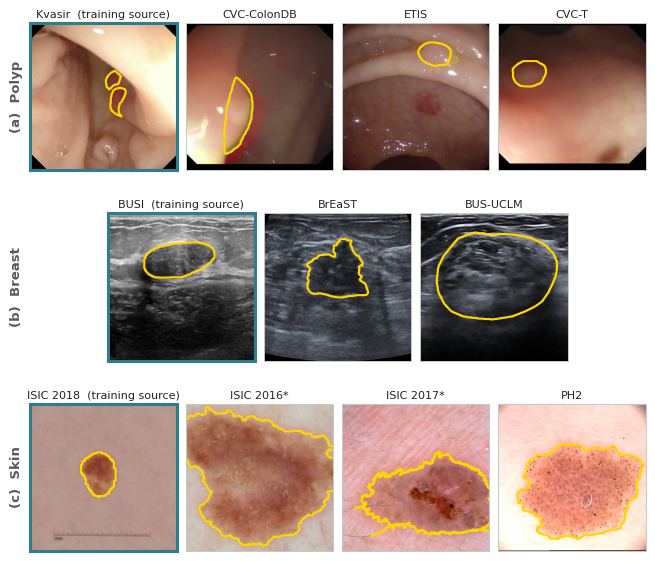

In [ ]:
# new image
import numpy as np, matplotlib.pyplot as plt, os
from matplotlib.patches import Rectangle

OUT = f'{CKPT}/figexamples'

LAYOUT = [
    ('polyp',  'Polyp',  ['Kvasir', 'CVC-ColonDB', 'ETIS', 'CVC-T']),
    ('breast', 'Breast', ['BUSI-val', 'BrEaST', 'BUS-UCLM']),
    ('skin',   'Skin',   ['ISIC 2018 (train)', 'ISIC 2016*', 'ISIC 2017*', 'PH2']),
]
DISPLAY = {'BUSI-val': 'BUSI', 'ISIC 2018 (train)': 'ISIC 2018'}

TRAIN_EC = '#2E7D8F'     # frame on the training source
TILE_EC  = '#C8C8C8'     # border on every other tile
PAD_RGB  = 242           # grey used for padding, visible against white paper
CONTOUR  = '#FFD400'

W_IN   = 6.5             # 16.5 cm text column: draw at final size
N_COLS = 4
GAP_X, GAP_Y = 0.014, 0.052
LEFT, TITLE_H = 0.052, 0.020

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Aptos Body", "Aptos", "Calibri", "DejaVu Sans"],
})


def load(dom, name):
    f = f'{OUT}/{dom}__{name.replace(" ", "_").replace("*", "star")}.npz'
    return np.load(f, allow_pickle=True) if os.path.exists(f) else None


def pad_square(im, mk):
    """Centre-crop to a square so tiles are filled edge to edge."""
    h, w = im.shape[:2]
    s = min(h, w)
    top, left = (h - s) // 2, (w - s) // 2
    return im[top:top+s, left:left+s], mk[top:top+s, left:left+s]


tile_w = (1.0 - LEFT - GAP_X * (N_COLS - 1)) / N_COLS
tile_h_in = tile_w * W_IN
H_IN = (tile_h_in + TITLE_H * W_IN + GAP_Y * W_IN) * len(LAYOUT)

fig = plt.figure(figsize=(W_IN, H_IN))
tile_h = tile_h_in / H_IN
title_h = (TITLE_H * W_IN) / H_IN

for r, (dom, row_label, names) in enumerate(LAYOUT):
    n = len(names)
    row_top = 1.0 - r * (tile_h + title_h + GAP_Y) - title_h
    span = n * tile_w + (n - 1) * GAP_X
    x0 = LEFT + (1.0 - LEFT - span) / 2.0          # centres short rows

    for c, name in enumerate(names):
        ax = fig.add_axes([x0 + c * (tile_w + GAP_X), row_top - tile_h,
                           tile_w, tile_h])
        ax.set_xticks([]); ax.set_yticks([])

        z = load(dom, name)
        if z is None:
            ax.text(.5, .5, f'missing\n{name}', ha='center', va='center',
                    fontsize=8, transform=ax.transAxes)
            continue

        im, mk = pad_square(z['image'], z['mask'])
        ax.imshow(im)
        ax.contour(mk, levels=[0.5], colors=[CONTOUR], linewidths=1.5)

        label = DISPLAY.get(name, name)
        train = (c == 0)
        if train:
            label += '  (training source)'
        for sp in ax.spines.values():
            sp.set_edgecolor(TRAIN_EC if train else TILE_EC)
            sp.set_linewidth(2.2 if train else 0.7)
        ax.set_title(label, fontsize=8, color='#222222', pad=3.5)

    fig.text(LEFT - 0.020, row_top - tile_h / 2, f'({chr(97 + r)})  {row_label}',
             rotation=90, ha='center', va='center',
             fontsize=9.5, fontweight='bold', color='#5A5A5A')

fig.savefig(f'{CKPT}/fig_3_2_datasets.pdf', bbox_inches='tight', pad_inches=0.02)
fig.savefig(f'{CKPT}/fig_3_2_datasets.png', dpi=300, bbox_inches='tight',
            pad_inches=0.02)
print('wrote fig_3_2_datasets')

# bug - eval fix

In [ ]:
# Corrected re-evaluation of the skin capacity axis and BitFit learning-rate
# search: the earlier cells took eval_vec(...)[0], the first image of each set,
# rather than the set mean, and ran without m.eval(). Both fixed here.

from pathlib import Path

ph2_root = Path("/content/data/ph2/PH2Dataset/PH2 Dataset images")
ph2_imgs  = sorted(ph2_root.glob("*/*_Dermoscopic_Image/*.bmp"))
ph2_masks = sorted(ph2_root.glob("*/*_lesion/*.bmp"))
i16 = Path('/content/data/isic2016')
i16_imgs  = sorted((i16/'ISBI2016_ISIC_Part1_Training_Data').glob('*.jpg'))
i16_masks = sorted((i16/'ISBI2016_ISIC_Part1_Training_GroundTruth').glob('*.png'))
i17 = Path('/content/data/isic2017/ISIC2017/test')
i17_imgs  = sorted((i17/'images').glob('*.jpg'))
i17_masks = sorted((i17/'masks').glob('*.png'))

train_ids = {p.stem for p in [img_files[i] for i in tr]}
def clean_subset(imgs, masks):
    pr=[(i,m) for i,m in zip(imgs,masks) if i.stem not in train_ids]
    return [p[0] for p in pr],[p[1] for p in pr]
clean_sets = {'ISIC 2016*':clean_subset(i16_imgs,i16_masks),
              'ISIC 2017*':clean_subset(i17_imgs,i17_masks),
              'PH2':(ph2_imgs,ph2_masks)}

@torch.no_grad()
def eval_vec(m, imgs, masks):
    m.eval()
    ds = ISICDataset(imgs, masks, augment=False)
    loader = DataLoader(ds, batch_size=8, shuffle=False, num_workers=2)
    out=[]
    for images,mks in loader:
        images,mks=images.to(DEVICE),mks.to(DEVICE)
        with torch.amp.autocast('cuda'): lo=m(images)
        d,_=metrics_per_image(lo.float(),mks); out.append(d.cpu())
    return torch.cat(out).numpy()

print(f"2016*:{len(clean_sets['ISIC 2016*'][0])} | "
      f"2017*:{len(clean_sets['ISIC 2017*'][0])} | PH2:{len(ph2_imgs)}")

2016*:269 | 2017*:172 | PH2:200


In [ ]:
sets = list(clean_sets)
print(f"{'':14s}" + "".join(f"{d:>12s}" for d in sets))

for lr in [1e-2, 3e-3, 1e-3, 3e-4]:
    m = DINOv2SegBitFit().to(DEVICE)
    m.load_state_dict(torch.load(f'{CKPT}/bitfit_skin_lr{lr:.0e}_s42.pth'))
    print(f"BitFit {lr:.0e}  " + "".join(f"{eval_vec(m,*clean_sets[d]).mean():12.4f}" for d in sets))
    del m; torch.cuda.empty_cache()

m = DINOv2SegFull().to(DEVICE)
m.load_state_dict(torch.load(f'{CKPT}/full_s42.pth'))
print(f"{'full FT s42':14s}" + "".join(f"{eval_vec(m,*clean_sets[d]).mean():12.4f}" for d in sets))
del m; torch.cuda.empty_cache()

for r in [4, 8, 16, 32]:
    m = DINOv2SegLoRAx(rank=r, target_modules=('query','value')).to(DEVICE)
    m.load_state_dict(torch.load(f'{CKPT}/lora_r{r}_s42.pth'))
    print(f"{'LoRA r='+str(r):14s}" + "".join(f"{eval_vec(m,*clean_sets[d]).mean():12.4f}" for d in sets))
    del m; torch.cuda.empty_cache()

                ISIC 2016*  ISIC 2017*         PH2


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

BitFit 1e-02        0.9187      0.8637      0.9076


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

BitFit 3e-03        0.9198      0.8591      0.9283


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

... (9 outputs left out)

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

LoRA r=16           0.9233      0.8629      0.9236


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

LoRA r=32           0.9246      0.8763      0.9246


In [ ]:
from pathlib import Path
ph2_root = Path("/content/data/ph2/PH2Dataset/PH2 Dataset images")
ph2_imgs = sorted(ph2_root.glob("*/*_Dermoscopic_Image/*.bmp"))
ph2_masks = sorted(ph2_root.glob("*/*_lesion/*.bmp"))
i16 = Path('/content/data/isic2016')
i16_imgs = sorted((i16/'ISBI2016_ISIC_Part1_Training_Data').glob('*.jpg'))
i16_masks = sorted((i16/'ISBI2016_ISIC_Part1_Training_GroundTruth').glob('*.png'))
i17 = Path('/content/data/isic2017/ISIC2017/test')
i17_imgs = sorted((i17/'images').glob('*.jpg'))
i17_masks = sorted((i17/'masks').glob('*.png'))
train_ids = {p.stem for p in [img_files[i] for i in tr]}
def clean_subset(imgs, masks):
      pr = [(i, m) for i, m in zip(imgs, masks) if i.stem not in train_ids]
      return [p[0] for p in pr], [p[1] for p in pr]
clean_sets = {'ISIC 2016*': clean_subset(i16_imgs, i16_masks),
              'ISIC 2017*': clean_subset(i17_imgs, i17_masks),
              'PH2': (ph2_imgs, ph2_masks)}
print({k: len(v[0]) for k, v in clean_sets.items()})   # 269, 172, 200 olmalı

{'ISIC 2016*': 269, 'ISIC 2017*': 172, 'PH2': 200}


In [ ]:
import sys; sys.path.insert(0, '/content/drive/MyDrive/thesis_ckpts')
import extended_eval as ee
df = ee.run_domain('skin', clean_sets, CKPT)

skin: 21 checkpoints, 641 test images, 2026-10-25 21:40, torch 2.11.0+cu130, device cuda
NSD tolerances (fraction of width): 0.00893, 0.01786
plain            plainunet_skin_lr0.003_e100_b16_s42      384px  227.8s  ISIC 2016* 0.9123  ISIC 2017* 0.8336  PH2 0.9167
resunet          resunet_skin_lr0.003_e100_b16_s42        384px   44.0s  ISIC 2016* 0.9084  ISIC 2017* 0.8356  PH2 0.9032


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

lora32_s42       lora_r32_s42                             392px   60.0s  ISIC 2016* 0.9246  ISIC 2017* 0.8763  PH2 0.9246
lora32_s123      lora_r32_s123                            392px   45.5s  ISIC 2016* 0.9225  ISIC 2017* 0.8708  PH2 0.9185
lora32_s2024     lora_r32_s2024                           392px   43.3s  ISIC 2016* 0.9239  ISIC 2017* 0.8703  PH2 0.9309
-- checks after group "main"
  ok   plain | ISIC 2016*                               reported +0.9123  recomputed +0.9123  |dev| 0.0000  (tol 0.0010)
  ok   plain | ISIC 2017*                               reported +0.8336  recomputed +0.8336  |dev| 0.0000  (tol 0.0010)
  ok   plain | PH2                                      reported +0.9167  recomputed +0.9167  |dev| 0.0000  (tol 0.0010)
  ok   resunet | ISIC 2016*                             reported +0.9084  recomputed +0.9084  |dev| 0.0000  (tol 0.0010)
  ok   resunet | ISIC 2017*                             reported +0.8356  recomputed +0.8356  |dev| 0.0000  (tol 0.0010)
